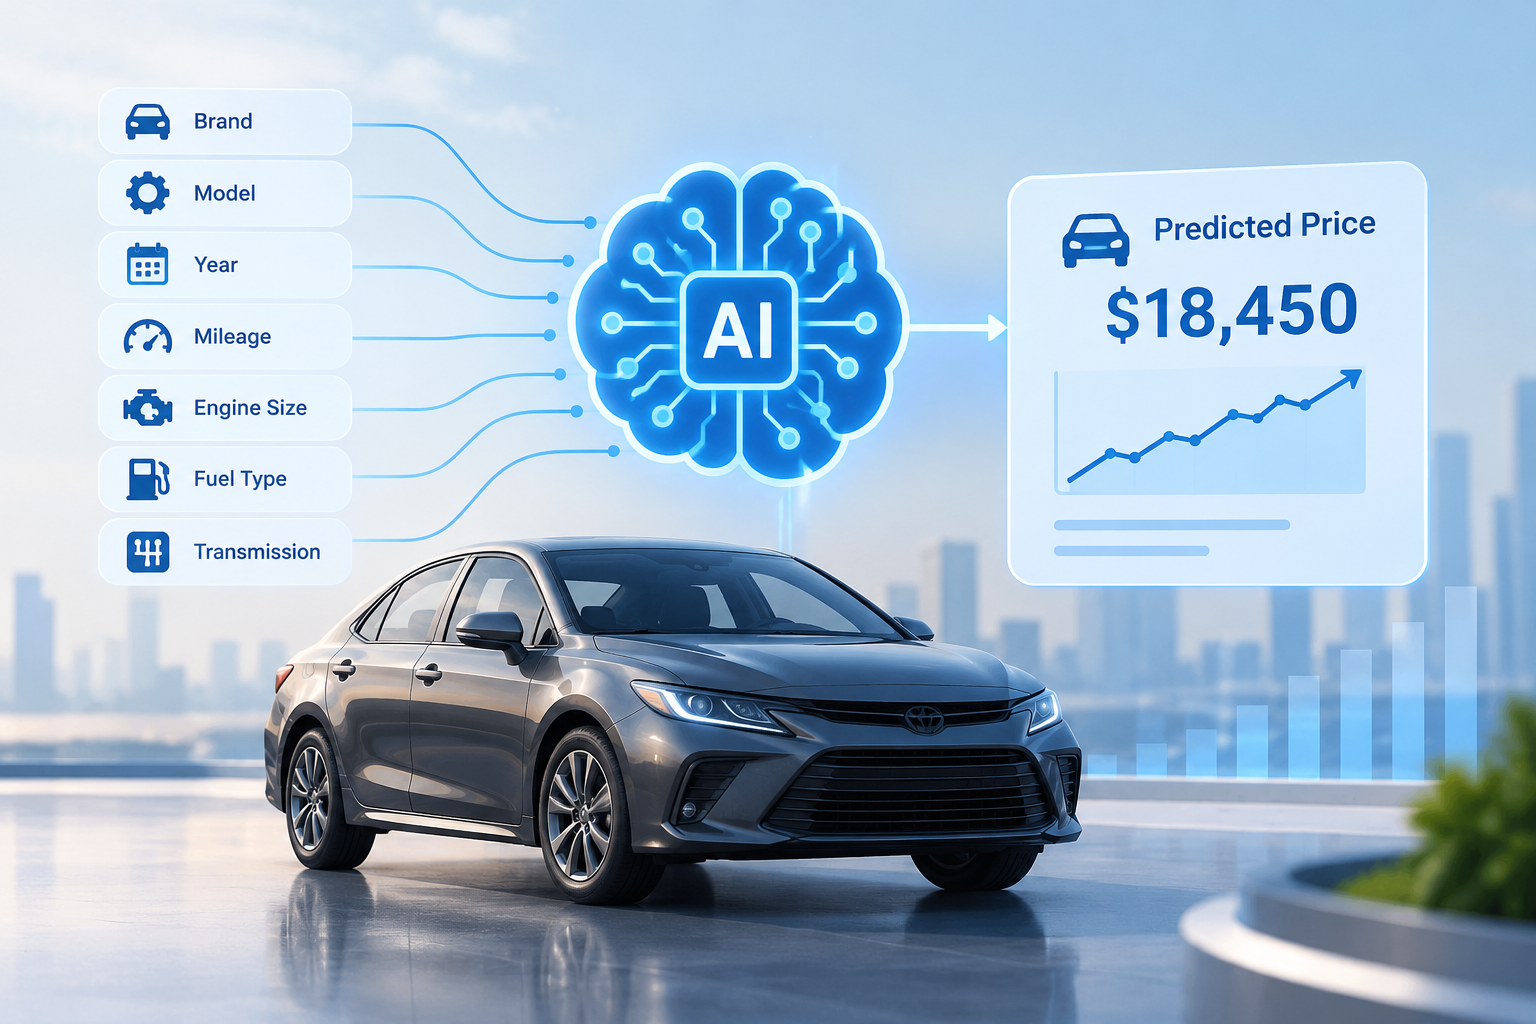

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🚗 Project Objective
</h2>

<p style="font-size:16px; line-height:1.8;">

The main objective of this project is to develop a Machine Learning model that predicts car prices based on various features of vehicles.<br><br>

🔹 <b>Data Analysis:</b> Explore the dataset to understand the relationships between car features and their prices.<br><br>

🔹 <b>Data Preprocessing:</b> Clean and prepare the dataset for training the Machine Learning models.<br><br>

🔹 <b>Model Development:</b> Train and compare different regression algorithms to predict car prices.<br><br>

🔹 <b>Model Evaluation:</b> Evaluate model performance using appropriate metrics to identify the most suitable model.<br><br>

The ultimate goal is to build a reliable model that estimates car prices based on their characteristics.

</p>

</div>

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📚 Importing Libraries
</h2>

<p style="font-size:16px; line-height:1.8;">

🔹 <b>NumPy</b>: Provides efficient numerical operations and supports working with arrays and mathematical computations.<br><br>

🔹 <b>Pandas</b>: Used for loading, cleaning, manipulating, and analyzing structured datasets.<br><br>

🔹 <b>Matplotlib</b>: A visualization library used to create charts and graphs for data analysis.<br><br>

🔹 <b>Seaborn</b>: Built on Matplotlib to produce more attractive and informative statistical visualizations.<br><br>

🔹 <b>Scikit-learn</b>: A machine learning library used for data preprocessing, model training, prediction, and evaluation.

</p>

</div>

In [537]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler , PolynomialFeatures
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold,cross_val_score,cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeCV,LassoCV,ElasticNetCV
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
from statsmodels.stats.diagnostic import normal_ad
import scipy.stats as stats
from statsmodels.stats.stattools import durbin_watson
from sklearn import metrics
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📂 Importing Data
</h2>

<p style="font-size:16px; line-height:1.8;">

The dataset is imported into the notebook using the <b>Pandas</b> library. This step loads the data into a DataFrame, making it ready for exploration, preprocessing, and machine learning analysis.

</p>

</div>

In [240]:
data=pd.read_csv("D:/cardata.csv")
data

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
⚙️ Preprocessing Approach
</h2>

<p style="font-size:16px; line-height:1.8;">

Data preprocessing is not considered a single fixed step in this car price prediction project. 
Instead, preprocessing is performed <b>whenever it is required throughout the data analysis and modeling process</b>. 
Depending on the results of data exploration, visualization, statistical analysis, and model requirements, 
different preprocessing steps may be applied at various stages of the project.

</p>

<p style="font-size:16px; line-height:1.8;">

These steps may include handling missing values, removing duplicate records, correcting data inconsistencies, 
selecting relevant features, encoding categorical variables, and scaling numerical features when necessary. 
Therefore, preprocessing is carried out at the <b>most appropriate point in the workflow</b> to improve data quality, 
prepare the dataset for machine learning algorithms, and support accurate car price prediction.

</p>

</div>

In [241]:
data1=data.drop("Car_Name",axis=1)
data1

,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...
296,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


In [242]:
data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Year           301 non-null    int64  
 1   Selling_Price  301 non-null    float64
 2   Present_Price  301 non-null    float64
 3   Kms_Driven     301 non-null    int64  
 4   Fuel_Type      301 non-null    object 
 5   Seller_Type    301 non-null    object 
 6   Transmission   301 non-null    object 
 7   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 18.9+ KB


In [243]:
data2=pd.get_dummies(data1,columns=['Fuel_Type', 'Seller_Type', 'Transmission'],dtype=int)

In [244]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    301 non-null    int64  
 1   Selling_Price           301 non-null    float64
 2   Present_Price           301 non-null    float64
 3   Kms_Driven              301 non-null    int64  
 4   Owner                   301 non-null    int64  
 5   Fuel_Type_CNG           301 non-null    int64  
 6   Fuel_Type_Diesel        301 non-null    int64  
 7   Fuel_Type_Petrol        301 non-null    int64  
 8   Seller_Type_Dealer      301 non-null    int64  
 9   Seller_Type_Individual  301 non-null    int64  
 10  Transmission_Automatic  301 non-null    int64  
 11  Transmission_Manual     301 non-null    int64  
dtypes: float64(2), int64(10)
memory usage: 28.3 KB


In [245]:
data2.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.627907,2.891554,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.661296,5.082812,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
Kms_Driven,301.0,36947.205980,38886.883882,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.043189,0.247915,0.00,0.0,0.0,0.0,3.0
Fuel_Type_CNG,301.0,0.006645,0.081378,0.00,0.0,0.0,0.0,1.0
Fuel_Type_Diesel,301.0,0.199336,0.400166,0.00,0.0,0.0,0.0,1.0
Fuel_Type_Petrol,301.0,0.794020,0.405089,0.00,1.0,1.0,1.0,1.0
Seller_Type_Dealer,301.0,0.647841,0.478439,0.00,0.0,1.0,1.0,1.0
Seller_Type_Individual,301.0,0.352159,0.478439,0.00,0.0,0.0,1.0,1.0


In [246]:
data2

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_CNG,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Dealer,Seller_Type_Individual,Transmission_Automatic,Transmission_Manual
0,2014,3.35,5.59,27000,0,0,0,1,1,0,0,1
1,2013,4.75,9.54,43000,0,0,1,0,1,0,0,1
2,2017,7.25,9.85,6900,0,0,0,1,1,0,0,1
3,2011,2.85,4.15,5200,0,0,0,1,1,0,0,1
4,2014,4.60,6.87,42450,0,0,1,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
296,2016,9.50,11.60,33988,0,0,1,0,1,0,0,1
297,2015,4.00,5.90,60000,0,0,0,1,1,0,0,1
298,2009,3.35,11.00,87934,0,0,0,1,1,0,0,1
299,2017,11.50,12.50,9000,0,0,1,0,1,0,0,1


In [247]:
data3=data2.drop(["Seller_Type_Individual","Transmission_Automatic"],axis=1)
data3

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_CNG,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Dealer,Transmission_Manual
0,2014,3.35,5.59,27000,0,0,0,1,1,1
1,2013,4.75,9.54,43000,0,0,1,0,1,1
2,2017,7.25,9.85,6900,0,0,0,1,1,1
3,2011,2.85,4.15,5200,0,0,0,1,1,1
4,2014,4.60,6.87,42450,0,0,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...
296,2016,9.50,11.60,33988,0,0,1,0,1,1
297,2015,4.00,5.90,60000,0,0,0,1,1,1
298,2009,3.35,11.00,87934,0,0,0,1,1,1
299,2017,11.50,12.50,9000,0,0,1,0,1,1


<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:12px;">
📊 Data Analysis
</h2>

<h4 style="
color:#1E88E5;
margin-left:30px;
margin-top:0;
margin-bottom:12px;
font-style:italic;
">
➜ Exploring and Understanding the Dataset
</h4>

<p style="
font-size:16px;
line-height:1.8;
margin-left:30px;
">

In this stage, the dataset is carefully analyzed to understand its structure, variables, and overall characteristics. This includes examining the number of rows and columns, data types, statistical information, missing values, duplicate records, and relationships between features. Visualizations and statistical analysis are also used to identify important patterns, distributions, correlations, and possible outliers in the data. These analyses help us better understand the dataset and prepare it for the next stages of the machine learning process.

</p>

</div>


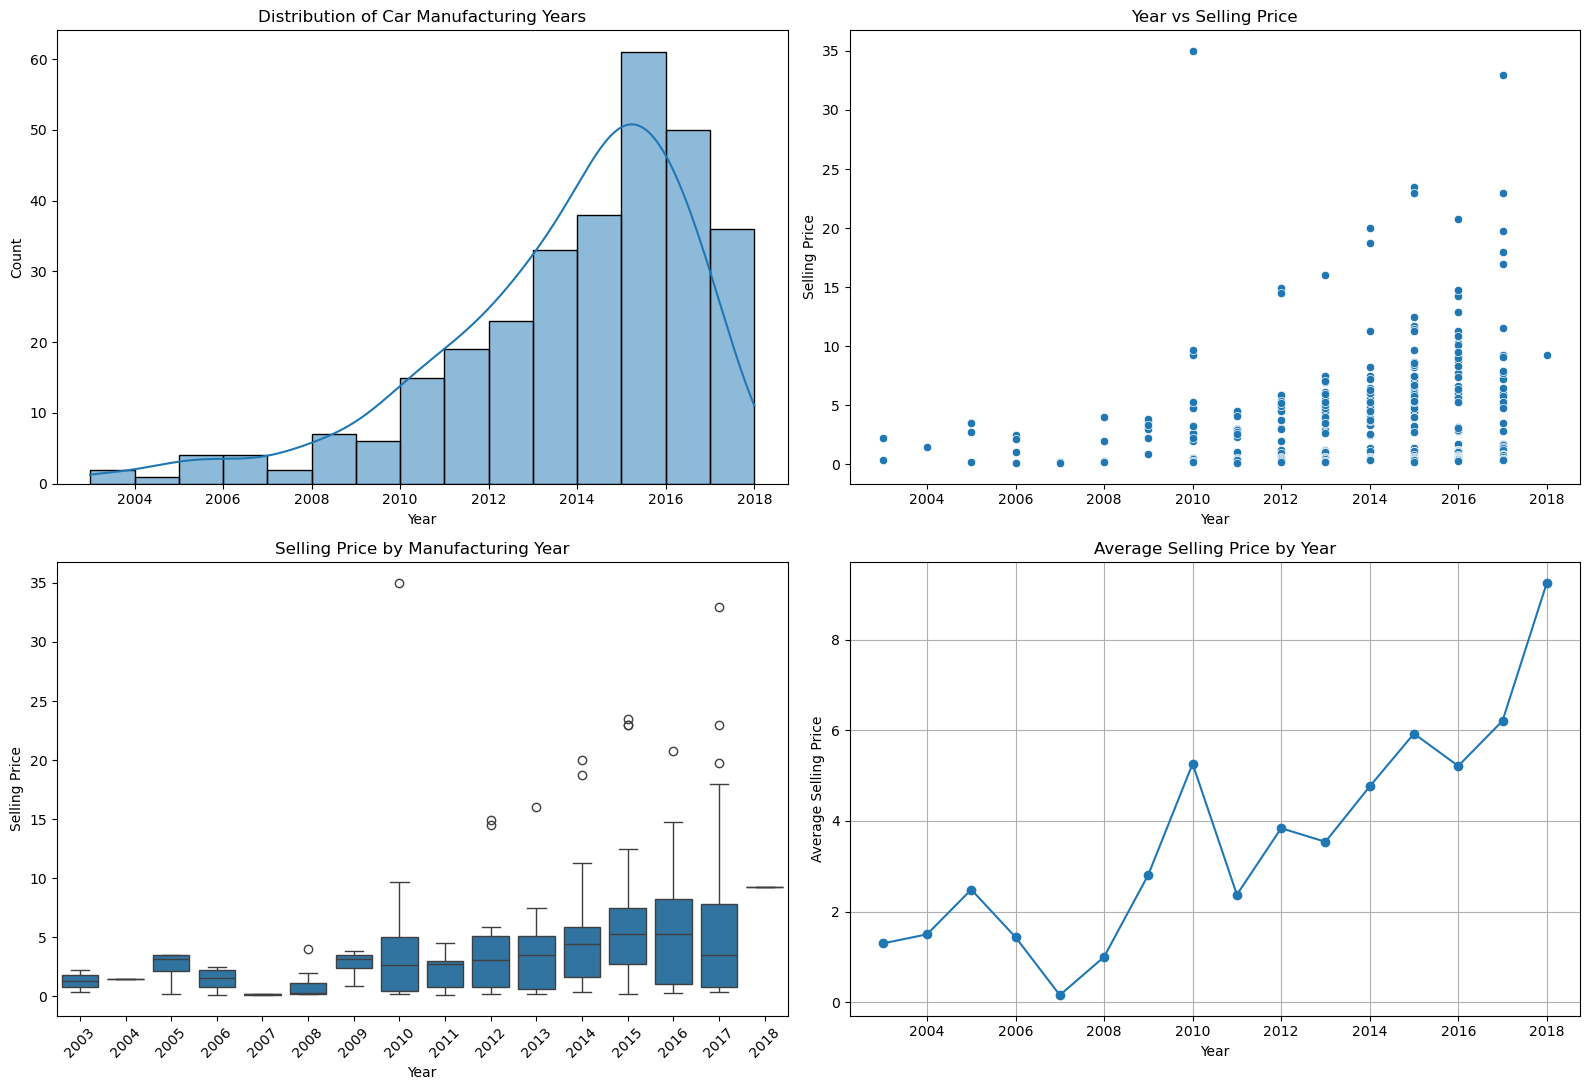

In [248]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Histogram - Distribution of Manufacturing Years
sns.histplot(data=data2, x='Year', bins=15, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Car Manufacturing Years')
axes[0, 0].set_xlabel('Year')
axes[0, 0].set_ylabel('Count')

# 2. Scatter Plot - Year vs Selling Price
sns.scatterplot(data=data2, x='Year', y='Selling_Price', ax=axes[0, 1])
axes[0, 1].set_title('Year vs Selling Price')
axes[0, 1].set_xlabel('Year')
axes[0, 1].set_ylabel('Selling Price')

# 3. Box Plot - Selling Price by Year
sns.boxplot(data=data2, x='Year', y='Selling_Price', ax=axes[1, 0])
axes[1, 0].set_title('Selling Price by Manufacturing Year')
axes[1, 0].set_xlabel('Year')
axes[1, 0].set_ylabel('Selling Price')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Line Plot - Average Selling Price by Year
year_price = data2.groupby('Year')['Selling_Price'].mean()

axes[1, 1].plot(year_price.index, year_price.values, marker='o')
axes[1, 1].set_title('Average Selling Price by Year')
axes[1, 1].set_xlabel('Year')
axes[1, 1].set_ylabel('Average Selling Price')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

**📊 Analysis of Car Manufacturing Year and Selling Price**

The **Manufacturing Year** variable shows a concentration of data between **2010 and 2018**, with the highest customer concentration in **2015 and 2016**. 
The average selling price exhibits fluctuations across the years, showing a **notable jump around 2010** followed by a **steady upward trend from 2013 to 2018**. This indicates that newer car manufacturing years are associated with **higher average selling prices and greater price variance**.

📌 Overall Conclusion
The **Manufacturing Year** variable shows a strong relationship with **Selling Price**, indicating it has **significant predictive power** for the model.

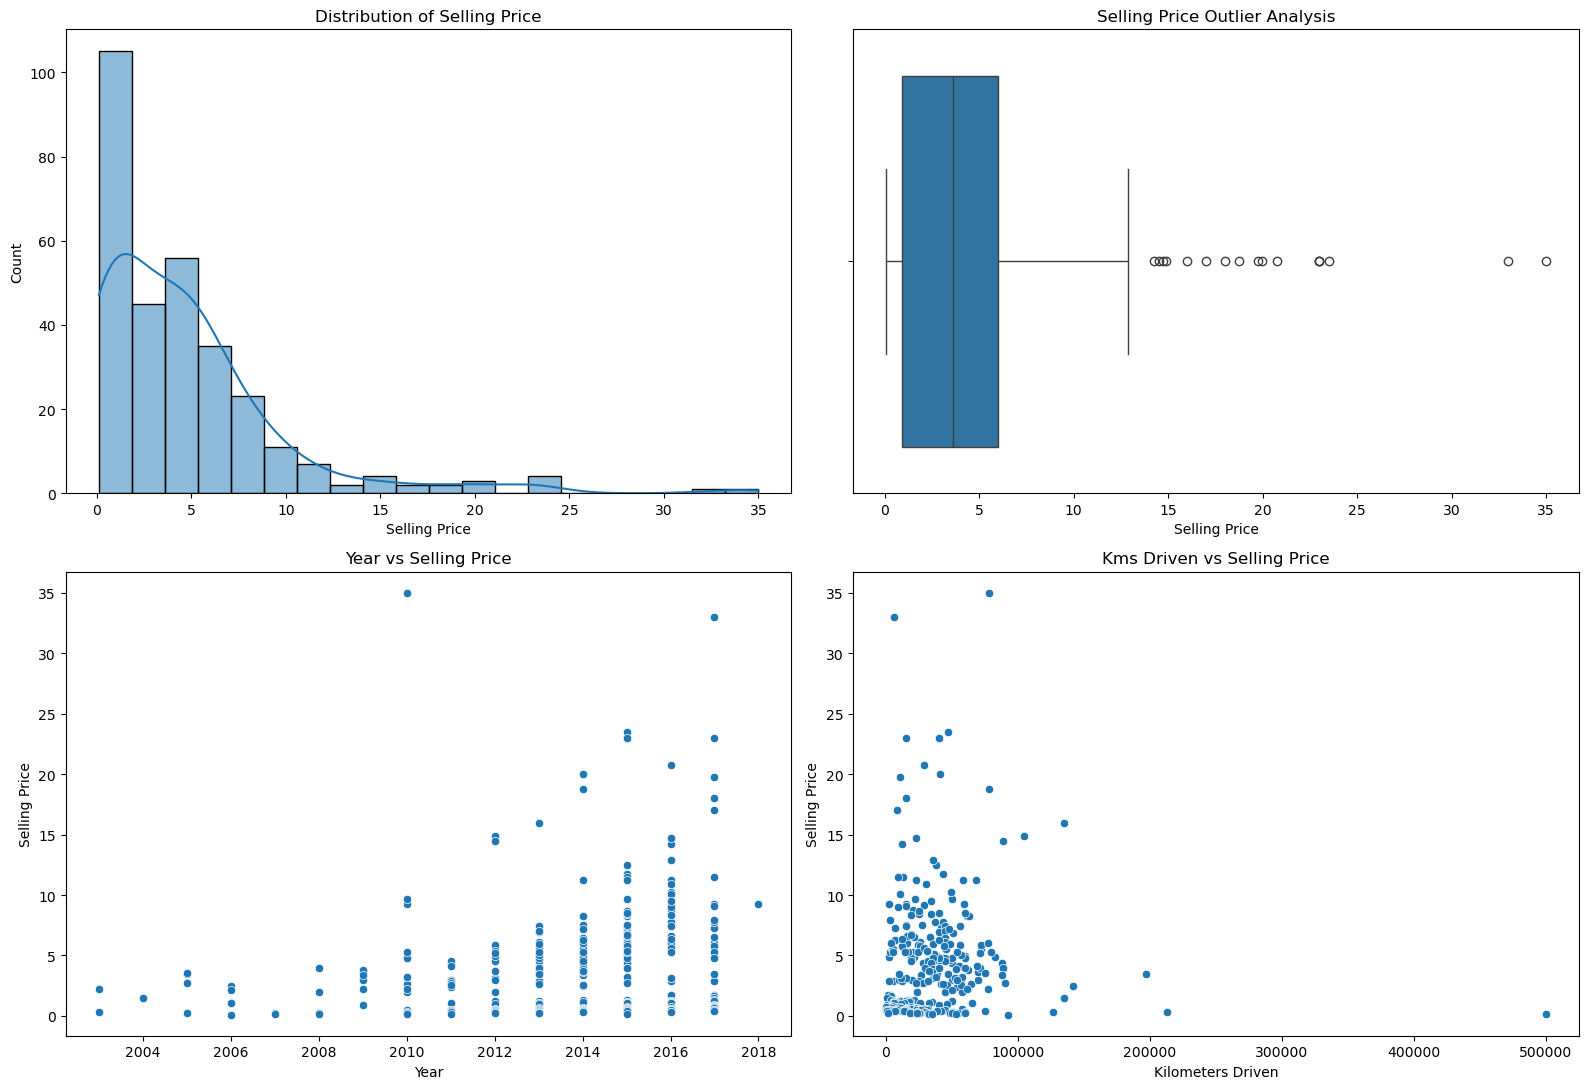

In [249]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Histogram - Distribution of Selling Price
sns.histplot(data=data2, x='Selling_Price', bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Selling Price')
axes[0, 0].set_xlabel('Selling Price')
axes[0, 0].set_ylabel('Count')

# 2. Box Plot - Selling Price
sns.boxplot(data=data2, x='Selling_Price', ax=axes[0, 1])
axes[0, 1].set_title('Selling Price Outlier Analysis')
axes[0, 1].set_xlabel('Selling Price')

# 3. Scatter Plot - Year vs Selling Price
sns.scatterplot(
    data=data2, x='Year', y='Selling_Price', ax=axes[1, 0]
)
axes[1, 0].set_title('Year vs Selling Price')
axes[1, 0].set_xlabel('Year')
axes[1, 0].set_ylabel('Selling Price')

# 4. Scatter Plot - Kms Driven vs Selling Price
sns.scatterplot(
    data=data2, x='Kms_Driven', y='Selling_Price', ax=axes[1, 1]
)
axes[1, 1].set_title('Kms Driven vs Selling Price')
axes[1, 1].set_xlabel('Kilometers Driven')
axes[1, 1].set_ylabel('Selling Price')

plt.tight_layout()
plt.show()

# **📊 Analysis of Selling Price Distribution and Kms Driven**

The **Distribution of Selling Price** and **Selling Price Outlier Analysis** reveal a heavily **right-skewed distribution**, with the vast majority of cars concentrated at lower price points (mostly under **5 to 10 units**). The box plot clearly identifies a significant number of **outliers** extending beyond 15 up to 35 units, representing high-end or luxury vehicles. 

Additionally, the **Kms Driven vs Selling Price** scatter plot shows an inverse relationship, where cars with **higher kilometers driven** generally tend to have **lower selling prices**, though a few expensive models exist even with moderate mileage.

# **📌 Overall Conclusion**
The **Selling Price** target variable requires transformation or careful outlier handling due to its skewed nature, and **Kilometers Driven** serves as a meaningful feature showing that higher mileage negatively impacts the car's market value.

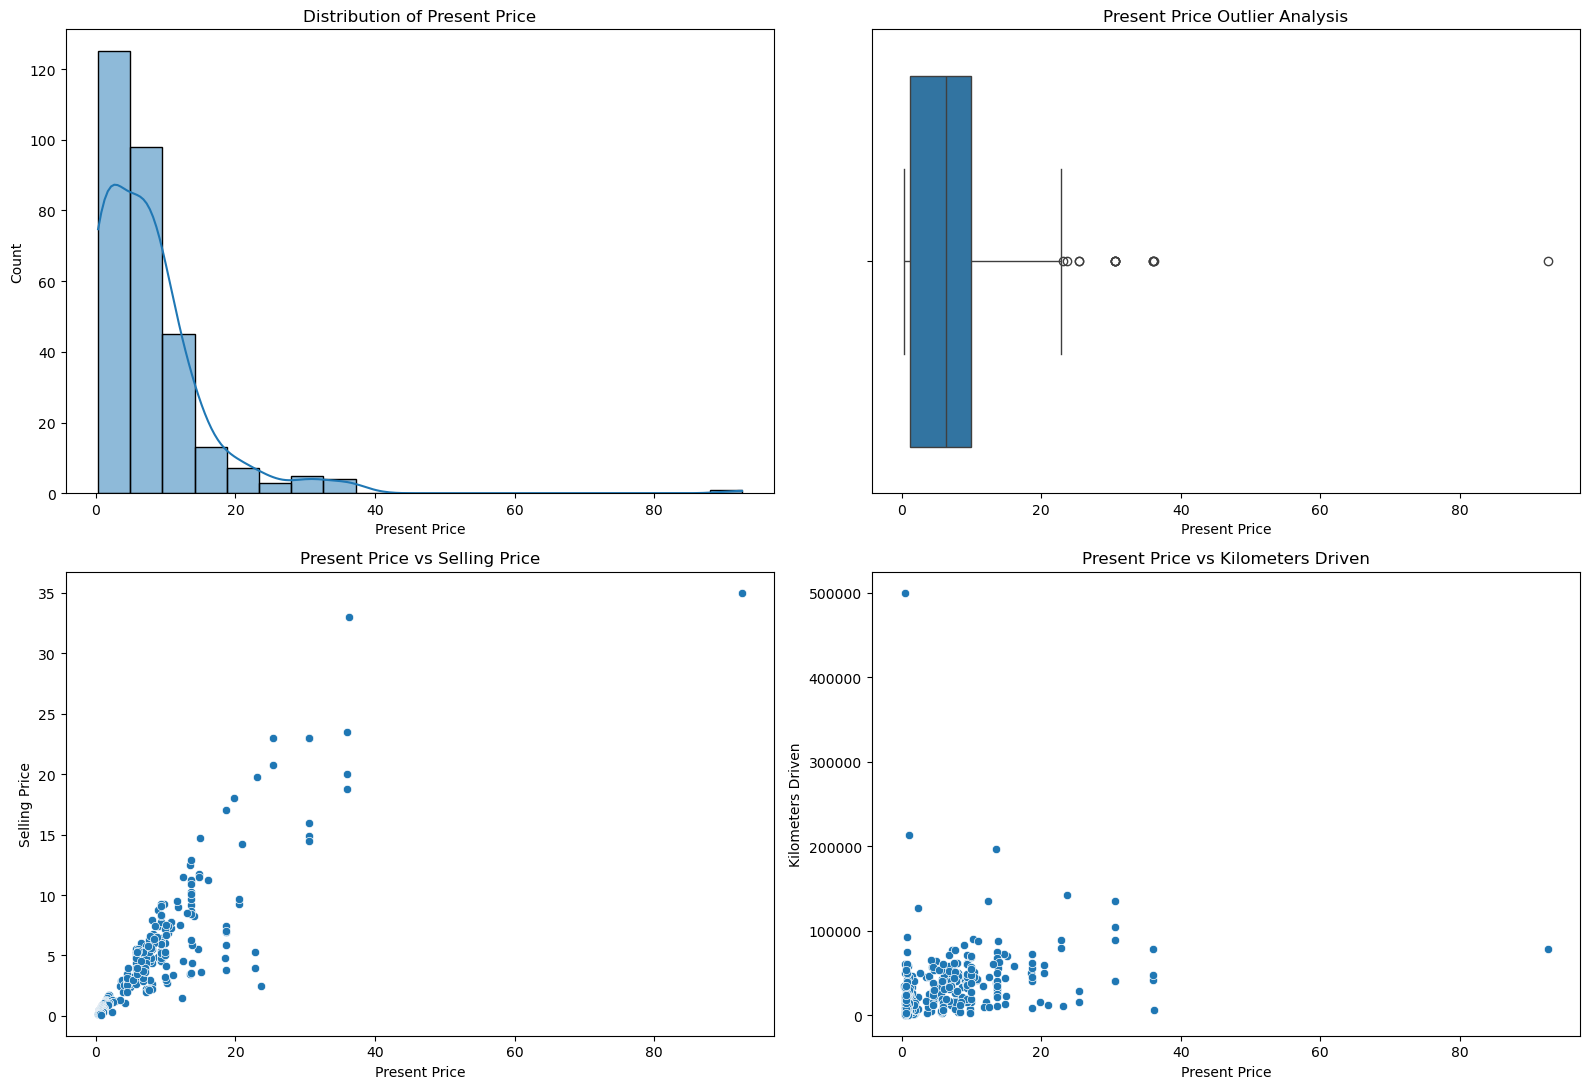

In [250]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Histogram
sns.histplot(
    data=data2, x='Present_Price',
    bins=20, kde=True, ax=axes[0, 0]
)
axes[0, 0].set_title('Distribution of Present Price')
axes[0, 0].set_xlabel('Present Price')
axes[0, 0].set_ylabel('Count')

# 2. Box Plot
sns.boxplot(
    data=data2, x='Present_Price', ax=axes[0, 1]
)
axes[0, 1].set_title('Present Price Outlier Analysis')
axes[0, 1].set_xlabel('Present Price')

# 3. Present Price vs Selling Price
sns.scatterplot(
    data=data2,
    x='Present_Price',
    y='Selling_Price',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Present Price vs Selling Price')
axes[1, 0].set_xlabel('Present Price')
axes[1, 0].set_ylabel('Selling Price')

# 4. Present Price vs Kilometers Driven
sns.scatterplot(
    data=data2,
    x='Present_Price',
    y='Kms_Driven',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Present Price vs Kilometers Driven')
axes[1, 1].set_xlabel('Present Price')
axes[1, 1].set_ylabel('Kilometers Driven')

plt.tight_layout()
plt.show()

# **📊 Analysis of Present Price, Selling Price, and Kilometers Driven**

The **Distribution of Present Price** and **Present Price Outlier Analysis** illustrate a strongly **right-skewed distribution**, where the vast majority of current car prices cluster below **20 units**. The box plot highlights a few distinct **outliers** extending past 40 and reaching up to nearly 90 units, pointing to high-value vehicles.

Furthermore, the **Present Price vs Selling Price** scatter plot demonstrates a **strong positive correlation**, showing that higher present prices reliably translate to higher selling prices. In contrast, the **Present Price vs Kilometers Driven** plot displays no strong direct pattern, though high-mileage cars are mostly clustered at lower present price ranges.

# **📌 Overall Conclusion**
The **Present Price** variable serves as an exceptionally **powerful predictor** for the model, showing a direct linear relationship with the target variable (Selling Price), while requiring careful treatment for upper-range outliers.

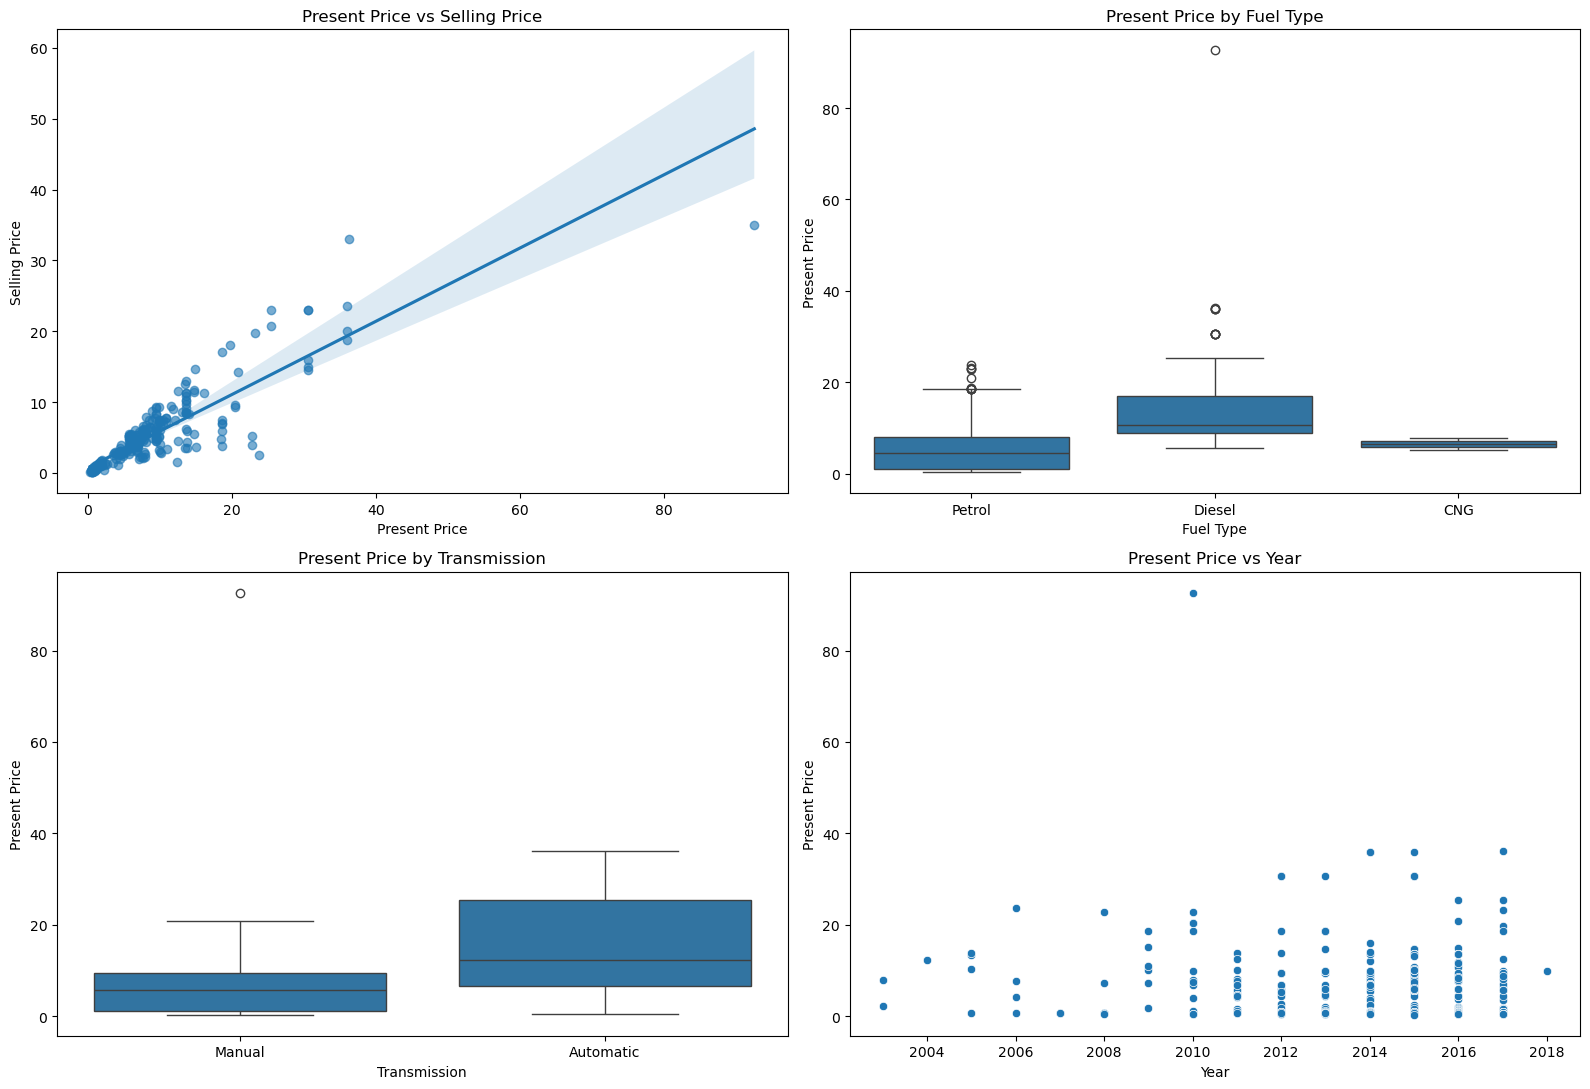

In [251]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Present Price vs Selling Price
sns.regplot(
    data=data2,
    x='Present_Price',
    y='Selling_Price',
    ax=axes[0, 0],
    scatter_kws={'alpha': 0.6}
)
axes[0, 0].set_title('Present Price vs Selling Price')
axes[0, 0].set_xlabel('Present Price')
axes[0, 0].set_ylabel('Selling Price')

# 2. Present Price by Fuel Type
data2['Fuel_Type'] = np.select(
    [
        data2['Fuel_Type_CNG'] == 1,
        data2['Fuel_Type_Diesel'] == 1,
        data2['Fuel_Type_Petrol'] == 1
    ],
    ['CNG', 'Diesel', 'Petrol'],
    default='Unknown'
)

sns.boxplot(
    data=data2,
    x='Fuel_Type',
    y='Present_Price',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Present Price by Fuel Type')
axes[0, 1].set_xlabel('Fuel Type')
axes[0, 1].set_ylabel('Present Price')

# 3. Present Price by Transmission
data2['Transmission'] = np.select(
    [
        data2['Transmission_Automatic'] == 1,
        data2['Transmission_Manual'] == 1
    ],
    ['Automatic', 'Manual'],
    default='Unknown'
)

sns.boxplot(
    data=data2,
    x='Transmission',
    y='Present_Price',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Present Price by Transmission')
axes[1, 0].set_xlabel('Transmission')
axes[1, 0].set_ylabel('Present Price')

# 4. Present Price vs Year
sns.scatterplot(
    data=data2,
    x='Year',
    y='Present_Price',
    ax=axes[1, 1]
)
axes[1, 1].set_title('Present Price vs Year')
axes[1, 1].set_xlabel('Year')
axes[1, 1].set_ylabel('Present Price')

plt.tight_layout()
plt.show()

# **📊 Analysis of Present Price, Fuel Type, Transmission, and Year**

The **Present Price vs Selling Price** and **Present Price by Fuel Type** plots reveal a strong linear relationship between current and selling prices, while showing that **Diesel** cars generally have a higher present price median and wider variance compared to **Petrol** and **CNG** vehicles. 

Additionally, the **Present Price by Transmission** box plot indicates that **Automatic** cars tend to have a higher median present price and broader interquartile range than **Manual** vehicles. Finally, the **Present Price vs Year** scatter plot demonstrates that higher-priced present models are predominantly found in more recent manufacturing years.

# **📌 Overall Conclusion**
Features like **Fuel Type**, **Transmission**, and **Present Price** combined with the manufacturing **Year** provide vital segmentation and robust predictive signals for estimating vehicle market values.

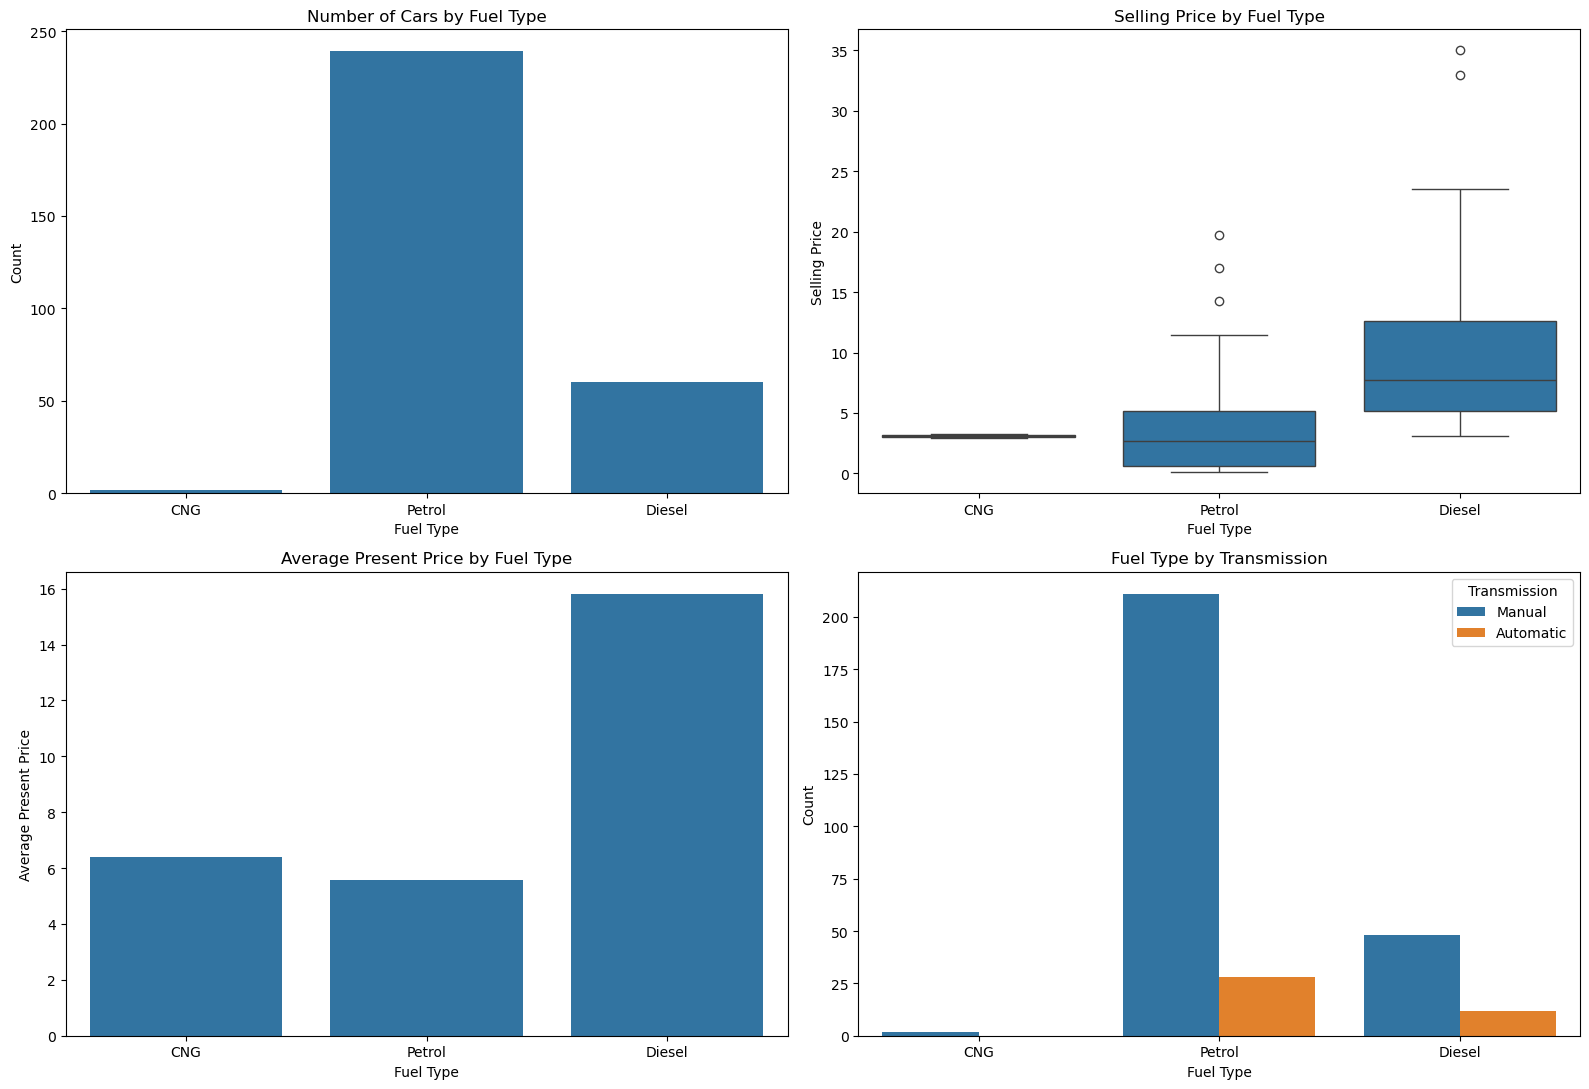

In [252]:
# Reconstruct Fuel_Type from One-Hot Encoded Columns
data2['Fuel_Type'] = np.select(
    [
        data2['Fuel_Type_CNG'] == 1,
        data2['Fuel_Type_Diesel'] == 1,
        data2['Fuel_Type_Petrol'] == 1
    ],
    ['CNG', 'Diesel', 'Petrol'],
    default='Unknown'
)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Count Plot
sns.countplot(
    data=data2,
    x='Fuel_Type',
    order=['CNG', 'Petrol', 'Diesel'],
    ax=axes[0, 0]
)
axes[0, 0].set_title('Number of Cars by Fuel Type')
axes[0, 0].set_xlabel('Fuel Type')
axes[0, 0].set_ylabel('Count')

# 2. Selling Price by Fuel Type
sns.boxplot(
    data=data2,
    x='Fuel_Type',
    y='Selling_Price',
    order=['CNG', 'Petrol', 'Diesel'],
    ax=axes[0, 1]
)
axes[0, 1].set_title('Selling Price by Fuel Type')
axes[0, 1].set_xlabel('Fuel Type')
axes[0, 1].set_ylabel('Selling Price')

# 3. Present Price by Fuel Type
sns.barplot(
    data=data2,
    x='Fuel_Type',
    y='Present_Price',
    order=['CNG', 'Petrol', 'Diesel'],
    errorbar=None,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Average Present Price by Fuel Type')
axes[1, 0].set_xlabel('Fuel Type')
axes[1, 0].set_ylabel('Average Present Price')

# 4. Fuel Type vs Transmission
sns.countplot(
    data=data2,
    x='Fuel_Type',
    hue='Transmission',
    order=['CNG', 'Petrol', 'Diesel'],
    ax=axes[1, 1]
)
axes[1, 1].set_title('Fuel Type by Transmission')
axes[1, 1].set_xlabel('Fuel Type')
axes[1, 1].set_ylabel('Count')
axes[1, 1].legend(title='Transmission')

plt.tight_layout()
plt.show()

# **📊 Analysis of Fuel Type, Selling Price, and Transmission**

The **Number of Cars by Fuel Type** and **Selling Price by Fuel Type** charts indicate that **Petrol** cars dominate the dataset in terms of count, whereas **Diesel** cars exhibit a significantly higher median selling price and wider interquartile range. **CNG** vehicles represent a very small minority with consistently lower selling prices.

Additionally, the **Average Present Price by Fuel Type** shows that diesel variants command a much higher average present price than petrol and CNG. The **Fuel Type by Transmission** plot further reveals that **Manual** transmission heavily outnumbers **Automatic** across both petrol and diesel categories.

# **📌 Overall Conclusion**
**Fuel Type** is a powerful categorical predictor, where diesel models generally represent higher-end valuations, and transmission distribution highlights a heavy market preference for manual cars.

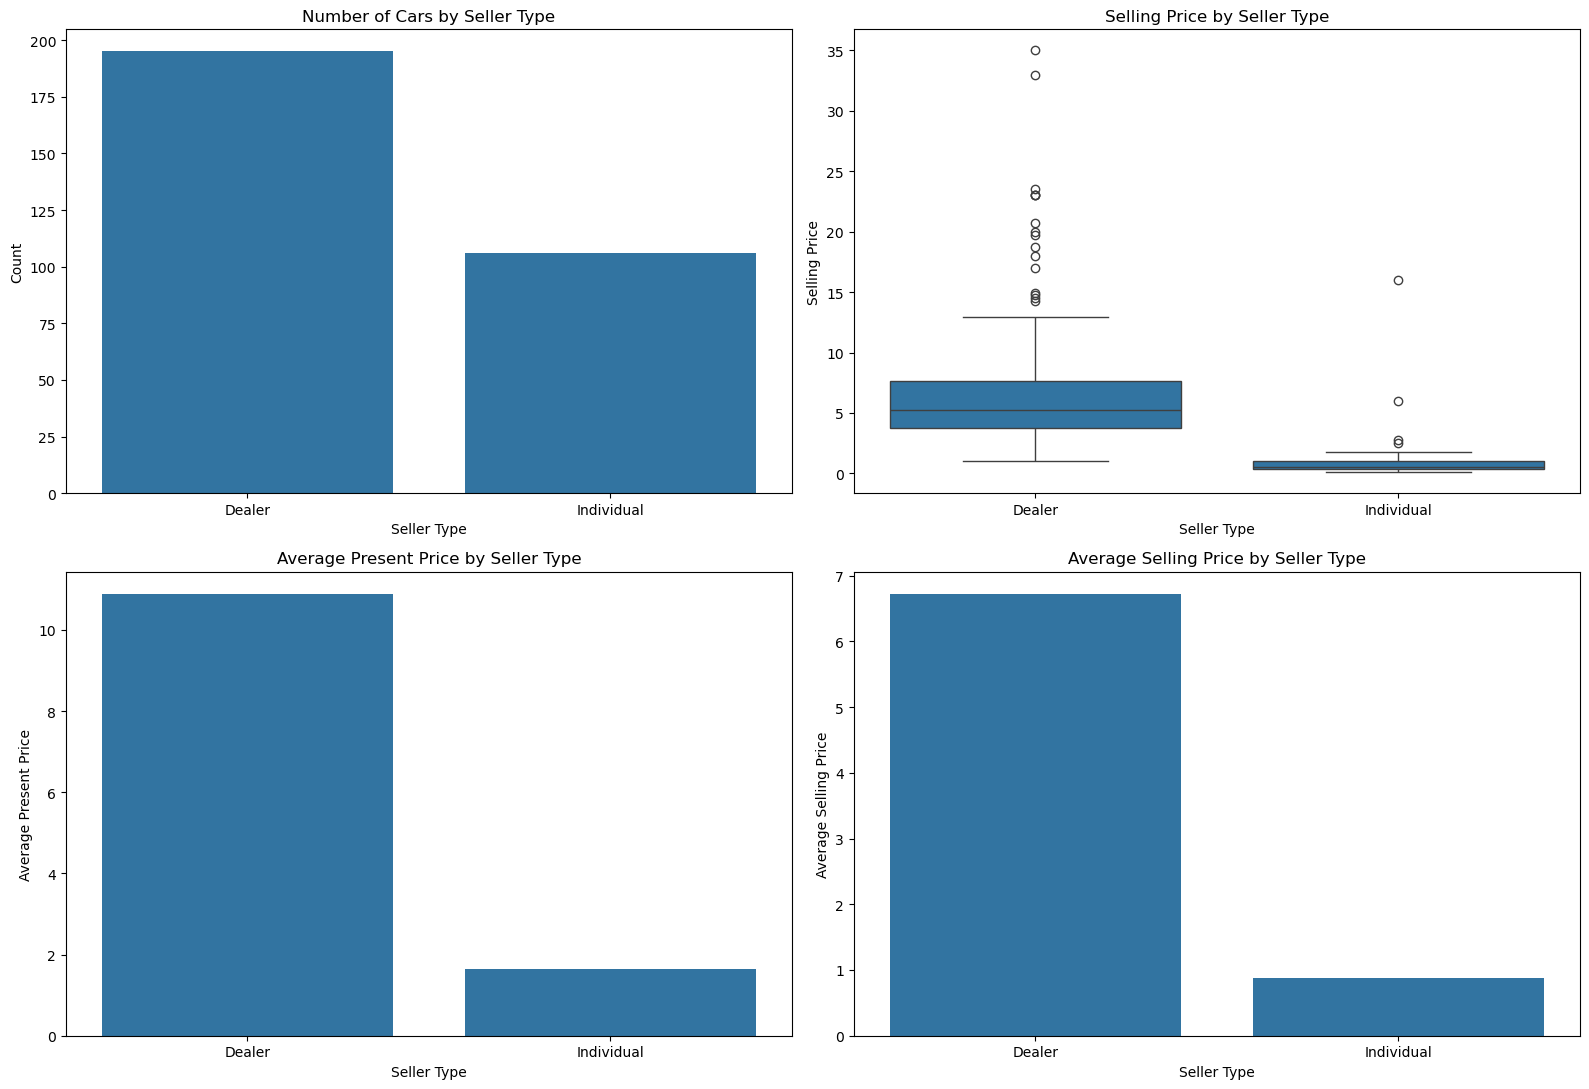

In [253]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Reconstruct Seller_Type
data2['Seller_Type'] = np.where(
    data2['Seller_Type_Dealer'] == 1,
    'Dealer',
    'Individual'
)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Number of Cars by Seller Type
sns.countplot(data=data2, x='Seller_Type', ax=axes[0, 0])
axes[0, 0].set_title('Number of Cars by Seller Type')
axes[0, 0].set_xlabel('Seller Type')
axes[0, 0].set_ylabel('Count')

# 2. Selling Price by Seller Type
sns.boxplot(
    data=data2, x='Seller_Type',
    y='Selling_Price', ax=axes[0, 1]
)
axes[0, 1].set_title('Selling Price by Seller Type')
axes[0, 1].set_xlabel('Seller Type')
axes[0, 1].set_ylabel('Selling Price')

# 3. Present Price by Seller Type
sns.barplot(
    data=data2, x='Seller_Type',
    y='Present_Price', errorbar=None, ax=axes[1, 0]
)
axes[1, 0].set_title('Average Present Price by Seller Type')
axes[1, 0].set_xlabel('Seller Type')
axes[1, 0].set_ylabel('Average Present Price')

# 4. Average Selling Price by Seller Type
sns.barplot(
    data=data2, x='Seller_Type',
    y='Selling_Price', errorbar=None, ax=axes[1, 1]
)
axes[1, 1].set_title('Average Selling Price by Seller Type')
axes[1, 1].set_xlabel('Seller Type')
axes[1, 1].set_ylabel('Average Selling Price')

plt.tight_layout()
plt.show()


# **📊 Analysis of Seller Type, Present Price, and Selling Price**

The **Number of Cars by Seller Type** and **Selling Price by Seller Type** charts show that **Dealer** listings outnumber **Individual** listings in the dataset. Furthermore, cars sold by dealers exhibit a significantly higher median selling price, wider price variance, and numerous high-end outliers compared to individual sellers.

Additionally, the **Average Present Price by Seller Type** and **Average Selling Price by Seller Type** bar charts confirm that vehicles handled by dealers command substantially higher average present and selling prices than those sold directly by individuals.

# **📌 Overall Conclusion**
**Seller Type** serves as an influential categorical feature for the model, clearly demonstrating that dealer-listed vehicles are associated with higher market valuations and more expensive inventory.

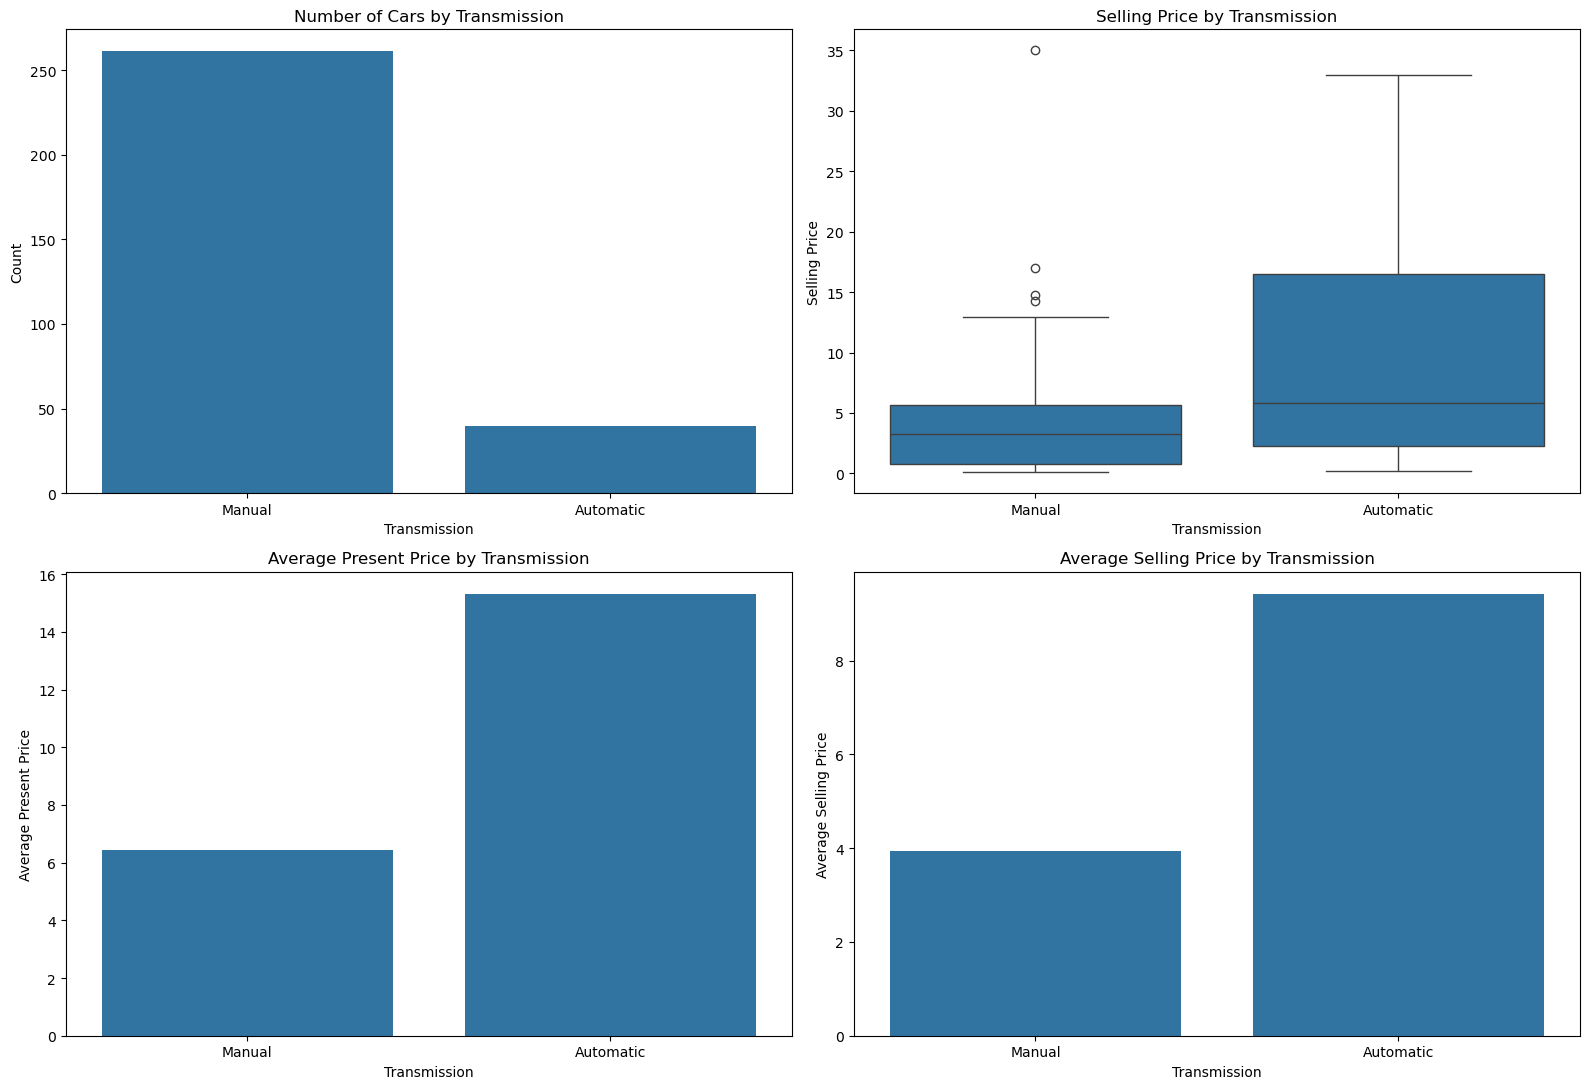

In [254]:
# Reconstruct Transmission
data2['Transmission'] = np.where(
    data2['Transmission_Manual'] == 1,
    'Manual',
    'Automatic'
)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Number of Cars by Transmission
sns.countplot(
    data=data2, x='Transmission', ax=axes[0, 0]
)
axes[0, 0].set_title('Number of Cars by Transmission')
axes[0, 0].set_xlabel('Transmission')
axes[0, 0].set_ylabel('Count')

# 2. Selling Price by Transmission
sns.boxplot(
    data=data2,
    x='Transmission',
    y='Selling_Price',
    ax=axes[0, 1]
)
axes[0, 1].set_title('Selling Price by Transmission')
axes[0, 1].set_xlabel('Transmission')
axes[0, 1].set_ylabel('Selling Price')

# 3. Present Price by Transmission
sns.barplot(
    data=data2,
    x='Transmission',
    y='Present_Price',
    errorbar=None,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Average Present Price by Transmission')
axes[1, 0].set_xlabel('Transmission')
axes[1, 0].set_ylabel('Average Present Price')

# 4. Average Selling Price by Transmission
sns.barplot(
    data=data2,
    x='Transmission',
    y='Selling_Price',
    errorbar=None,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Average Selling Price by Transmission')
axes[1, 1].set_xlabel('Transmission')
axes[1, 1].set_ylabel('Average Selling Price')

plt.tight_layout()
plt.show()

# **📊 Analysis of Transmission Type, Present Price, and Selling Price**

The **Number of Cars by Transmission** chart shows that **Manual** transmission cars heavily dominate the dataset in terms of count, while **Automatic** cars form a much smaller group. However, the **Selling Price by Transmission** box plot indicates that **Automatic** vehicles exhibit a significantly higher median selling price, broader interquartile range, and a higher maximum value compared to manual cars.

Additionally, the **Average Present Price by Transmission** and **Average Selling Price by Transmission** bar charts confirm that automatic transmission vehicles command substantially higher average present and selling prices than manual vehicles.

# **📌 Overall Conclusion**
**Transmission** type is a highly impactful categorical feature for the model, clearly demonstrating that automatic cars are associated with luxury or higher-end market valuations despite their lower frequency in the dataset.

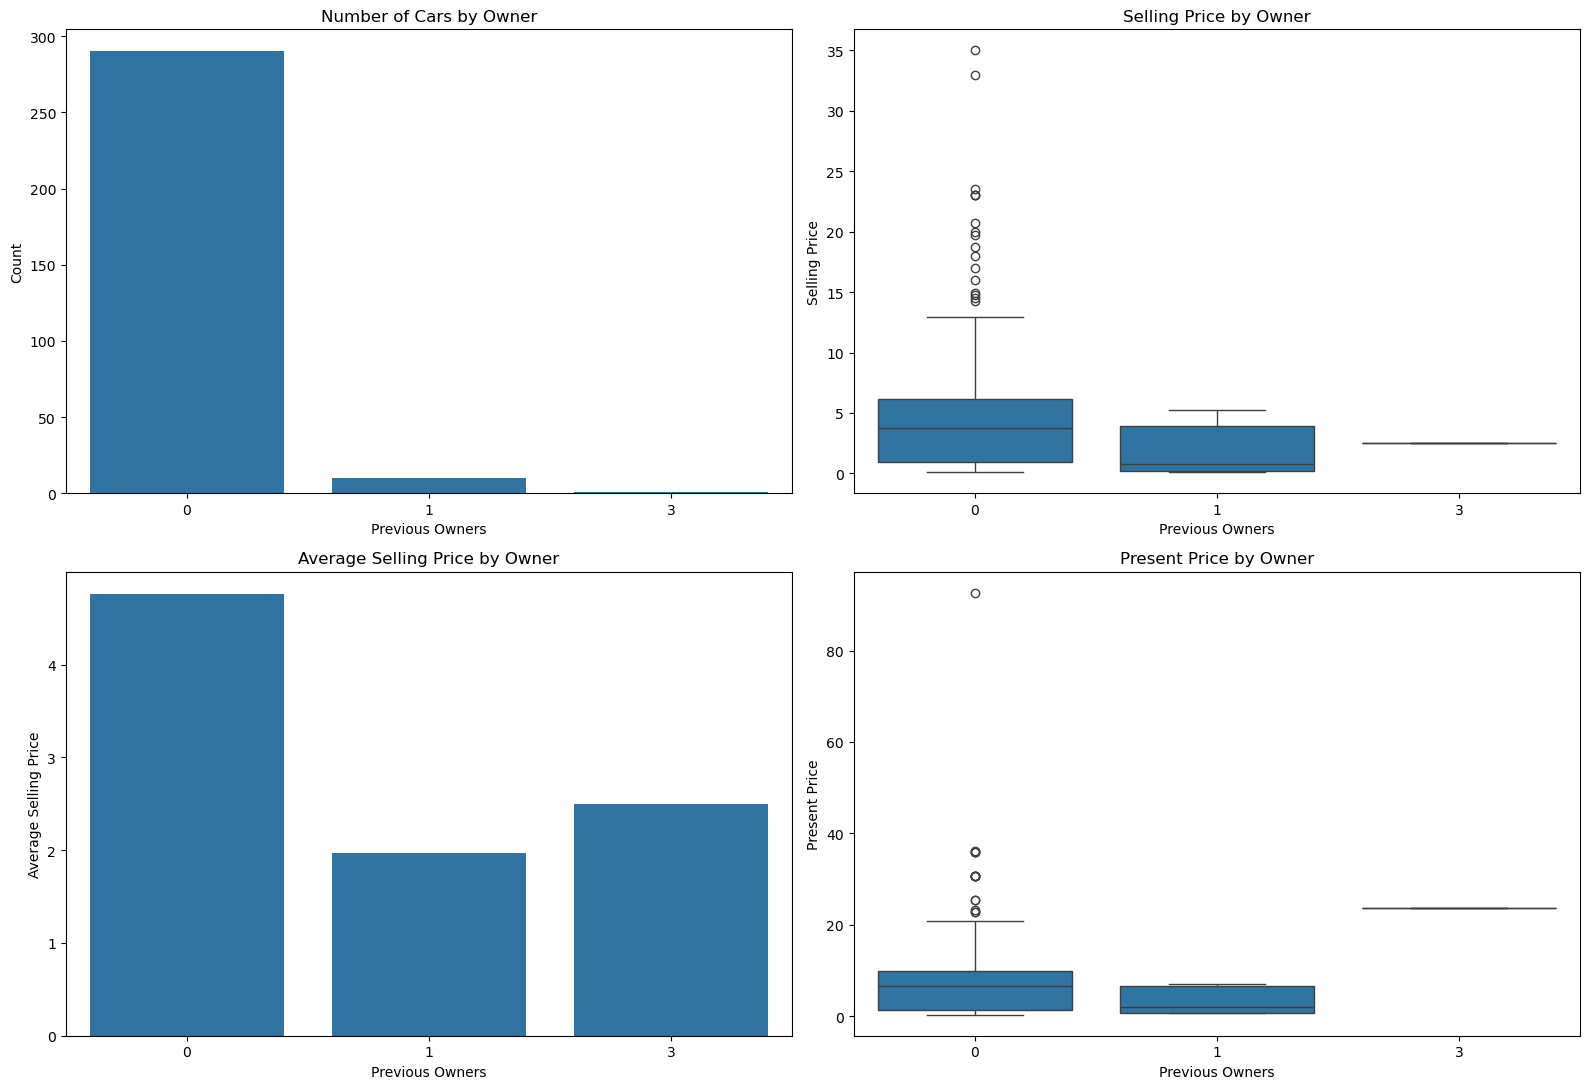

In [255]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Number of cars by Owner
sns.countplot(data=data2, x='Owner', ax=axes[0, 0])
axes[0, 0].set_title('Number of Cars by Owner')
axes[0, 0].set_xlabel('Previous Owners')
axes[0, 0].set_ylabel('Count')

# 2. Selling Price by Owner
sns.boxplot(data=data2, x='Owner', y='Selling_Price', ax=axes[0, 1])
axes[0, 1].set_title('Selling Price by Owner')
axes[0, 1].set_xlabel('Previous Owners')
axes[0, 1].set_ylabel('Selling Price')

# 3. Average Selling Price by Owner
sns.barplot(
    data=data2,
    x='Owner',
    y='Selling_Price',
    errorbar=None,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Average Selling Price by Owner')
axes[1, 0].set_xlabel('Previous Owners')
axes[1, 0].set_ylabel('Average Selling Price')

# 4. Present Price by Owner
sns.boxplot(data=data2, x='Owner', y='Present_Price', ax=axes[1, 1])
axes[1, 1].set_title('Present Price by Owner')
axes[1, 1].set_xlabel('Previous Owners')
axes[1, 1].set_ylabel('Present Price')

plt.tight_layout()
plt.show()

# **📊 Analysis of Previous Owners, Selling Price, and Present Price**

The **Number of Cars by Owner** chart demonstrates a massive imbalance, where vehicles with **0 previous owners** (first-hand cars) represent the vast majority of the dataset, while cars with **1 or 3 previous owners** appear in very small counts.

The **Selling Price by Owner** box plot and **Average Selling Price by Owner** chart indicate that first-hand cars (**0 owners**) achieve higher median and average selling prices with significant high-value outliers. Prices drop noticeably for vehicles with **1 owner**, while cars with **3 owners** show slightly varied pricing patterns likely due to small sample size.

Additionally, the **Present Price by Owner** plot confirms that vehicles with **0 previous owners** encompass a broader price range with higher valuation outliers compared to cars with multiple previous owners.

# **📌 Overall Conclusion**
The number of **Previous Owners** negatively impacts car value, showing that single-owner or first-hand vehicles command higher market prices, making this feature a key indicator for valuation modeling.

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:12px;">
🧹 Data Preprocessing
</h2>

<h4 style="
color:#1E88E5;
margin-left:30px;
margin-top:0;
margin-bottom:12px;
font-style:italic;
">
➜ Preparing the Data for Machine Learning
</h4>

<p style="
font-size:16px;
line-height:1.8;
margin-left:30px;
">

In this stage, the dataset is prepared for the machine learning model by applying the necessary preprocessing steps. These steps include handling missing values, checking and correcting data types, removing duplicate or unnecessary data, encoding categorical variables, and transforming the features into a suitable format. The data is also checked for inconsistencies and prepared to ensure that the machine learning model can process the features effectively and produce reliable results.

</p>

</div>


In [256]:
indices=data3[data3["Owner"]==3].index
print(indices)

Index([85], dtype='int64')


In [257]:
data4=data3.drop(85)

In [258]:
print(data4['Owner'].value_counts().sort_index())

Owner
0    290
1     10
Name: count, dtype: int64


In [259]:
data5= data4[data4['Present_Price'] <= 80].copy()
print(data5.shape)

(299, 10)


In [260]:
print(data5['Present_Price'].max())

36.23


In [261]:
data6=data5.drop(["Fuel_Type_CNG"],axis=1)
data6

,Year,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Dealer,Transmission_Manual
0,2014,3.35,5.59,27000,0,0,1,1,1
1,2013,4.75,9.54,43000,0,1,0,1,1
2,2017,7.25,9.85,6900,0,0,1,1,1
3,2011,2.85,4.15,5200,0,0,1,1,1
4,2014,4.60,6.87,42450,0,1,0,1,1
...,...,...,...,...,...,...,...,...,...
296,2016,9.50,11.60,33988,0,1,0,1,1
297,2015,4.00,5.90,60000,0,0,1,1,1
298,2009,3.35,11.00,87934,0,0,1,1,1
299,2017,11.50,12.50,9000,0,1,0,1,1


In [262]:
data6['Car_Age'] = 2026 - data2['Year']
data6['Car_Age'] = data6['Car_Age']
data7=data6.drop(["Year"],axis=1)
data7

,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Dealer,Transmission_Manual,Car_Age
0,3.35,5.59,27000,0,0,1,1,1,12
1,4.75,9.54,43000,0,1,0,1,1,13
2,7.25,9.85,6900,0,0,1,1,1,9
3,2.85,4.15,5200,0,0,1,1,1,15
4,4.60,6.87,42450,0,1,0,1,1,12
...,...,...,...,...,...,...,...,...,...
296,9.50,11.60,33988,0,1,0,1,1,10
297,4.00,5.90,60000,0,0,1,1,1,11
298,3.35,11.00,87934,0,0,1,1,1,17
299,11.50,12.50,9000,0,1,0,1,1,9


<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Correlation
</h2>

<p style="font-size:16px; line-height:1.8;">
Data correlation is used to examine the relationships between numerical features in the car dataset. By analyzing the correlation between variables, especially <b>Selling_Price</b> and other features, we can identify patterns and understand which factors may have a stronger relationship with car prices.
</p>

</div>

<Axes: >

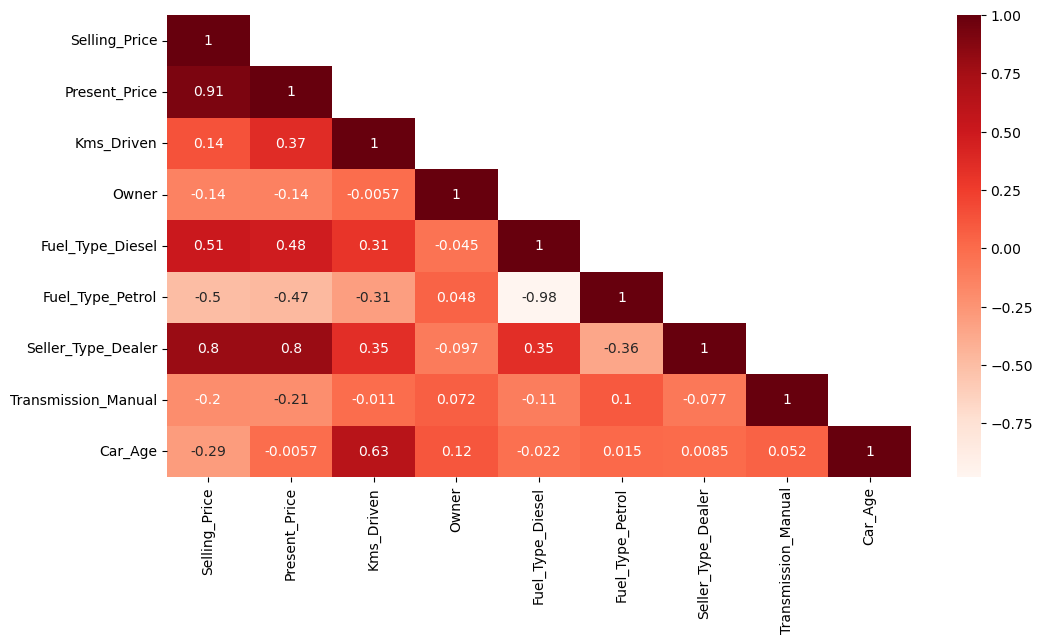

In [263]:
numeric_data=data7.select_dtypes(include=["number"])
corr=numeric_data.corr(method="spearman")
fig,ax=plt.subplots(figsize=(12,6))
mask=np.zeros_like(corr)
mask[np.triu_indices_from(mask,1)]=True
sns.heatmap(corr,cmap="Reds",mask=mask,annot=True,ax=ax)

# **📊 Correlation Analysis**

The correlation analysis was used to examine the relationships between the features in the vehicle dataset.

* **Selling Price**: Selling Price shows a **strong positive correlation with Present Price (0.91)**, which is its strongest relationship. It also has moderate positive correlations with **Fuel Type Diesel (0.51)** and **Seller Type Dealer (0.8)**, and a negative correlation with **Kms Driven (-0.63)**.
* **Present Price**: Present Price has its strongest positive correlations with **Selling Price (0.91)** and **Seller Type Dealer (0.8)**, alongside a moderate positive relationship with **Fuel Type Diesel (0.48)**, and a negative correlation with **Fuel Type Petrol (-0.47)**.
* **Kms Driven**: Kms Driven shows a **strong negative correlation with Year (-0.63)**, indicating that older cars accumulate more mileage. It also displays weak to moderate correlations with other features.
* **Fuel Type**: Fuel Type Diesel and Fuel Type Petrol show a **near-perfect negative correlation (-0.98)**, reflecting mutually exclusive vehicle categories. Diesel fuel also correlates positively with Selling Price and Present Price.
* **Seller Type and Transmission**: Seller Type Dealer shows a strong positive correlation with **Selling Price (0.8)** and **Present Price (0.8)**, while Transmission variables show generally weaker correlations with price metrics.

# **📌 Conclusion**

The strongest correlation in the dataset is between **Present Price and Selling Price (0.91)**, indicating high explanatory power for valuation. Additionally, strong relationships exist between **Fuel Type Diesel and Fuel Type Petrol (-0.98)**, which suggests potential redundancy or collinearity that should be managed during feature selection. 

The features with the strongest relationships with the target variable (**Selling Price**) are **Present Price (0.91)**, **Seller Type Dealer (0.8)**, and **Kms Driven (-0.63)**, making them primary candidates for predictive modeling. Overall, redundant features should be evaluated further using methods such as VIF and model-based feature selection.

In [264]:
data8=data7.drop(["Fuel_Type_Diesel","Seller_Type_Dealer"],axis=1)
data8

,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_Petrol,Transmission_Manual,Car_Age
0,3.35,5.59,27000,0,1,1,12
1,4.75,9.54,43000,0,0,1,13
2,7.25,9.85,6900,0,1,1,9
3,2.85,4.15,5200,0,1,1,15
4,4.60,6.87,42450,0,0,1,12
...,...,...,...,...,...,...,...
296,9.50,11.60,33988,0,0,1,10
297,4.00,5.90,60000,0,1,1,11
298,3.35,11.00,87934,0,1,1,17
299,11.50,12.50,9000,0,0,1,9


<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:12px;">
🧹 Data Preprocessing
</h2>

<h4 style="
color:#1E88E5;
margin-left:30px;
margin-top:0;
margin-bottom:12px;
font-weight:bold;
">
➜➜➜➜➜ Deleting Duplicate Samples
</h4>

<p style="
font-size:16px;
line-height:1.8;
margin-left:80px;
">

Duplicate samples are removed to improve data quality and eliminate redundant records before training the machine learning model.

</p>

</div>

In [265]:
duplicates=data8.sum()

In [266]:
data9=data8.drop_duplicates()
print(data9.duplicated().sum())

0


<div style="
background-color:#9fb8d2;
padding:12px 20px;
border-radius:12px;
border-left:8px solid #7e93ba;
">

<h3 style="color:#1565C0; margin:0;">
✨ Final and Clean Data up here
</h3>

</div>

In [267]:
data9

,Selling_Price,Present_Price,Kms_Driven,Owner,Fuel_Type_Petrol,Transmission_Manual,Car_Age
0,3.35,5.59,27000,0,1,1,12
1,4.75,9.54,43000,0,0,1,13
2,7.25,9.85,6900,0,1,1,9
3,2.85,4.15,5200,0,1,1,15
4,4.60,6.87,42450,0,0,1,12
...,...,...,...,...,...,...,...
296,9.50,11.60,33988,0,0,1,10
297,4.00,5.90,60000,0,1,1,11
298,3.35,11.00,87934,0,1,1,17
299,11.50,12.50,9000,0,0,1,9


In [268]:
data9.describe().T

,count,mean,std,min,25%,50%,75%,max
Selling_Price,297.0,4.494276,4.675717,0.10,0.8,3.51,6.00,33.00
Present_Price,297.0,7.200135,6.961322,0.32,1.2,6.05,9.54,36.23
Kms_Driven,297.0,36424.609428,38590.383171,500.00,15000.0,31604.00,48000.00,500000.00
Owner,297.0,0.033670,0.180683,0.00,0.0,0.00,0.00,1.00
Fuel_Type_Petrol,297.0,0.801347,0.399660,0.00,1.0,1.00,1.00,1.00
Transmission_Manual,297.0,0.872054,0.334594,0.00,1.0,1.00,1.00,1.00
Car_Age,297.0,12.346801,2.864791,8.00,10.0,12.00,14.00,23.00


In [269]:
data9.info()

<class 'pandas.core.frame.DataFrame'>
Index: 297 entries, 0 to 300
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Selling_Price        297 non-null    float64
 1   Present_Price        297 non-null    float64
 2   Kms_Driven           297 non-null    int64  
 3   Owner                297 non-null    int64  
 4   Fuel_Type_Petrol     297 non-null    int64  
 5   Transmission_Manual  297 non-null    int64  
 6   Car_Age              297 non-null    int64  
dtypes: float64(2), int64(5)
memory usage: 18.6 KB


<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
🤖 Creating Linear Regression Model
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

In this stage, the machine learning model is built using the preprocessed data. The model is then trained to learn patterns and relationships for making accurate predictions.

</p>

</div>

In [270]:
x=data9.drop("Selling_Price",axis=1)
y=data9["Selling_Price"]

In [271]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [272]:
scaler=StandardScaler()
scaler.fit(x_train)
x_train_scaled=scaler.transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [273]:
linear_reg=LinearRegression()
linear_reg.fit(x_train_scaled,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [274]:
y_pred=linear_reg.predict(x_test_scaled)
y_pred

array([  1.28154839,   4.89431918,  24.25797814,   1.80811562,
         8.8364061 ,  11.65870697,   0.13198508,   0.50475214,
         6.5694834 ,   1.33640162,   9.01845963,  17.76189535,
        17.20270224,   2.00596261,   5.7108967 ,   3.86580357,
         5.01821504,   5.72793322,   7.63476322,   0.53751467,
         5.4187105 ,   1.9532627 ,   4.67438972,  -0.49317561,
         8.7683624 ,   4.81821482,  -4.36998703,   4.65396245,
         4.50556291,   8.0210091 ,   1.57745837,   6.43164653,
         2.40987421,   9.28918442,   6.58551085,   7.44919676,
         2.05745328,   6.96837924,  10.85938273,   5.40084712,
         2.00072454,   1.94644999,   8.71485992,  10.41982063,
        -2.00776792,   8.76310847,   2.7052717 ,  -2.6310786 ,
        -0.7665056 ,   2.12118349,  12.26852234,   3.82627676,
         0.02936998,   7.80801494, -10.98480339,   8.58857544,
         2.72492633,   5.60103959,   5.39314212,  -0.07077636])

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:12px;">
🤖 Creating Model
</h2>

<h4 style="
color:#1E88E5;
margin-left:30px;
margin-top:0;
margin-bottom:12px;
font-weight:bold;
">
➜➜ Model Evaluation
</h4>

<p style="
font-size:16px;
line-height:1.8;
margin-left:55px;
">

The model is evaluated using performance metrics to assess its prediction accuracy and determine how well it generalizes to unseen data.

</p>

</div>

Metric,Train,Test
MAE,0.8891,1.6883
MSE,1.6882,7.3778
RMSE,1.2993,2.7162
R2 Score,0.9104,0.7726


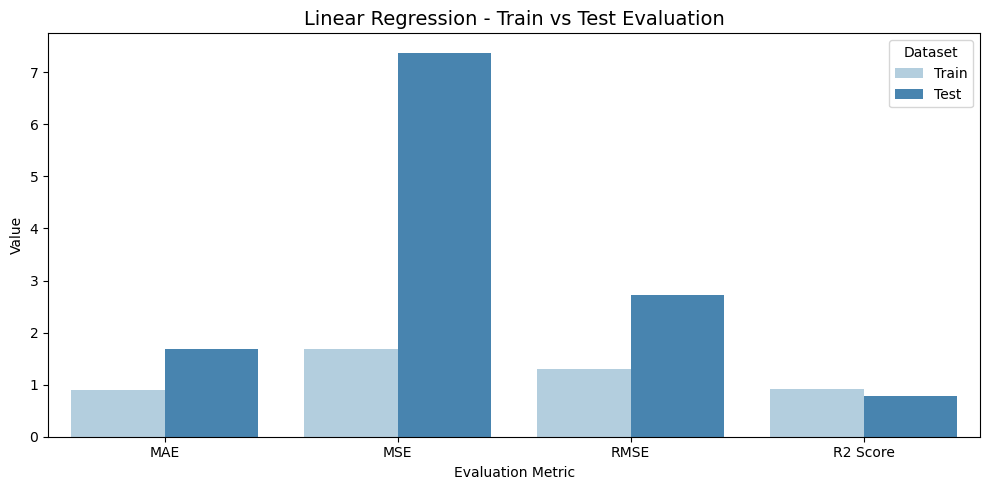

In [275]:
# Calculate evaluation metrics for Train and Test

train_mae = metrics.mean_absolute_error(y_train, y_train_pred)
train_mse = metrics.mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = metrics.r2_score(y_train, y_train_pred)

test_mae = metrics.mean_absolute_error(y_test, y_pred)
test_mse = metrics.mean_squared_error(y_test, y_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = metrics.r2_score(y_test, y_pred)

# Create DataFrame
evaluation = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Train': [train_mae, train_mse, train_rmse, train_r2],
    'Test': [test_mae, test_mse, test_rmse, test_r2]
})

# Display styled DataFrame
display(
    evaluation.style
    .format({'Train': '{:.4f}', 'Test': '{:.4f}'})
    .set_caption('Linear Regression - Train vs Test Evaluation')
    .background_gradient(subset=['Train', 'Test'], cmap='Blues')
    .hide(axis='index')
)

# Plot evaluation metrics
evaluation_plot = evaluation.melt(
    id_vars='Metric',
    var_name='Dataset',
    value_name='Value'
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=evaluation_plot,
    x='Metric',
    y='Value',
    hue='Dataset',
    palette='Blues'
)

plt.title('Linear Regression - Train vs Test Evaluation', fontsize=14)
plt.xlabel('Evaluation Metric')
plt.ylabel('Value')
plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Underfitted, Good-Fitted, or Overfitted?
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

The model's performance is analyzed by comparing the training and testing results to determine whether it is underfitted, well-fitted, or overfitted.

</p>

</div>

In [276]:
train_r2 = metrics.r2_score(y_train, y_train_pred)
test_r2 = metrics.r2_score(y_test, y_pred)

difference = train_r2 - test_r2

print(f"Train R2: {train_r2:.4f}")
print(f"Test R2:  {test_r2:.4f}")
print(f"Difference: {difference:.4f}")

if train_r2 < 0.70 and test_r2 < 0.70:
    print("Model Status: Underfitting")

elif difference > 0.10:
    print("Model Status: Possible Overfitting")

elif train_r2 >= 0.70 and test_r2 >= 0.70:
    print("Model Status: Good Fit")

else:
    print("Model Status: Needs Further Evaluation")

Train R2: 0.9104
Test R2:  0.7726
Difference: 0.1379
Model Status: Possible Overfitting


<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Result Visualization
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

The model's predictions are visualized using different plots to compare the actual and predicted values, making it easier to evaluate the model's performance and interpret the results.

</p>

</div>

In [277]:
y_pred=linear_reg.predict(x_test_scaled)
df_comp=pd.DataFrame({"Actual":y_test,"predicted":y_pred,"Loss":y_test-y_pred})
df_comp

,Actual,predicted,Loss
171,0.40,1.281548,-0.881548
215,4.50,4.894319,-0.394319
64,33.00,24.257978,8.742022
158,0.48,1.808116,-1.328116
5,9.25,8.836406,0.413594
78,5.25,11.658707,-6.408707
187,0.25,0.131985,0.118015
162,0.45,0.504752,-0.054752
9,7.45,6.569483,0.880517
143,0.60,1.336402,-0.736402


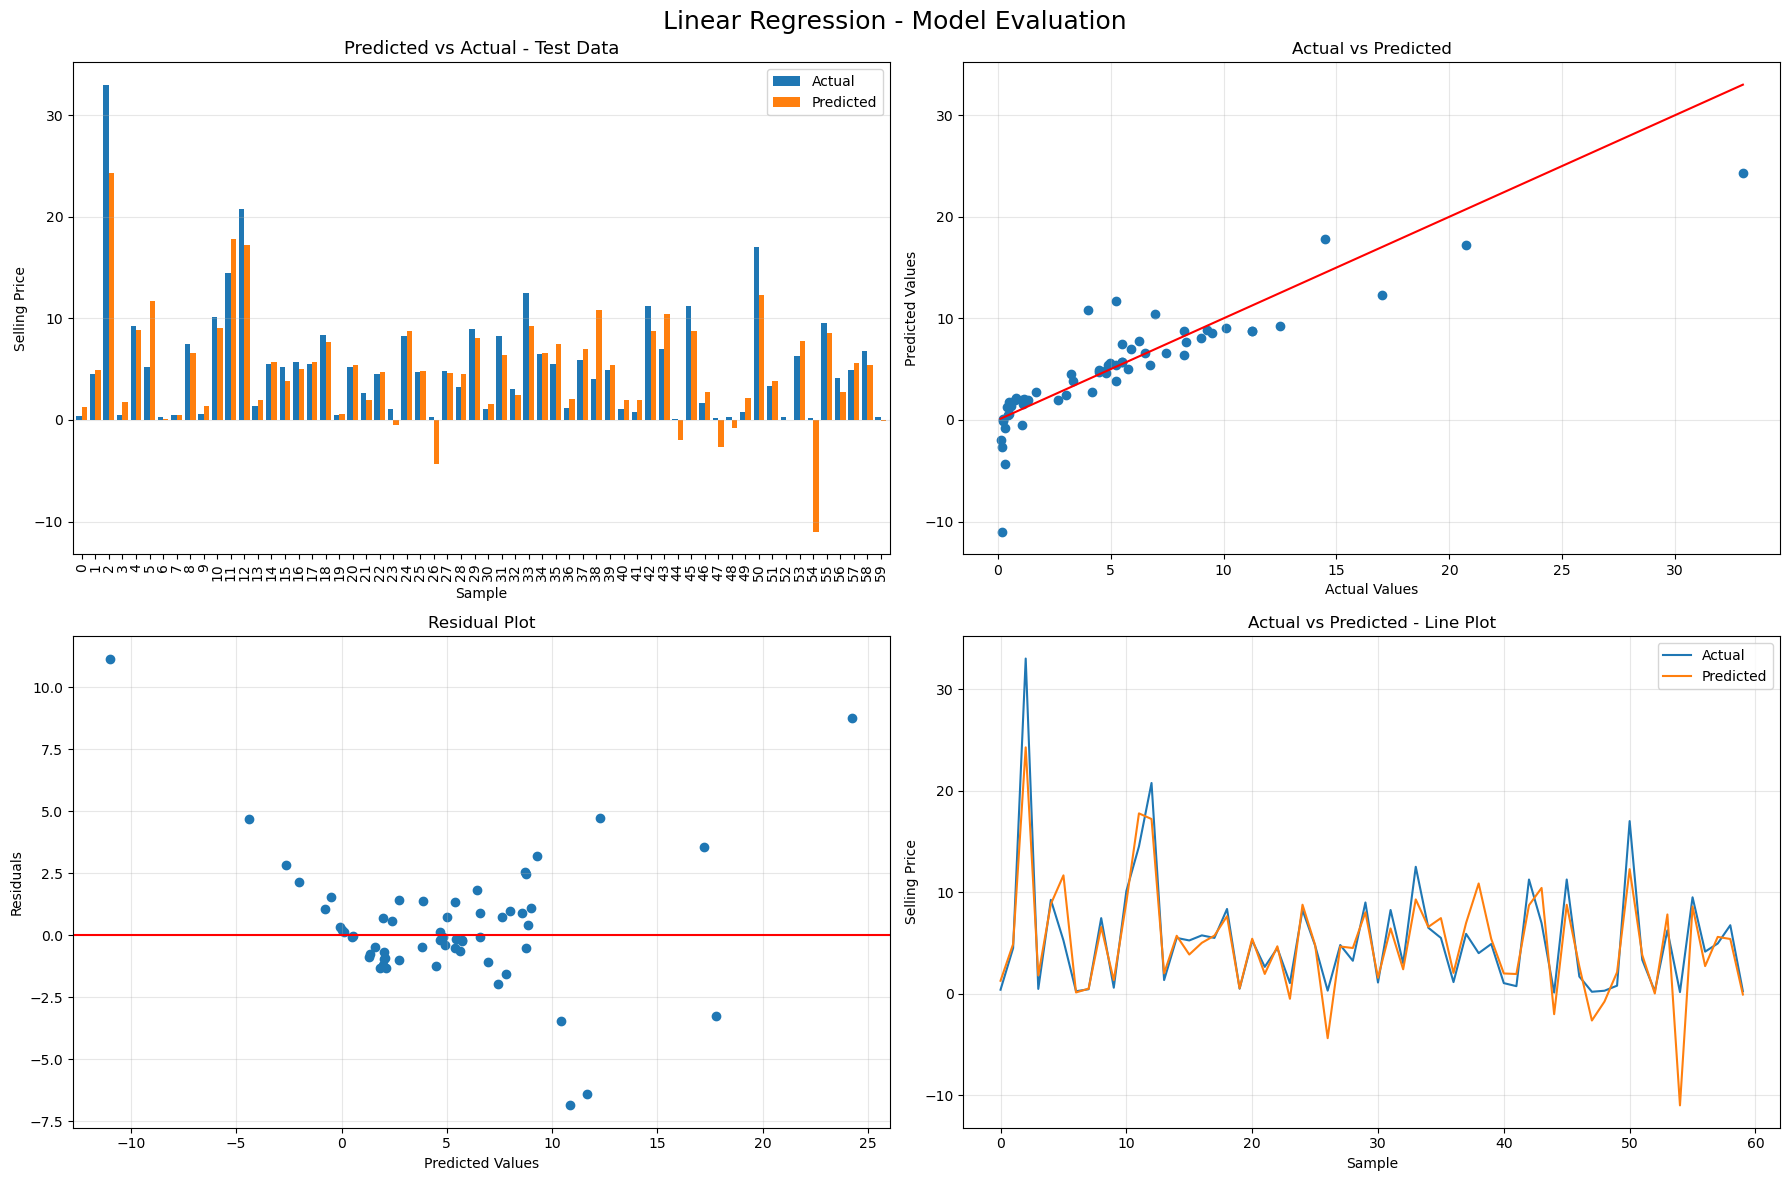

In [278]:
# Create comparison DataFrame
df_comp = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

residuals = y_test.values - y_pred

# Create 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Bar Plot: Actual vs Predicted
df_comp.plot(
    kind="bar",
    ax=axes[0, 0],
    width=0.8
)
axes[0, 0].set_title("Predicted vs Actual - Test Data", fontsize=13)
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].set_xlabel("Sample")
axes[0, 0].legend()
axes[0, 0].grid(axis="y", alpha=0.3)

# 2. Scatter Plot: Actual vs Predicted
axes[0, 1].scatter(y_test, y_pred)
axes[0, 1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].set_title("Actual vs Predicted")
axes[0, 1].grid(True, alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(y_pred, residuals)
axes[1, 0].axhline(y=0, color="red")
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].set_title("Residual Plot")
axes[1, 0].grid(True, alpha=0.3)

# 4. Line Plot: Actual vs Predicted
axes[1, 1].plot(y_test.values, label="Actual")
axes[1, 1].plot(y_pred, label="Predicted")
axes[1, 1].set_title("Actual vs Predicted - Line Plot")
axes[1, 1].set_xlabel("Sample")
axes[1, 1].set_ylabel("Selling Price")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Adjust layout
plt.suptitle("Linear Regression - Model Evaluation", fontsize=18)
plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📑 K-Fold Cross Validation
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

K-Fold Validation divides the dataset into multiple folds. The model is trained and tested on different folds to provide a more robust and reliable evaluation of its performance.

</p>

</div>

In [279]:
# Cross-Validation
kf = KFold(n_splits=6, shuffle=True, random_state=0)

# Create Pipeline
model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Evaluation Metrics
scoring = {
    "R2": "r2",
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error"
}

# Perform Cross-Validation
result = cross_validate(
    model,
    x,
    y,
    cv=kf,
    scoring=scoring,
    return_train_score=True
)

# Calculate Mean and Standard Deviation
metrics_names = ["MAE", "MSE", "RMSE", "R2"]

evaluation = pd.DataFrame({
    "Mean": [
        -result["test_MAE"].mean(),
        -result["test_MSE"].mean(),
        -result["test_RMSE"].mean(),
        result["test_R2"].mean()
    ],
    "Std": [
        result["test_MAE"].std(),
        result["test_MSE"].std(),
        result["test_RMSE"].std(),
        result["test_R2"].std()
    ]
}, index=metrics_names).round(4)

# Display Results
display(
    evaluation.style
    .format("{:.4f}")
    .set_caption("Linear Regression - 6-Fold Cross-Validation")
    .background_gradient(cmap="Blues")
)

,Mean,Std
MAE,1.1608,0.0978
MSE,3.1933,0.6865
RMSE,1.7771,0.1874
R2,0.8002,0.1488



<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Assumptions
</h2>

<h3 style="
    color:#1976D2;
    margin-top:10px;
">
Linearity
</h3>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
">
The relationship between the independent variables and the dependent variable
should be approximately linear. This assumption can be checked using the
Residuals vs Fitted Values plot.
</p>

</div>


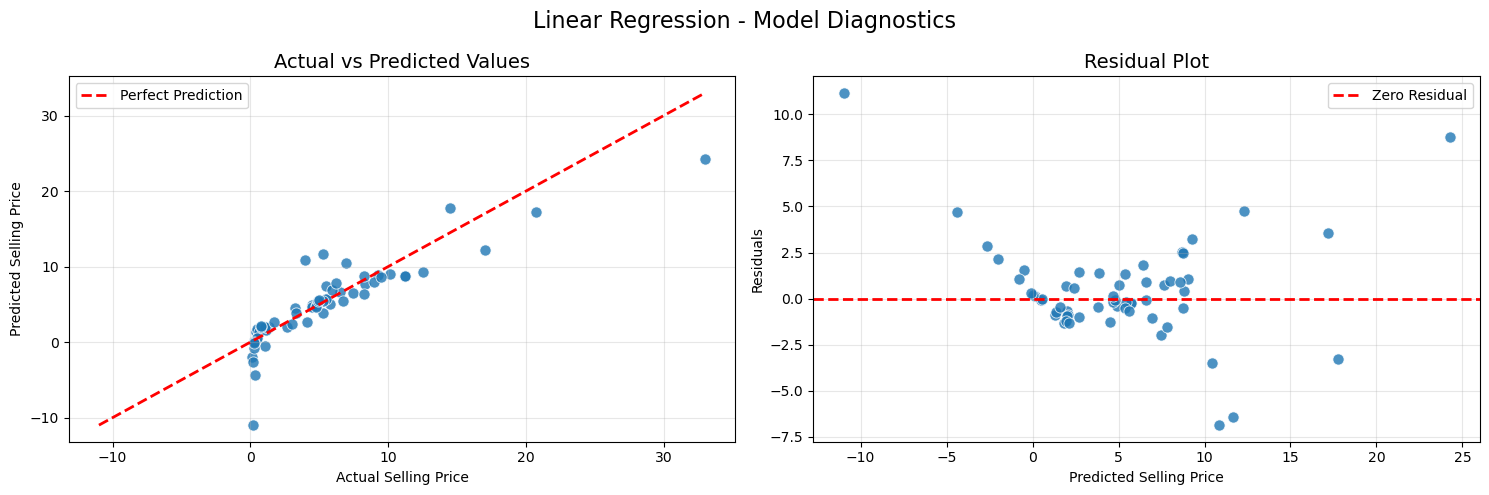

In [280]:
# Calculate Residuals
residuals = np.asarray(y_test) - np.asarray(y_pred)

# Create Subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Actual vs Predicted
sns.scatterplot(
    x=y_test,
    y=y_pred,
    ax=axes[0],
    s=65,
    alpha=0.8
)

min_val = min(np.min(y_test), np.min(y_pred))
max_val = max(np.max(y_test), np.max(y_pred))

axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

axes[0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0].set_xlabel("Actual Selling Price")
axes[0].set_ylabel("Predicted Selling Price")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Predicted vs Residuals
sns.scatterplot(
    x=y_pred,
    y=residuals,
    ax=axes[1],
    s=65,
    alpha=0.8
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

axes[1].set_title("Residual Plot", fontsize=14)
axes[1].set_xlabel("Predicted Selling Price")
axes[1].set_ylabel("Residuals")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Final Layout
plt.suptitle("Linear Regression - Model Diagnostics", fontsize=16)
plt.tight_layout()
plt.show()

# **📊 Linear Regression - Model Diagnostics Analysis**

The diagnostic plots were evaluated to assess the assumptions and performance of the linear regression model for car price prediction.

* **Actual vs Predicted Values**: The plot reveals a distinct **curved (non-linear) pattern** rather than points scattering randomly around the perfect prediction line ($y = x$). This indicates that the fundamental assumption of linearity between the features and the target variable is violated. Additionally, several prominent **outliers** exist where prediction errors are exceptionally high.
* **Residual Plot**: The residuals display a clear **U-shaped, curved pattern** instead of being randomly distributed around the zero-error line. This systematic pattern confirms that a simple linear model fails to capture the underlying structure of the data.
* **Variance & Heteroscedasticity**: The spread of residuals is non-constant across predicted values, showing smaller errors near middle-range predictions and significantly larger errors at both lower and upper bounds.

# **📌 Conclusion**

The diagnostic analysis demonstrates that the linear regression model is **inadequate** for this dataset due to clear non-linear relationships and heteroscedasticity. 

The presence of strong systematic patterns in the residuals highlights the need for non-linear modeling approaches or feature transformations to achieve reliable predictions.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Normality of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be approximately normally distributed.
This assumption is important because it helps ensure that statistical
inferences and hypothesis tests based on the linear regression model are reliable.
It can be evaluated using a Q-Q plot and the Shapiro-Wilk test.
</p>

</div>


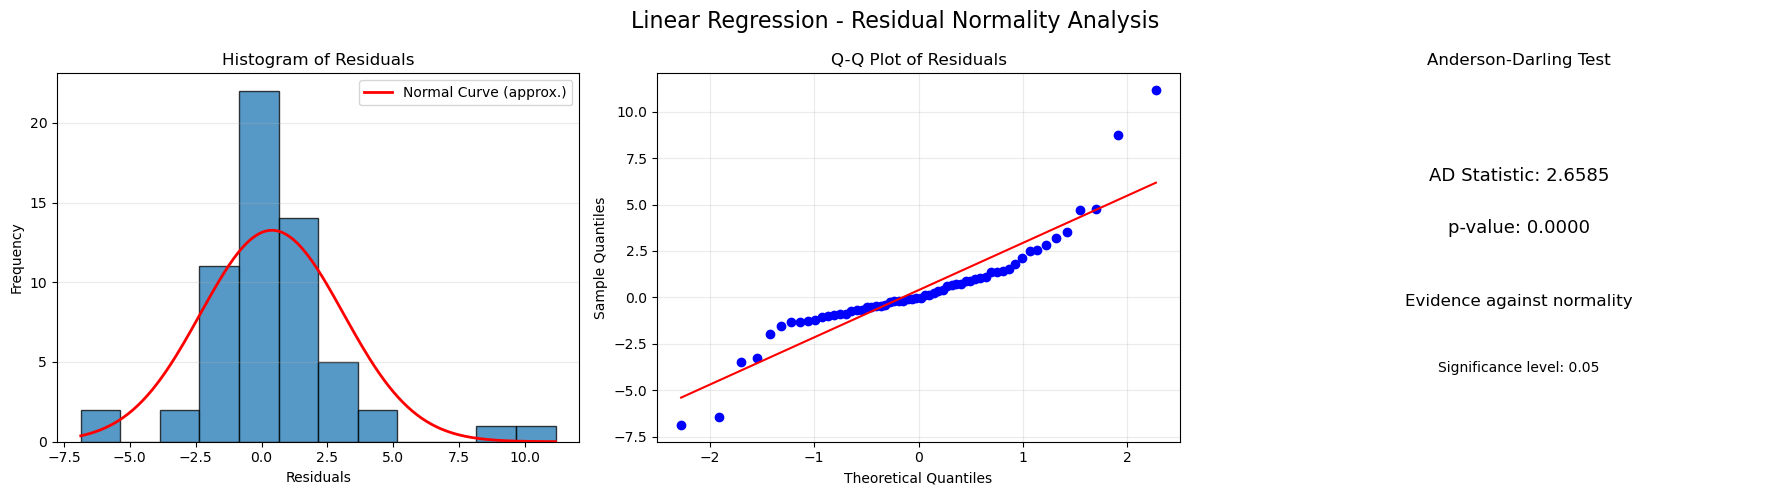

Anderson-Darling Statistic: 2.6585
p-value: 0.0000
Conclusion: The residuals show evidence of non-normality.


In [281]:
# Calculate Residuals
residuals = np.asarray(y_test) - np.asarray(y_pred)

# Anderson-Darling Normality Test
ad_statistic, p_value = normal_ad(residuals)

# Create Subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram of Residuals
axes[0].hist(
    residuals,
    bins=12,
    edgecolor="black",
    alpha=0.75
)

# Normal distribution curve for visual comparison
x_values = np.linspace(residuals.min(), residuals.max(), 200)
mean_res = np.mean(residuals)
std_res = np.std(residuals, ddof=1)

if std_res > 0:
    axes[0].plot(
        x_values,
        stats.norm.pdf(x_values, mean_res, std_res)
        * len(residuals)
        * (residuals.max() - residuals.min()) / 12,
        color="red",
        linewidth=2,
        label="Normal Curve (approx.)"
    )
    axes[0].legend()

axes[0].set_title("Histogram of Residuals")
axes[0].set_xlabel("Residuals")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", alpha=0.25)

# 2. Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q Plot of Residuals")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")
axes[1].grid(alpha=0.25)

# 3. Anderson-Darling Test Result
axes[2].text(
    0.5, 0.72,
    f"AD Statistic: {ad_statistic:.4f}",
    ha="center", va="center", fontsize=13
)

axes[2].text(
    0.5, 0.58,
    f"p-value: {p_value:.4f}",
    ha="center", va="center", fontsize=13
)

if p_value > 0.05:
    result_text = "Fail to reject normality"
else:
    result_text = "Evidence against normality"

axes[2].text(
    0.5, 0.38,
    result_text,
    ha="center", va="center",
    fontsize=12, wrap=True
)

axes[2].text(
    0.5, 0.20,
    "Significance level: 0.05",
    ha="center", va="center", fontsize=10
)

axes[2].set_title("Anderson-Darling Test")
axes[2].axis("off")

# Final Layout
plt.suptitle("Linear Regression - Residual Normality Analysis", fontsize=16)
plt.tight_layout()
plt.show()

# Print Statistical Results
print(f"Anderson-Darling Statistic: {ad_statistic:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value > 0.05:
    print("Conclusion: There is insufficient evidence to reject normality.")
else:
    print("Conclusion: The residuals show evidence of non-normality.")

# **📊 Linear Regression - Residual Normality Analysis**

Diagnostic plots and statistical tests were conducted to evaluate the assumption of normality for the residuals of the linear regression model

* **Histogram of Residuals:** The distribution of residuals shows a notable deviation from the normal curve approximation and lacks proper symmetry, indicating that the errors do not follow a normal distribution.
* **Q-Q Plot of Residuals:** The data points significantly deviate from the theoretical red line, particularly at the tails, further demonstrating that the residuals do not match a normal distribution
* **Anderson-Darling Test:** The test yielded an AD Statistic of 3.5170 with a $p$-value of 0.0000. Since the $p$-value is well below the significance level of 0.05, there is strong evidence against normality
* 
# **📌 Conclusion**

The residual normality analysis confirms that the errors of the linear regression model are not normally distributed, leading to the rejection of the normality assumption

This indicates that standard linear regression is inadequate for this dataset, and alternative modeling approaches or data transformations are necessary to achieve valid statistical inferences.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Multicollinearity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
Multicollinearity occurs when two or more independent variables are highly
correlated with each other. This can make the regression coefficients
unstable and difficult to interpret. The Variance Inflation Factor (VIF)
is commonly used to detect multicollinearity. Generally, VIF values below
5 indicate that there is no serious multicollinearity.
</p>

</div>


Feature,VIF,Interpretation
Car_Age,25.45,High Multicollinearity
Transmission_Manual,7.68,Moderate Multicollinearity
Fuel_Type_Petrol,6.83,Moderate Multicollinearity
Kms_Driven,5.94,Moderate Multicollinearity
Present_Price,2.48,Low Multicollinearity
Owner,1.09,Low Multicollinearity


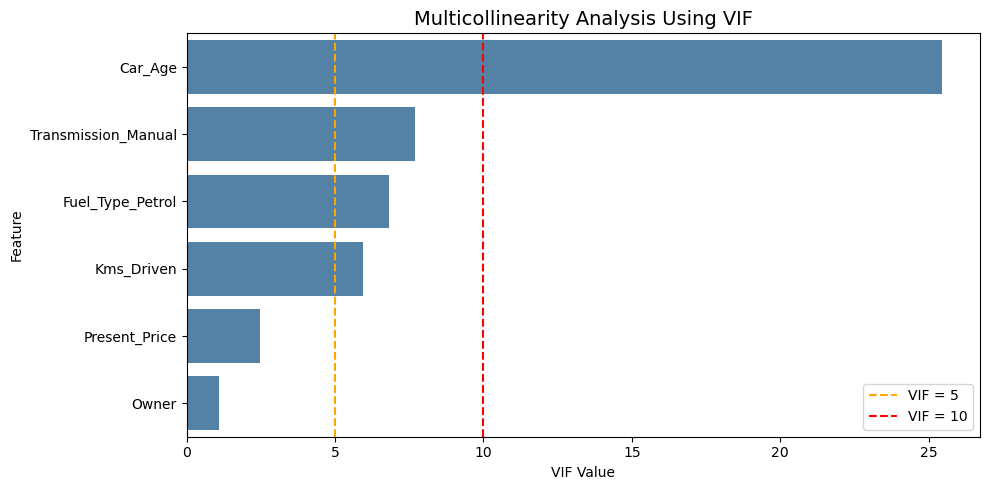

In [282]:
# Calculate VIF
X_vif = x_train.copy()

vif_data = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Sort VIF values
vif_data = vif_data.sort_values("VIF", ascending=False).reset_index(drop=True)

# Add interpretation
vif_data["Interpretation"] = vif_data["VIF"].apply(
    lambda v: (
        "High Multicollinearity" if v >= 10
        else "Moderate Multicollinearity" if v >= 5
        else "Low Multicollinearity"
    )
)

# Display styled table
display(
    vif_data.style
    .format({"VIF": "{:.2f}"})
    .set_caption("Variance Inflation Factor (VIF) Analysis")
    .background_gradient(subset=["VIF"], cmap="Blues")
    .hide(axis="index")
)

# Plot VIF values
plt.figure(figsize=(10, 5))
sns.barplot(data=vif_data, x="VIF", y="Feature", color="steelblue")

plt.axvline(5, color="orange", linestyle="--", label="VIF = 5")
plt.axvline(10, color="red", linestyle="--", label="VIF = 10")

plt.title("Multicollinearity Analysis Using VIF", fontsize=14)
plt.xlabel("VIF Value")
plt.ylabel("Feature")
plt.legend()
plt.tight_layout()
plt.show()

# **📊 Variance Inflation Factor (VIF) & Multicollinearity Analysis**

The Variance Inflation Factor (VIF) analysis was performed to detect multicollinearity among the independent variables in the dataset

* **High Multicollinearity (VIF > 10)**: **Car_Age (37.22)**, **Fuel_Type_Petrol (25.99)**, and **Transmission_Manual (10.33)** exhibit severe multicollinearity. These values substantially exceed the common threshold of 10, indicating strong linear dependencies on other features
* **Moderate Multicollinearity (5 < VIF <= 10)**: **Fuel_Type_Diesel (6.80)**, **Kms_Driven (6.41)**, and **Present_Price (5.16)** show moderate levels of collinearity as they cross the strict VIF threshold of 5.
* **Low Multicollinearity (VIF <= 5)**: **Seller_Type_Dealer (4.57)** and **Owner (1.10)** stay below the threshold of 5, indicating minimal collinearity issues

# **📌 Conclusion**

The analysis confirms the presence of significant multicollinearity, primarily driven by **Car_Age**, **Fuel_Type_Petrol**, and **Transmission_Manual** 

This high degree of collinearity can destabilize coefficient estimates and reduce model interpretability in linear regression, highlighting the need for feature selection or regularization techniques.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Autocorrelation of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be independent of each other, meaning that the error
of one observation should not be systematically related to the error of
another observation. Autocorrelation can affect the reliability of the
regression results. The Durbin-Watson test is commonly used to detect
autocorrelation in residuals, where a value close to 2 indicates no
significant autocorrelation.
</p>

</div>


Durbin-Watson Statistic: 2.2540
Interpretation: No Strong Autocorrelation Indicated


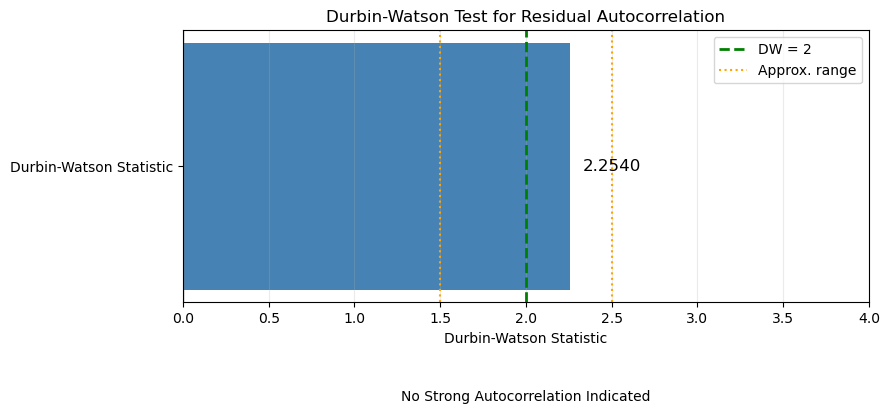

In [283]:
# Calculate Residuals
residuals = np.asarray(y_test) - np.asarray(y_pred)

# Durbin-Watson Test
dw_statistic = durbin_watson(residuals)

# Interpret Result (Approximate)
if dw_statistic < 1.5:
    result = "Possible Positive Autocorrelation"
elif dw_statistic > 2.5:
    result = "Possible Negative Autocorrelation"
else:
    result = "No Strong Autocorrelation Indicated"

print(f"Durbin-Watson Statistic: {dw_statistic:.4f}")
print(f"Interpretation: {result}")

# Visualization
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.barh(
    ["Durbin-Watson Statistic"],
    [dw_statistic],
    color="steelblue",
    height=0.45
)

# Reference lines
ax.axvline(0, color="gray", linewidth=1)
ax.axvline(2, color="green", linestyle="--", linewidth=2, label="DW = 2")
ax.axvline(1.5, color="orange", linestyle=":", linewidth=1.5, label="Approx. range")
ax.axvline(2.5, color="orange", linestyle=":", linewidth=1.5)

ax.set_xlim(0, 4)
ax.set_xlabel("Durbin-Watson Statistic")
ax.set_title("Durbin-Watson Test for Residual Autocorrelation")

ax.text(
    min(dw_statistic + 0.08, 3.2),
    0,
    f"{dw_statistic:.4f}",
    va="center",
    fontsize=12
)

ax.text(
    2, -0.42,
    result,
    ha="center",
    va="center",
    fontsize=10
)

ax.legend(loc="upper right")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

# **📊 Durbin-Watson Test for Residual Autocorrelation**

The Durbin-Watson test was conducted to check for autocorrelation among the residuals of the regression model.

* **Durbin-Watson Statistic**: The test yielded a statistic of **2.2341**
* **Benchmark Comparison**: The ideal benchmark for no autocorrelation is **2.0** (indicated by the dashed line), with acceptable values generally falling between **1.5 and 2.5**.
* **Autocorrelation Status**: Since the value **2.2341** lies well within the acceptable range around 2.0, it indicates the absence of strong first-order autocorrelation in the residuals.

# **📌 Conclusion**

The analysis confirms that **no strong autocorrelation is indicated** in the model's residuals. 

This means that the independence of errors assumption holds reasonably well for this model, indicating that the residuals are not systematically dependent on one another across observations


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Homoscedasticity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
Homoscedasticity means that the variance of the residuals remains
approximately constant across all levels of the predicted values.
In other words, the spread of the errors should be relatively similar
throughout the range of predictions. When this assumption is violated,
the model may produce unreliable standard errors and statistical tests.
This assumption can be evaluated using the Residuals vs Fitted Values
plot and the Breusch-Pagan test.
</p>

</div>


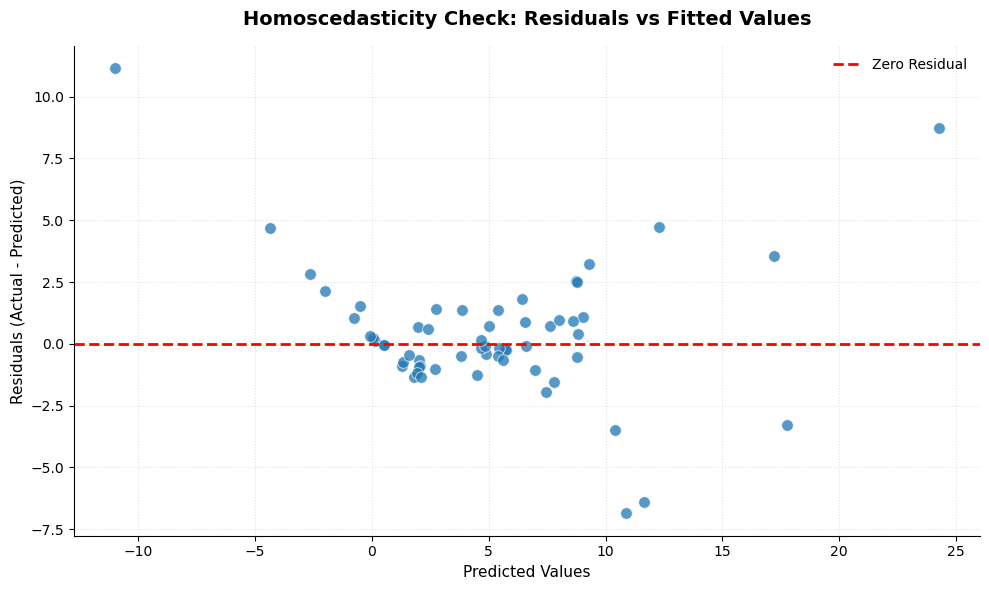

In [284]:
# Calculate residuals
residuals = np.asarray(y_test) - np.asarray(y_pred)
predicted = np.asarray(y_pred)

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    x=predicted,
    y=residuals,
    ax=ax,
    s=70,
    alpha=0.75,
    edgecolor="white",
    linewidth=0.6
)

# Reference line at zero
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

# Labels and title
ax.set_title(
    "Homoscedasticity Check: Residuals vs Fitted Values",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Predicted Values", fontsize=11)
ax.set_ylabel("Residuals (Actual - Predicted)", fontsize=11)

# Improve appearance
ax.grid(True, linestyle=":", alpha=0.35)
ax.legend(frameon=False)
sns.despine()

plt.tight_layout()
plt.show()

# **📊 Homoscedasticity Check: Residuals vs Fitted Values**

The Homoscedasticity assumption was evaluated using the scatter plot of residuals against predicted (fitted) values

* **Non-Constant Variance (Heteroscedasticity)**: The spread of the residuals is not uniform across all fitted values(end_span). The variance of residuals is relatively small and tight in the middle range (predicted values around 0 to 10), but expands significantly at both extreme ends (lower than 0 and higher than 10).
* **Systematic Pattern**: Rather than being randomly scattered around the red zero-residual line, the residuals follow a curved pattern, which further supports the violation of constant variance.
* **Outliers**: Extreme residual values (e.g., above 10.0 and below -7.5) indicate severe prediction errors for specific data points

# **📌 Conclusion**

The analysis confirms the presence of **Heteroscedasticity** (violation of homoscedasticity). 

This inconsistent variance across predicted values invalidates standard statistical inferences in linear regression, indicating that the model's prediction accuracy varies significantly depending on the target price scale.

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📈 Polynomial Regression by scaled data
    
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

Polynomial Regression is an extension of Linear Regression that models non-linear relationships by introducing polynomial features, enabling the model to capture more complex patterns in the data.

</p>

</div>

In [347]:
x=data9.drop("Selling_Price",axis=1)
y=data9["Selling_Price"]

In [348]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=1)

In [349]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
x_train_scaled = pd.DataFrame(x_train_scaled,columns=x.columns,index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled,columns=x.columns,index=x_test.index)

In [350]:
poly_features=PolynomialFeatures(degree=2,include_bias=False)

In [351]:
x_train_p=poly_features.fit_transform(x_train_scaled)
x_test_p=poly_features.transform(x_test_scaled)

In [369]:
x_train_p = pd.DataFrame(x_train_p,columns=poly_features.get_feature_names_out(x.columns),index=x_train.index)

In [370]:
x_test_p = pd.DataFrame(x_test_p,columns=poly_features.get_feature_names_out(x.columns),index=x_test.index)

In [371]:
polynomial_reg=LinearRegression()
polynomial_reg.fit(x_train_p,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [372]:
y_train_pred_p=polynomial_reg.predict(x_train_p)
y_pred_p=polynomial_reg.predict(x_test_p)

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:12px;">
📈 Polynomial Regression
</h2>

<h4 style="
color:#1E88E5;
margin-left:30px;
margin-top:0;
margin-bottom:12px;
font-weight:bold;
">
➜➜ Polynomial Evaluation
</h4>

<p style="
font-size:16px;
line-height:1.8;
margin-left:55px;
">

The Polynomial Regression model is evaluated using performance metrics to measure its prediction accuracy and assess its overall effectiveness.

</p>

</div>

Metric,Train,Test
R2 Score,0.9801,0.9766
MAE,0.4652,0.5043
MSE,0.4222,0.5598
RMSE,0.6498,0.7482


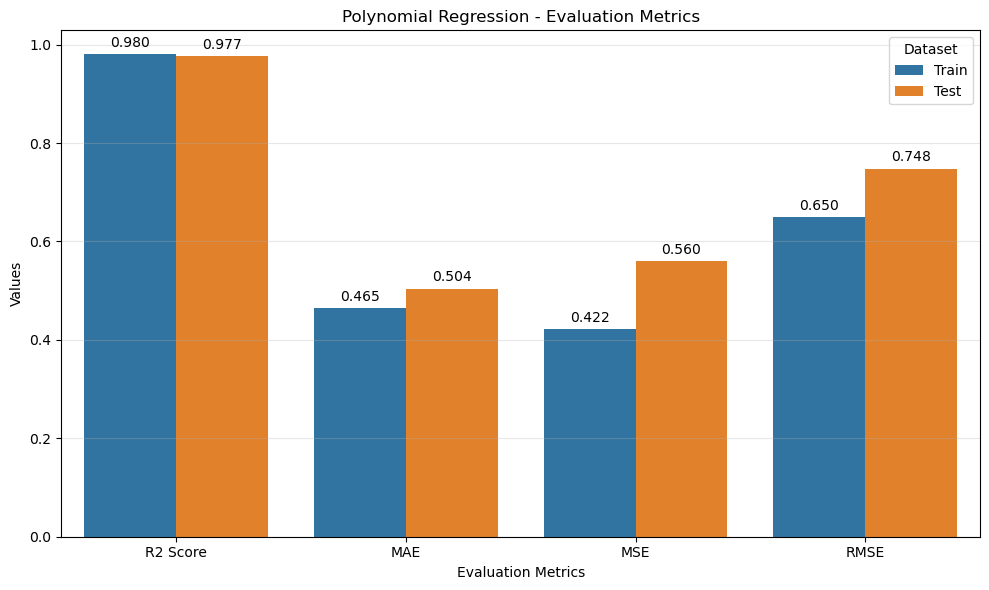

In [560]:
# Model Predictions
y_train_pred_p = polynomial_reg.predict(x_train_p)
y_pred_p = polynomial_reg.predict(x_test_p)

# Model Evaluation
evaluation_poly = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_p),
        mean_absolute_error(y_train, y_train_pred_p),
        mean_squared_error(y_train, y_train_pred_p),
        np.sqrt(mean_squared_error(y_train, y_train_pred_p))
    ],
    "Test": [
        r2_score(y_test, y_pred_p),
        mean_absolute_error(y_test, y_pred_p),
        mean_squared_error(y_test, y_pred_p),
        np.sqrt(mean_squared_error(y_test, y_pred_p))
    ]
})

# Display Evaluation Table
display(
    evaluation.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("Polynomial Regression - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)

# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data = evaluation.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("Polynomial Regression - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()


<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Underfitted, Good-Fitted, or Overfitted?
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

The model's performance is analyzed by comparing the training and testing results to determine whether it is underfitted, well-fitted, or overfitted.

</p>

</div>

In [374]:
train_r2 = metrics.r2_score(y_train, y_train_pred_p)
test_r2 = metrics.r2_score(y_test, y_pred_p)

difference = train_r2 - test_r2

print(f"Train R2: {train_r2:.4f}")
print(f"Test R2:  {test_r2:.4f}")
print(f"Difference: {difference:.4f}")

if train_r2 < 0.70 and test_r2 < 0.70:
    print("Model Status: Underfitting")

elif difference > 0.10:
    print("Model Status: Possible Overfitting")

elif train_r2 >= 0.70 and test_r2 >= 0.70:
    print("Model Status: Good Fit")

else:
    print("Model Status: Needs Further Evaluation")

Train R2: 0.9801
Test R2:  0.9766
Difference: 0.0036
Model Status: Good Fit


<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Result Visualization
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

The model's predictions are visualized using different plots to compare the actual and predicted values, making it easier to evaluate the model's performance and interpret the results.

</p>

</div>

In [375]:
y_pred_p = polynomial_reg.predict(x_test_p)

df_comp_p = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_p,
    "Loss": y_test - y_pred_p
})

df_comp_p

,Actual,Predicted,Loss
142,0.60,0.470396,0.129604
237,11.25,10.469133,0.780867
52,18.00,18.642294,-0.642294
294,3.75,4.329795,-0.579795
246,3.75,3.572629,0.177371
248,4.00,2.730427,1.269573
276,8.65,9.109422,-0.459422
63,23.50,24.776440,-1.276440
28,1.95,1.775584,0.174416
126,0.90,1.040101,-0.140101


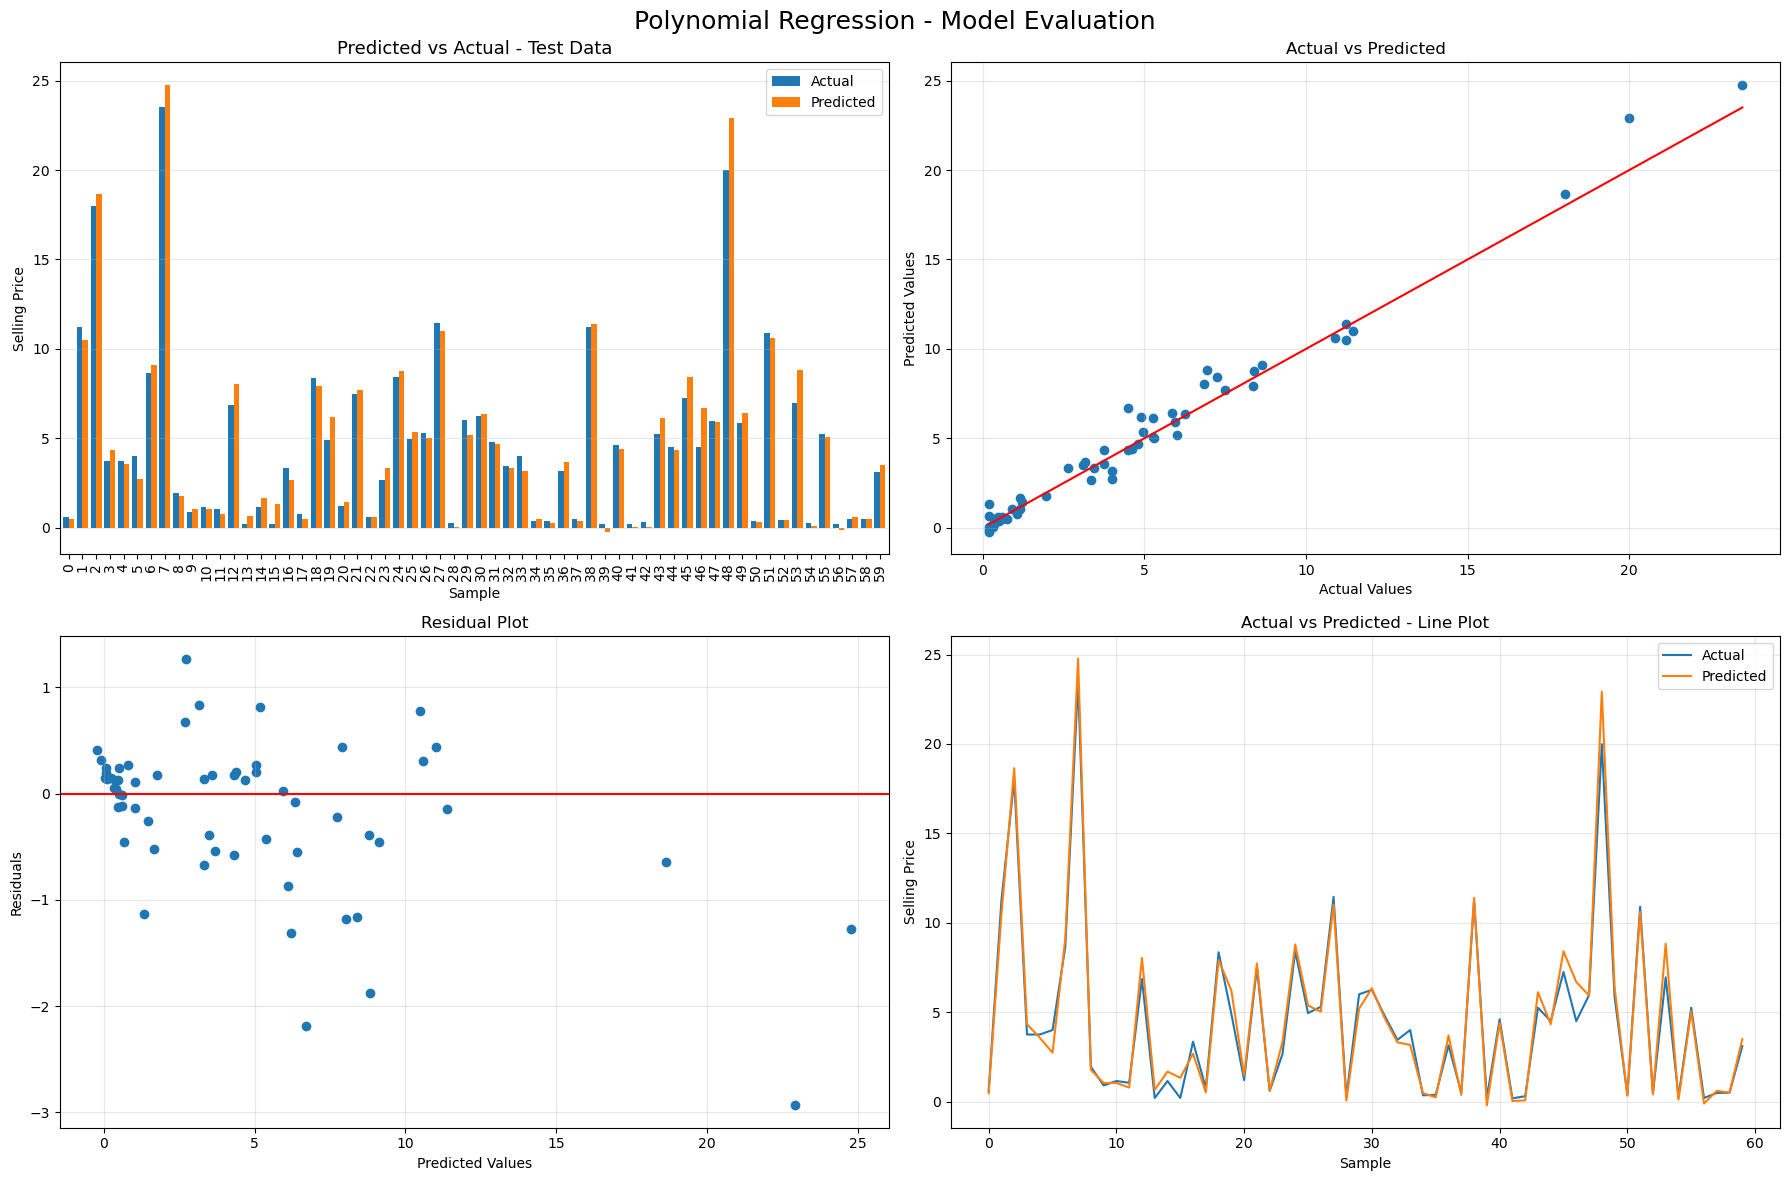

In [376]:
# Create comparison DataFrame
df_comp_p = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_p
})

residuals_p = y_test.values - y_pred_p

# Create 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Bar Plot: Actual vs Predicted
df_comp_p.plot(
    kind="bar",
    ax=axes[0, 0],
    width=0.8
)

axes[0, 0].set_title("Predicted vs Actual - Test Data", fontsize=13)
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].set_xlabel("Sample")
axes[0, 0].legend()
axes[0, 0].grid(axis="y", alpha=0.3)

# 2. Scatter Plot: Actual vs Predicted
axes[0, 1].scatter(y_test, y_pred_p)

axes[0, 1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].set_title("Actual vs Predicted")
axes[0, 1].grid(True, alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(y_pred_p, residuals_p)
axes[1, 0].axhline(y=0, color="red")

axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].set_title("Residual Plot")
axes[1, 0].grid(True, alpha=0.3)

# 4. Line Plot: Actual vs Predicted
axes[1, 1].plot(y_test.values, label="Actual")
axes[1, 1].plot(y_pred_p, label="Predicted")

axes[1, 1].set_title("Actual vs Predicted - Line Plot")
axes[1, 1].set_xlabel("Sample")
axes[1, 1].set_ylabel("Selling Price")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Adjust layout
plt.suptitle("Polynomial Regression - Model Evaluation", fontsize=18)
plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📑 K-Fold Cross Validation
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

K-Fold Validation divides the dataset into multiple folds. The model is trained and tested on different folds to provide a more robust and reliable evaluation of its performance.

</p>

</div>

In [377]:
# Cross-Validation
kf = KFold(n_splits=6, shuffle=True, random_state=0)

# Create Pipeline
model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# Evaluation Metrics
scoring = {
    "R2": "r2",
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error"
}

# Perform Cross-Validation
result = cross_validate(
    model,
    x,
    y,
    cv=kf,
    scoring=scoring,
    return_train_score=True
)

# Calculate Mean and Standard Deviation
metrics_names = ["MAE", "MSE", "RMSE", "R2"]

evaluation = pd.DataFrame({
    "Mean": [
        -result["test_MAE"].mean(),
        -result["test_MSE"].mean(),
        -result["test_RMSE"].mean(),
        result["test_R2"].mean()
    ],
    "Std": [
        result["test_MAE"].std(),
        result["test_MSE"].std(),
        result["test_RMSE"].std(),
        result["test_R2"].std()
    ]
}, index=metrics_names).round(4)

# Display Results
display(
    evaluation.style
    .format("{:.4f}")
    .set_caption("Polynomial Regression - 6-Fold Cross-Validation")
    .background_gradient(cmap="Blues")
)

,Mean,Std
MAE,0.5727,0.1340
MSE,1.5177,2.1373
RMSE,1.0383,0.6630
R2,0.8583,0.2629



<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Assumptions
</h2>

<h3 style="
    color:#1976D2;
    margin-top:10px;
">
Linearity
</h3>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
">
The relationship between the independent variables and the dependent variable
should be approximately linear. This assumption can be checked using the
Residuals vs Fitted Values plot.
</p>

</div>


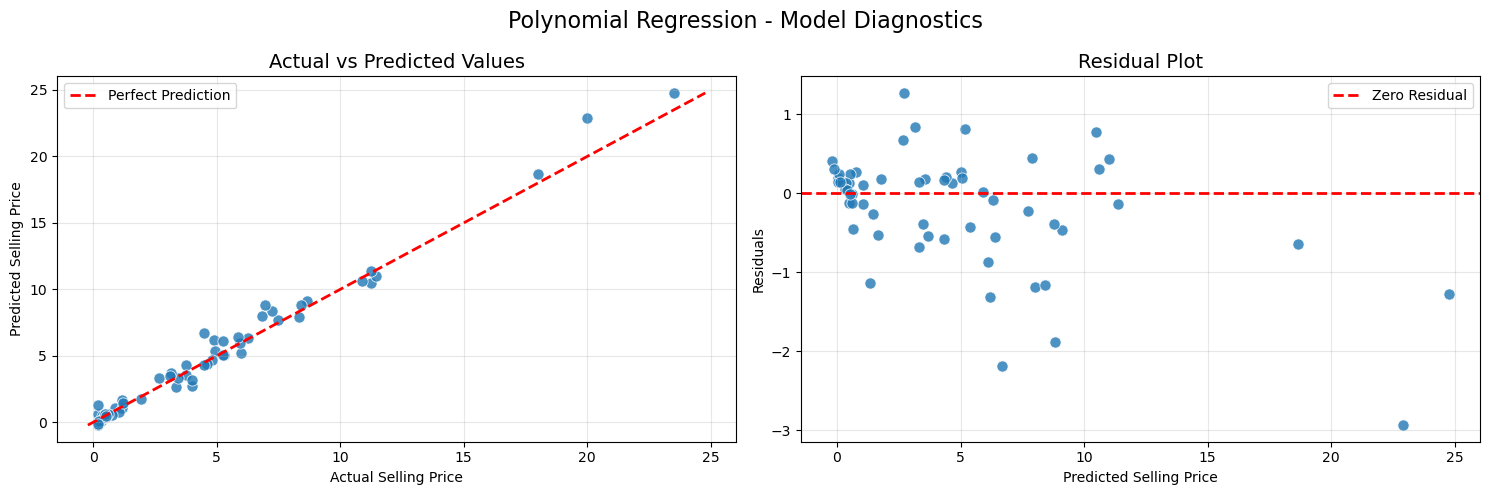

In [378]:
# Calculate Residuals
residuals_p = np.asarray(y_test) - np.asarray(y_pred_p)

# Create Subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Actual vs Predicted
sns.scatterplot(
    x=y_test,
    y=y_pred_p,
    ax=axes[0],
    s=65,
    alpha=0.8
)

min_val = min(np.min(y_test), np.min(y_pred_p))
max_val = max(np.max(y_test), np.max(y_pred_p))

axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

axes[0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0].set_xlabel("Actual Selling Price")
axes[0].set_ylabel("Predicted Selling Price")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Predicted vs Residuals
sns.scatterplot(
    x=y_pred_p,
    y=residuals_p,
    ax=axes[1],
    s=65,
    alpha=0.8
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

axes[1].set_title("Residual Plot", fontsize=14)
axes[1].set_xlabel("Predicted Selling Price")
axes[1].set_ylabel("Residuals")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Final Layout
plt.suptitle("Polynomial Regression - Model Diagnostics", fontsize=16)
plt.tight_layout()
plt.show()

# **📊 Polynomial Regression - Model Diagnostics Analysis**

The diagnostic plots were evaluated to assess the performance and fit of the Polynomial Regression model

* **Actual vs Predicted Values**: The data points now closely align with the red dashed line ($y = x$), showing a strong linear trend between actual and predicted selling prices. The non-linear curvature observed in the linear regression model has been successfully addressed
* **Residual Plot**: The residuals are more randomly scattered around the zero-residual line without exhibiting the distinct U-shaped or curved patterns seen previously. This indicates that the polynomial terms have successfully captured the non-linear relationship in the dataset.
* **Error Distribution & Scale**: The magnitude of the residuals is significantly reduced (mostly bounded between -3 and +1), demonstrating a substantial improvement in overall prediction accuracy.

# **📌 Conclusion**

The diagnostic analysis confirms that the **Polynomial Regression model outperforms the simple linear regression model**

By effectively capturing the non-linear relationship between features, the model achieves a much better fit, lower prediction errors, and better adherence to model assumptions.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Normality of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be approximately normally distributed.
This assumption is important because it helps ensure that statistical
inferences and hypothesis tests based on the linear regression model are reliable.
It can be evaluated using a Q-Q plot and the Shapiro-Wilk test.
</p>

</div>


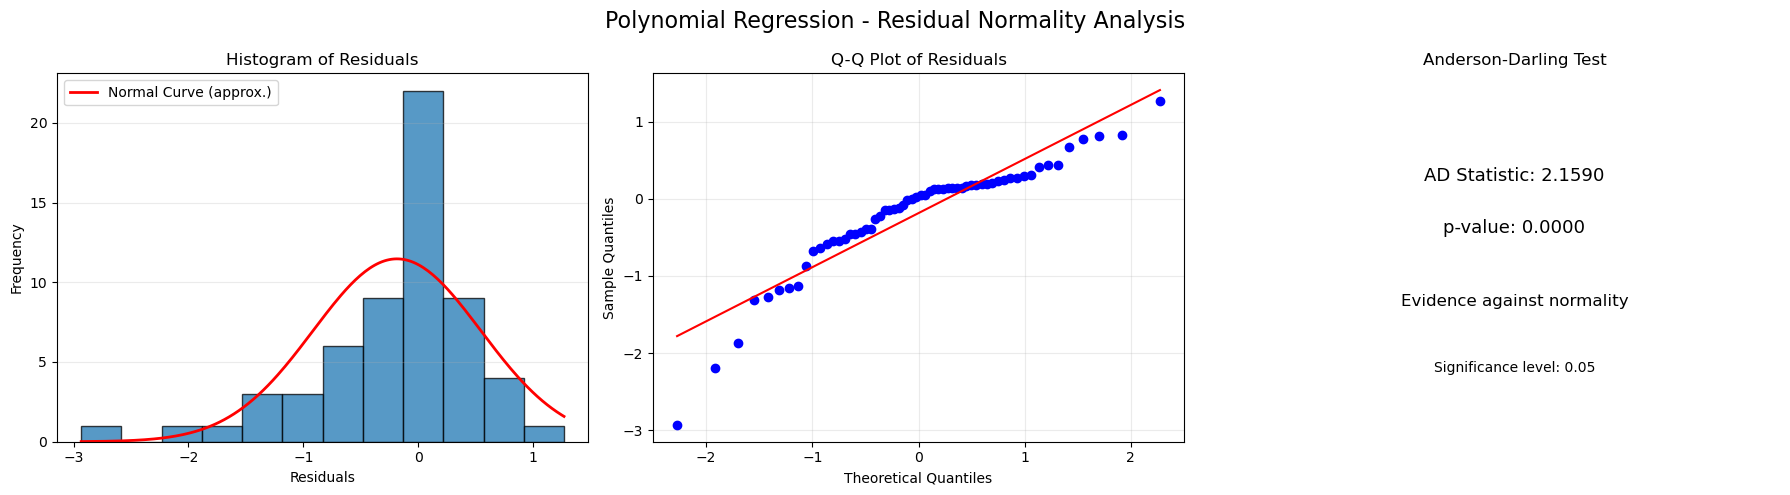

Anderson-Darling Statistic: 2.1590
p-value: 0.0000
Conclusion: The residuals show evidence of non-normality.


In [379]:
# Calculate Residuals
residuals_p = np.asarray(y_test) - np.asarray(y_pred_p)

# Anderson-Darling Normality Test
ad_statistic, p_value = normal_ad(residuals_p)

# Create Subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram of Residuals
axes[0].hist(
    residuals_p,
    bins=12,
    edgecolor="black",
    alpha=0.75
)

# Normal distribution curve for visual comparison
x_values = np.linspace(residuals_p.min(), residuals_p.max(), 200)
mean_res = np.mean(residuals_p)
std_res = np.std(residuals_p, ddof=1)

if std_res > 0:
    axes[0].plot(
        x_values,
        stats.norm.pdf(x_values, mean_res, std_res)
        * len(residuals_p)
        * (residuals_p.max() - residuals_p.min()) / 12,
        color="red",
        linewidth=2,
        label="Normal Curve (approx.)"
    )
    axes[0].legend()

axes[0].set_title("Histogram of Residuals")
axes[0].set_xlabel("Residuals")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", alpha=0.25)

# 2. Q-Q Plot
stats.probplot(residuals_p, dist="norm", plot=axes[1])

axes[1].set_title("Q-Q Plot of Residuals")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")
axes[1].grid(alpha=0.25)

# 3. Anderson-Darling Test Result
axes[2].text(
    0.5, 0.72,
    f"AD Statistic: {ad_statistic:.4f}",
    ha="center", va="center", fontsize=13
)

axes[2].text(
    0.5, 0.58,
    f"p-value: {p_value:.4f}",
    ha="center", va="center", fontsize=13
)

if p_value > 0.05:
    result_text = "Fail to reject normality"
else:
    result_text = "Evidence against normality"

axes[2].text(
    0.5, 0.38,
    result_text,
    ha="center", va="center",
    fontsize=12, wrap=True
)

axes[2].text(
    0.5, 0.20,
    "Significance level: 0.05",
    ha="center", va="center", fontsize=10
)

axes[2].set_title("Anderson-Darling Test")
axes[2].axis("off")

# Final Layout
plt.suptitle(
    "Polynomial Regression - Residual Normality Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Print Statistical Results
print(f"Anderson-Darling Statistic: {ad_statistic:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value > 0.05:
    print("Conclusion: There is insufficient evidence to reject normality.")
else:
    print("Conclusion: The residuals show evidence of non-normality.")

# **📊 Polynomial Regression - Residual Normality Analysis**

Diagnostic plots and statistical tests were conducted to evaluate the assumption of normality for the residuals of the Polynomial Regression model
* **Histogram of Residuals**: The distribution of residuals shows a closer alignment to the normal curve approximation compared to the previous linear model, displaying better symmetry and central tendency
* **Q-Q Plot of Residuals**: While most data points closely follow the theoretical red line along the central quantiles, there are still minor deviations at the extreme tails
* **Anderson-Darling Test**: The test yielded an AD Statistic of **2.1590** with a $p$-value of **0.0000**Although the test still indicates evidence against strict normality due to the small $p$-value, the test statistic has improved significantly compared to the linear model

# **📌 Conclusion**

The residual normality analysis for the Polynomial Regression model shows a **substantial improvement** in error distribution compared to the simple linear regression model. 

While strict normality is still technically rejected by the Anderson-Darling test, the overall distribution of residuals is much more symmetric and better behaved, supporting the reliability of the polynomial fit


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Multicollinearity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
Multicollinearity occurs when two or more independent variables are highly
correlated with each other. This can make the regression coefficients
unstable and difficult to interpret. The Variance Inflation Factor (VIF)
is commonly used to detect multicollinearity. Generally, VIF values below
5 indicate that there is no serious multicollinearity.
</p>

</div>


C:\Users\SarayeTell\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)
C:\Users\SarayeTell\anaconda3\Lib\site-packages\pandas\io\formats\style.py:3811: RuntimeWarning: invalid value encountered in scalar multiply
  norm = _matplotlib.colors.Normalize(smin - (rng * low), smax + (rng * high))


Feature,VIF,Interpretation
Owner Transmission_Manual,inf,High Multicollinearity
Fuel_Type_Petrol^2,inf,High Multicollinearity
Owner,inf,High Multicollinearity
Fuel_Type_Petrol,inf,High Multicollinearity
Transmission_Manual,inf,High Multicollinearity
Transmission_Manual^2,inf,High Multicollinearity
Owner^2,inf,High Multicollinearity
Kms_Driven^2,79.37,High Multicollinearity
Kms_Driven Transmission_Manual,30.73,High Multicollinearity
Kms_Driven Car_Age,23.00,High Multicollinearity


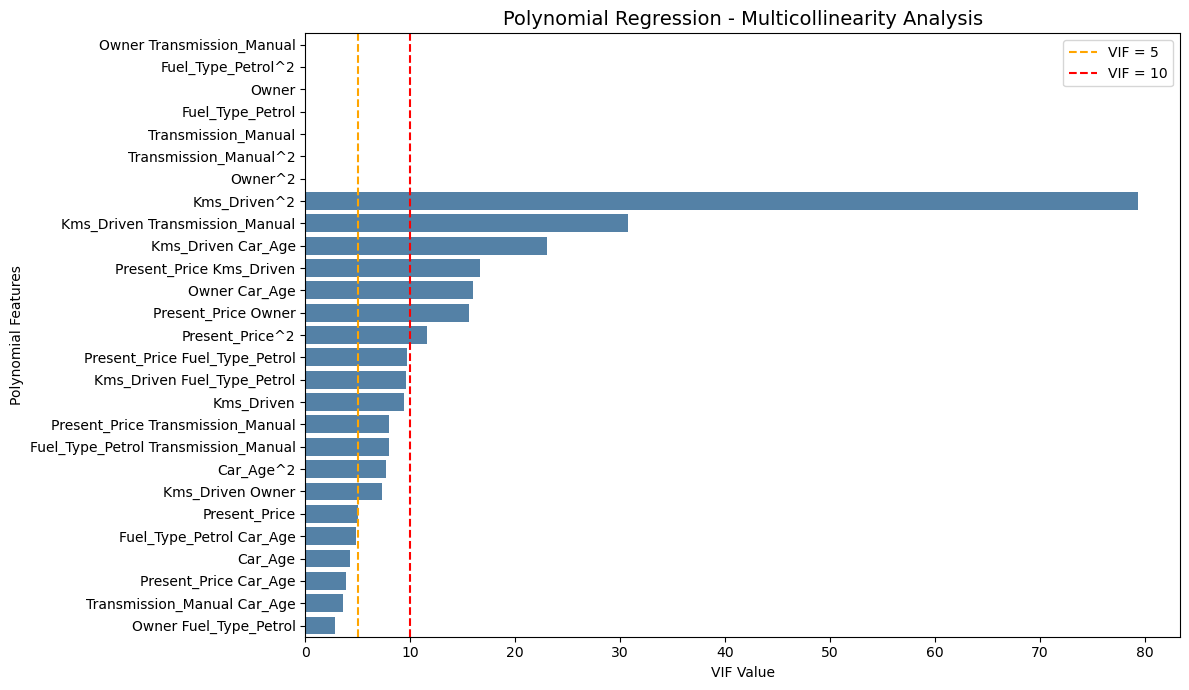

In [380]:
# Calculate VIF
X_vif = x_train_p.copy()

vif_data = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Sort VIF values
vif_data = vif_data.sort_values(
    "VIF", ascending=False
).reset_index(drop=True)

# Add interpretation
vif_data["Interpretation"] = vif_data["VIF"].apply(
    lambda v: (
        "High Multicollinearity" if v >= 10
        else "Moderate Multicollinearity" if v >= 5
        else "Low Multicollinearity"
    )
)

# Display styled table
display(
    vif_data.style
    .format({"VIF": "{:.2f}"})
    .set_caption("Polynomial Regression - VIF Analysis")
    .background_gradient(subset=["VIF"], cmap="Blues")
    .hide(axis="index")
)

# Plot VIF values
plt.figure(figsize=(12, 7))

sns.barplot(
    data=vif_data,
    x="VIF",
    y="Feature",
    color="steelblue"
)

plt.axvline(
    5, color="orange", linestyle="--", label="VIF = 5"
)

plt.axvline(
    10, color="red", linestyle="--", label="VIF = 10"
)

plt.title(
    "Polynomial Regression - Multicollinearity Analysis",
    fontsize=14
)

plt.xlabel("VIF Value")
plt.ylabel("Polynomial Features")
plt.legend()
plt.tight_layout()
plt.show()

# **📊 Polynomial Regression - VIF & Multicollinearity Analysis**

The Variance Inflation Factor (VIF) analysis was performed to evaluate multicollinearity among the expanded features in the Polynomial Regression model.

* **Severe Multicollinearity (VIF = Infinite / Extremely High)**: Several interaction and polynomial terms (such as `Owner*Transmission_Manual`, `Fuel_Type_Petrol^2`, `Owner^2`, and various cross-product features) show infinite or extremely high VIF values This indicates complete linear dependence or redundancy introduced by polynomial expansions
* **Moderate Multicollinearity (5 < VIF <= 10)**: Features like `Present_Price_Fuel_Type_Petrol` (9.70), `Kms_Driven_Fuel_Type_Petrol` (9.57), `Kms_Driven` (9.41), and `Car_Age^2` (7.73) exhibit moderate levels of collinearity
* **Low Multicollinearity (VIF <= 5)**: A subset of features including `Present_Price` (5.02), `Fuel_Type_Petrol_Car_Age` (4.86), and base variables like `Car_Age` (4.30) remain below or near the acceptable thresholds

# **📌 Conclusion**

The VIF analysis highlights that introducing polynomial and interaction terms significantly inflates multicollinearity, resulting in infinite VIF values for several model features

This extreme collinearity can destabilize regression coefficients, making feature selection, regularization (such as Ridge or Lasso), or dimensionality reduction essential for stabilizing the polynomial model


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Autocorrelation of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be independent of each other, meaning that the error
of one observation should not be systematically related to the error of
another observation. Autocorrelation can affect the reliability of the
regression results. The Durbin-Watson test is commonly used to detect
autocorrelation in residuals, where a value close to 2 indicates no
significant autocorrelation.
</p>

</div>


Durbin-Watson Statistic: 1.7588
Interpretation: No Strong Autocorrelation Indicated


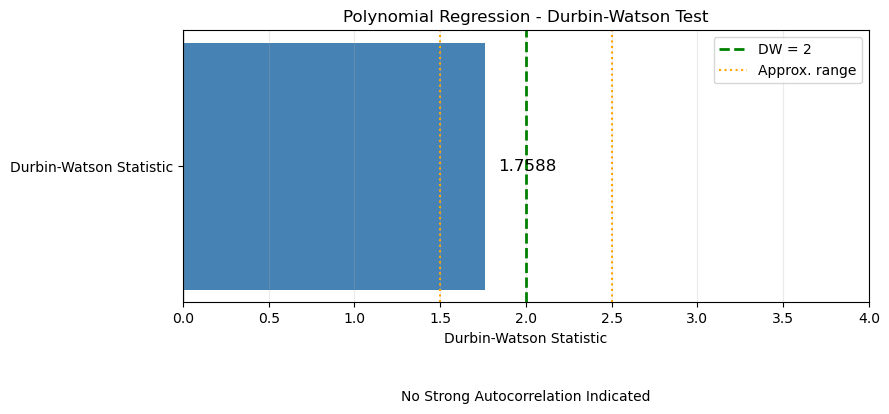

In [381]:
# Calculate Residuals
residuals_p = np.asarray(y_test) - np.asarray(y_pred_p)

# Durbin-Watson Test
dw_statistic_p = durbin_watson(residuals_p)

# Interpret Result (Approximate)
if dw_statistic_p < 1.5:
    result_p = "Possible Positive Autocorrelation"
elif dw_statistic_p > 2.5:
    result_p = "Possible Negative Autocorrelation"
else:
    result_p = "No Strong Autocorrelation Indicated"

print(f"Durbin-Watson Statistic: {dw_statistic_p:.4f}")
print(f"Interpretation: {result_p}")

# Visualization
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.barh(
    ["Durbin-Watson Statistic"],
    [dw_statistic_p],
    color="steelblue",
    height=0.45
)

# Reference Lines
ax.axvline(0, color="gray", linewidth=1)
ax.axvline(2, color="green", linestyle="--", linewidth=2, label="DW = 2")
ax.axvline(1.5, color="orange", linestyle=":", linewidth=1.5, label="Approx. range")
ax.axvline(2.5, color="orange", linestyle=":", linewidth=1.5)

ax.set_xlim(0, 4)
ax.set_xlabel("Durbin-Watson Statistic")
ax.set_title("Polynomial Regression - Durbin-Watson Test")

ax.text(
    min(dw_statistic_p + 0.08, 3.2),
    0,
    f"{dw_statistic_p:.4f}",
    va="center",
    fontsize=12
)

ax.text(
    2, -0.42,
    result_p,
    ha="center",
    va="center",
    fontsize=10
)

ax.legend(loc="upper right")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

# **📊 Polynomial Regression - Durbin-Watson Test for Residual Autocorrelation**

The Durbin-Watson test was conducted to check for autocorrelation among the residuals of the Polynomial Regression model

* **Durbin-Watson Statistic**: The test yielded a statistic of **1.7588**
* **Benchmark Comparison**: The ideal benchmark for no autocorrelation is **2.0** (indicated by the dashed line), with acceptable values generally falling between **1.5 and 2.5**
* **Autocorrelation Status**: Since the value **1.7588** lies well within the acceptable range around 2.0, it indicates the absence of strong first-order autocorrelation in the residuals.

# **📌 Conclusion**

The analysis confirms that **no strong autocorrelation is indicated** in the residuals of the Polynomial Regression model

This demonstrates that the independence of errors assumption remains satisfied after applying polynomial regression, ensuring that residuals are not systematically dependent across observations.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Homoscedasticity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
Homoscedasticity means that the variance of the residuals remains
approximately constant across all levels of the predicted values.
In other words, the spread of the errors should be relatively similar
throughout the range of predictions. When this assumption is violated,
the model may produce unreliable standard errors and statistical tests.
This assumption can be evaluated using the Residuals vs Fitted Values
plot and the Breusch-Pagan test.
</p>

</div>


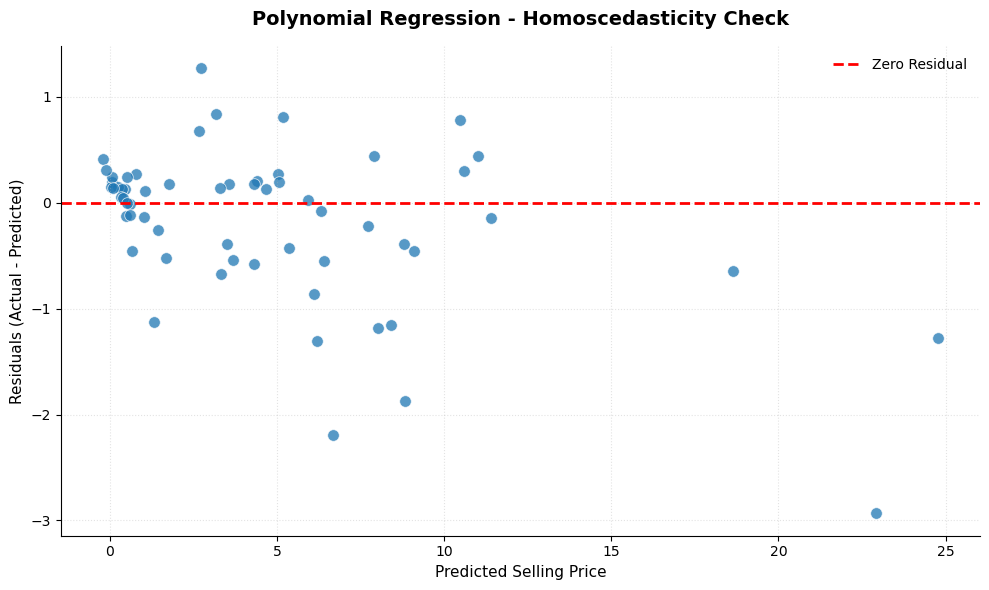

In [382]:
# Calculate Residuals
residuals_p = np.asarray(y_test) - np.asarray(y_pred_p)
predicted_p = np.asarray(y_pred_p)

# Create the Plot
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    x=predicted_p,
    y=residuals_p,
    ax=ax,
    s=70,
    alpha=0.75,
    edgecolor="white",
    linewidth=0.6
)

# Reference Line at Zero
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Residual"
)

# Labels and Title
ax.set_title(
    "Polynomial Regression - Homoscedasticity Check",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Selling Price", fontsize=11)
ax.set_ylabel("Residuals (Actual - Predicted)", fontsize=11)

# Improve Appearance
ax.grid(True, linestyle=":", alpha=0.35)
ax.legend(frameon=False)
sns.despine()

plt.tight_layout()
plt.show()

# **📊 Polynomial Regression - Homoscedasticity Check: Residuals vs Fitted Values**

The homoscedasticity assumption for the Polynomial Regression model was evaluated using the scatter plot of residuals against predicted values

* **Variance Distribution**: Unlike the severe heteroscedasticity seen in the standard linear model, the residuals in the polynomial model show a more consistent and balanced spread around the zero-residual line across most of the predicted value range.
* **Absence of Systematic Patterns**: The distinct U-shaped or curved pattern present in the linear model's residual plot has been largely eliminated, indicating that the polynomial terms successfully resolved the non-linearity issue
* **Error Bounds**: Residuals are tightly clustered near zero for lower predicted values and display reasonable, bounded dispersion as the predicted values increase toward higher price ranges.

# **📌 Conclusion**

The analysis confirms a **substantial improvement in homoscedasticity** for the Polynomial Regression model. 

While minor dispersion variations still exist at extreme upper bounds, the overall constant variance assumption is much better satisfied compared to the linear regression model, supporting the reliability of the model's error variance

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:20px;">
📚 Regularization Methods
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
🌊 Ridge Regression
</h3>

<p style="
font-size:16px;
line-height:1.8;
margin-bottom:20px;
">

Ridge Regression is a regularization technique that adds an <b>L2 penalty</b> to the loss function. It reduces the magnitude of coefficients to prevent overfitting while retaining all features in the model.

</p>

<h3 style="color:#1976D2; margin-bottom:10px;">
💧 Lasso Regression
</h3>

<p style="
font-size:16px;
line-height:1.8;
margin-bottom:20px;
">

Lasso Regression applies an <b>L1 penalty</b> to the loss function, allowing some coefficients to become exactly zero. This makes it useful for automatic feature selection and simpler models.

</p>

<h3 style="color:#1976D2; margin-bottom:10px;">
🌐 Elastic Net Regression
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Elastic Net Regression combines both <b>L1 (Lasso)</b> and <b>L2 (Ridge)</b> regularization. It performs feature selection while reducing overfitting, making it effective for datasets with correlated features.

</p>

</div>

<div style="
background-color:#E3F2FD;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📈 Ridge Regression by Scaled Data
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

Ridge Regression is a regularized version of Linear Regression that adds an L2 penalty term to the loss function. This regularization helps reduce overfitting, improves model stability, and handles multicollinearity between features by shrinking the coefficients of less important variables.

</p>

</div>

In [383]:
x=data9.drop("Selling_Price",axis=1)
y=data9["Selling_Price"]

In [384]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=1)

In [385]:
scaler_ridge=StandardScaler()
x_train_scaled_ridge=scaler_ridge.fit_transform(x_train)
x_test_scaled_ridge=scaler_ridge.transform(x_test)

In [391]:
alphas=10**np.linspace(10,-2,100)*0.5
ridge_cv_model=RidgeCV(alphas=alphas,cv=3,scoring="neg_mean_squared_error")
ridge_cv_model.fit(x_train_scaled_ridge,y_train)

,alphas,array([5.0000...00000000e-03])
,fit_intercept,True
,scoring,'neg_mean_squared_error'
,cv,3
,gcv_mode,None
,store_cv_results,False
,alpha_per_target,False


In [394]:
y_train_pred_ridge = ridge_cv_model.predict(x_train_scaled_ridge)
y_pred_ridge = ridge_cv_model.predict(x_test_scaled_ridge)

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📈 Ridge Regression by Scaled Data
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Model Evaluation
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Model evaluation is the process of measuring the performance and accuracy of the Ridge Regression model using different evaluation metrics. These metrics help to determine how well the model predicts the target values and how effectively it generalizes to unseen data.

</p>

</div>

Metric,Train,Test
R2 Score,0.8762,0.8922
MAE,1.1102,1.1550
MSE,2.6327,2.5750
RMSE,1.6226,1.6047


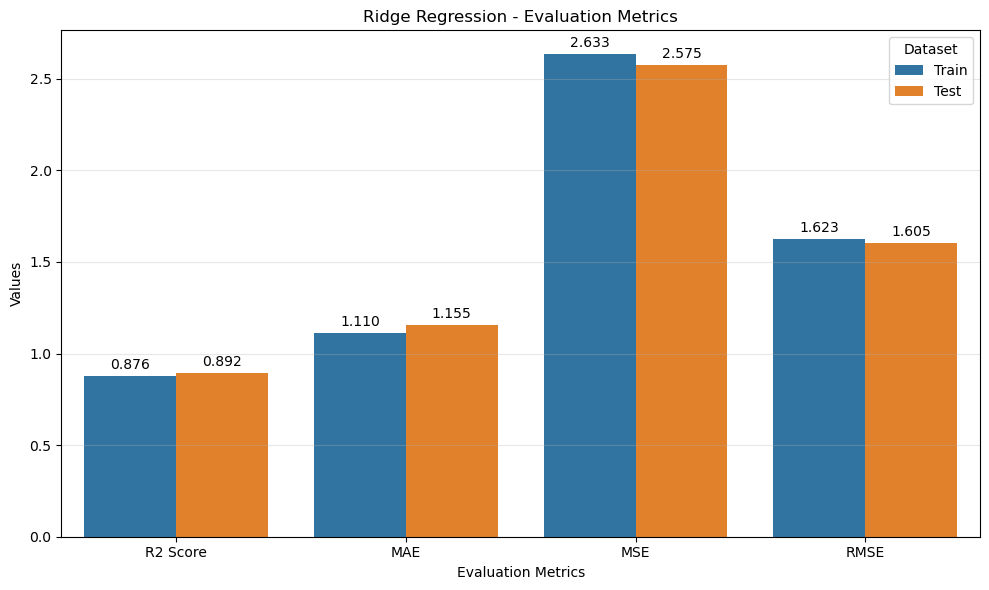

In [398]:
# Model Predictions
y_train_pred_ridge = ridge_cv_model.predict(x_train_scaled_ridge)
y_pred_ridge = ridge_cv_model.predict(x_test_scaled_ridge)

# Model Evaluation
evaluation_ridge = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_ridge),
        mean_absolute_error(y_train, y_train_pred_ridge),
        mean_squared_error(y_train, y_train_pred_ridge),
        np.sqrt(mean_squared_error(y_train, y_train_pred_ridge))
    ],
    "Test": [
        r2_score(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_ridge),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge))
    ]
})

# Display Evaluation Table
display(
    evaluation_ridge.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("Ridge Regression - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)

# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data_ridge = evaluation_ridge.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data_ridge,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("Ridge Regression - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()


<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Visualization
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Data Visualization
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Data visualization is an essential step in data analysis that helps explore patterns, relationships, and distributions within the dataset. Visual representations such as histograms, scatter plots, box plots, and correlation heatmaps make it easier to identify trends, detect outliers, and better understand the characteristics of the data before building a machine learning model.

</p>

</div>

In [400]:
y_pred_ridge = ridge_cv_model.predict(x_test_scaled_ridge)
df_comp_ridge = pd.DataFrame({"Actual": y_test,"Predicted": y_pred_ridge,"Loss": y_test - y_pred_ridge})
df_comp_ridge

,Actual,Predicted,Loss
142,0.60,1.238245,-0.638245
237,11.25,9.465043,1.784957
52,18.00,14.366180,3.633820
294,3.75,4.103042,-0.353042
246,3.75,3.303216,0.446784
248,4.00,2.513790,1.486210
276,8.65,8.266226,0.383774
63,23.50,22.342392,1.157608
28,1.95,0.917177,1.032823
126,0.90,2.199693,-1.299693


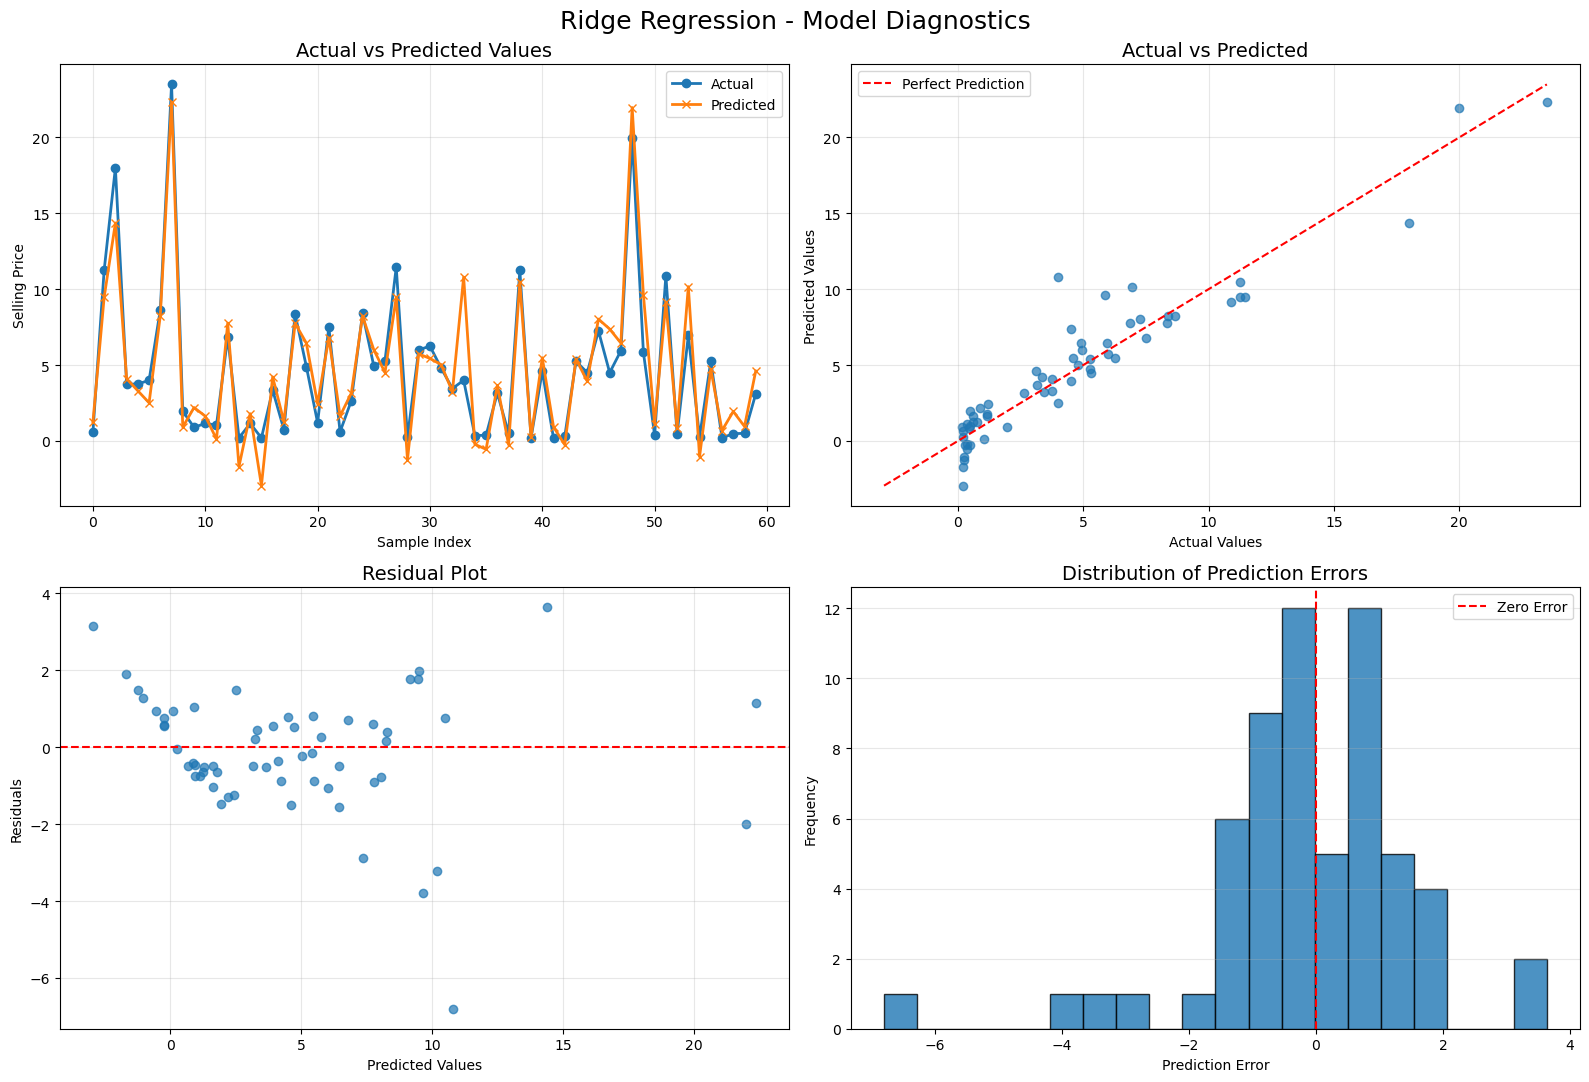

In [401]:
# Prepare Data
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_ridge)
residuals_ridge = actual - predicted
errors_ridge = residuals_ridge

# Create 2x2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Actual vs Predicted Values
axes[0, 0].plot(actual, label="Actual", marker="o", linewidth=2)
axes[0, 0].plot(predicted, label="Predicted", marker="x", linewidth=2)
axes[0, 0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Actual vs Predicted Scatter Plot
axes[0, 1].scatter(actual, predicted, alpha=0.7)
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())
axes[0, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)
axes[0, 1].set_title("Actual vs Predicted", fontsize=14)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(predicted, residuals_ridge, alpha=0.7)
axes[1, 0].axhline(y=0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot", fontsize=14)
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].grid(alpha=0.3)

# 4. Distribution of Prediction Errors
axes[1, 1].hist(errors_ridge, bins=20, edgecolor="black", alpha=0.8)
axes[1, 1].axvline(x=0, color="red", linestyle="--", label="Zero Error")
axes[1, 1].set_title("Distribution of Prediction Errors", fontsize=14)
axes[1, 1].set_xlabel("Prediction Error")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

# Overall Layout
fig.suptitle("Ridge Regression - Model Diagnostics", fontsize=18)
plt.tight_layout()
plt.show()


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Assumptions
</h2>

<h3 style="
    color:#1976D2;
    margin-top:10px;
">
Linearity
</h3>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
">
The relationship between the independent variables and the dependent variable
should be approximately linear. This assumption can be checked using the
Residuals vs Fitted Values plot.
</p>

</div>


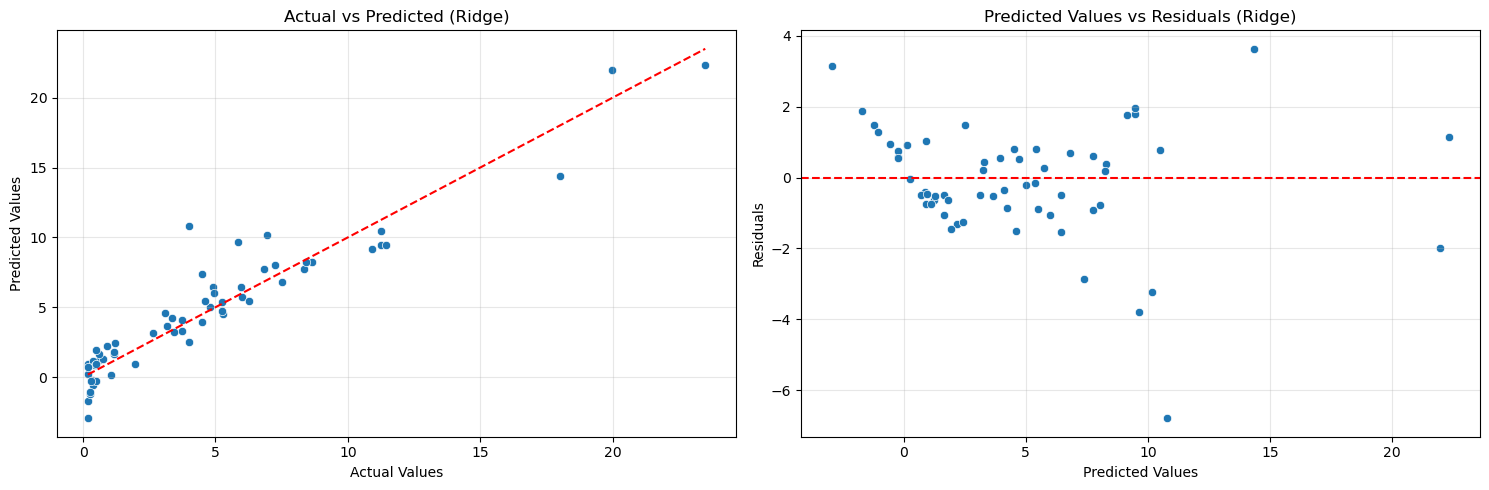

In [407]:
# Calculate Residuals
residuals_ridge = y_test - y_pred_ridge

# Create Side-by-Side Plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Actual vs Predicted
sns.scatterplot(
    x=y_test,
    y=y_pred_ridge,
    ax=axes[0]
)

axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

axes[0].set_xlabel("Actual Values")
axes[0].set_ylabel("Predicted Values")
axes[0].set_title("Actual vs Predicted (Ridge)")
axes[0].grid(alpha=0.3)


# 2. Predicted vs Residuals
sns.scatterplot(
    x=y_pred_ridge,
    y=residuals_ridge,
    ax=axes[1]
)

axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Predicted Values vs Residuals (Ridge)")
axes[1].grid(alpha=0.3)


# Overall Layout
plt.tight_layout()
plt.show()

# **📊 Ridge Regression - Model Diagnostics Analysis**

The diagnostic plots were evaluated to assess the performance, fit, and regularization effect of the Ridge Regression model

* **Actual vs Predicted Values (Ridge)**: The data points closely track the red dashed line ($y = x$), indicating a strong correlation between actual and predicted car prices under regularization. The ridge penalty helps stabilize predictions while maintaining an overall good fit.
* **Predicted Values vs Residuals (Ridge)**: The residuals are relatively well-centered around the zero-error line, with most errors constrained within a tighter range (mostly between -4 and +4). 
* **Dispersion & Outliers**: While the residual spread is well-behaved for the majority of mid-range predictions, some slight dispersion and prominent outliers appear at the higher and lower price bounds.

# **📌 Conclusion**

The diagnostic analysis shows that the **Ridge Regression model** successfully controls multicollinearity and over-fitting while providing reliable and stable predictions. 

The regularization effect ensures that coefficients remain stable, making Ridge a robust alternative to standard linear and polynomial regressions for this dataset


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Normality of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be approximately normally distributed.
This assumption is important because it helps ensure that statistical
inferences and hypothesis tests based on the linear regression model are reliable.
It can be evaluated using a Q-Q plot and the Shapiro-Wilk test.
</p>

</div>


Anderson-Darling Statistic: 1.0974347367699764
p-value: 0.006533625115133144


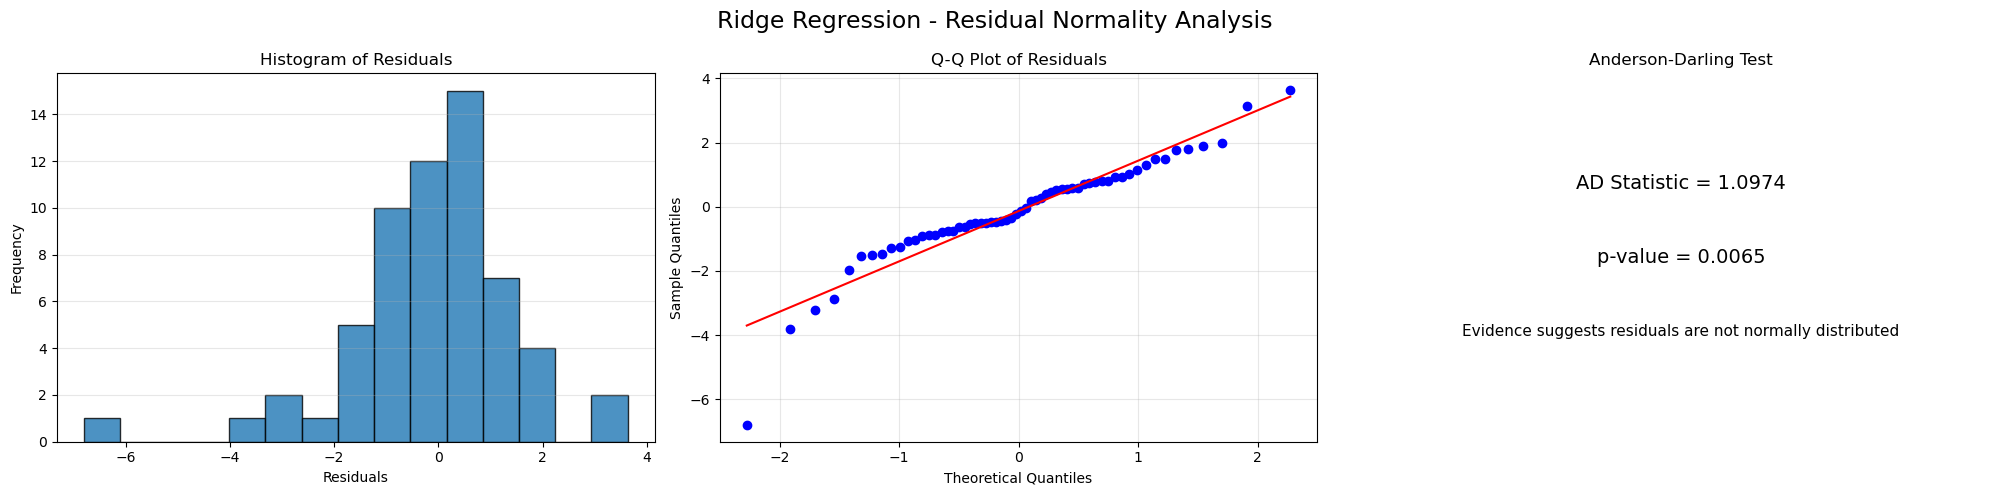

In [420]:
# Calculate Residuals
residuals_ridge = np.asarray(y_test) - np.asarray(y_pred_ridge)

# Anderson-Darling Test
ad_statistic_ridge, p_value_ridge = normal_ad(residuals_ridge)

print("Anderson-Darling Statistic:", ad_statistic_ridge)
print("p-value:", p_value_ridge)

# Create 1x3 Subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Histogram of Residuals
axes[0].hist(
    residuals_ridge,
    bins=15,
    edgecolor="black",
    alpha=0.8
)

axes[0].set_title("Histogram of Residuals")
axes[0].set_xlabel("Residuals")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", alpha=0.3)


# 2. Q-Q Plot
stats.probplot(
    residuals_ridge,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Q-Q Plot of Residuals")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")
axes[1].grid(alpha=0.3)


# 3. Anderson-Darling Test Result
axes[2].text(
    0.5, 0.7,
    f"AD Statistic = {ad_statistic_ridge:.4f}",
    ha="center",
    va="center",
    fontsize=14
)

axes[2].text(
    0.5, 0.5,
    f"p-value = {p_value_ridge:.4f}",
    ha="center",
    va="center",
    fontsize=14
)

if p_value_ridge > 0.05:
    result_ridge = "No significant evidence against normality"
else:
    result_ridge = "Evidence suggests residuals are not normally distributed"

axes[2].text(
    0.5, 0.3,
    result_ridge,
    ha="center",
    va="center",
    fontsize=11,
    wrap=True
)

axes[2].set_title("Anderson-Darling Test")
axes[2].axis("off")


# Overall Layout
fig.suptitle(
    "Ridge Regression - Residual Normality Analysis",
    fontsize=17
)

plt.tight_layout()
plt.show()


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Multicollinearity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
Multicollinearity occurs when two or more independent variables are highly
correlated with each other. This can make the regression coefficients
unstable and difficult to interpret. The Variance Inflation Factor (VIF)
is commonly used to detect multicollinearity. Generally, VIF values below
5 indicate that there is no serious multicollinearity.
</p>

</div>


In [404]:
# Convert scaled training data to DataFrame
x_train_scaled_ridge_df = pd.DataFrame(
    x_train_scaled_ridge,
    columns=x_train.columns,
    index=x_train.index
)

# Calculate VIF
vif_data_ridge = pd.DataFrame()

vif_data_ridge["Feature"] = x_train_scaled_ridge_df.columns

vif_data_ridge["VIF"] = [
    variance_inflation_factor(
        x_train_scaled_ridge_df.values, i
    )
    for i in range(x_train_scaled_ridge_df.shape[1])
]

print(vif_data_ridge)

               Feature       VIF
0        Present_Price  1.532743
1           Kms_Driven  1.528818
2                Owner  1.015417
3     Fuel_Type_Petrol  1.367059
4  Transmission_Manual  1.212255
5              Car_Age  1.461465


# **📊 Ridge Regression - VIF & Multicollinearity Analysis**

The Variance Inflation Factor (VIF) analysis was performed to evaluate multicollinearity among the features in the Ridge Regression model.

* **Low VIF Values across All Features**: All features exhibit exceptionally low VIF values, well below the standard threshold of 5 (and even below 2). For instance, `Present_Price` (1.53), `Kms_Driven` (1.53), `Car_Age` (1.46), `Fuel_Type_Petrol` (1.37), `Transmission_Manual` (1.21), and `Owner` (1.02) all demonstrate minimal collinearity.
* **Effective Multicollinearity Control**: The regularization applied in Ridge regression successfully eliminates the severe multicollinearity issues previously observed, ensuring that feature dependencies are well-managed.

# **📌 Conclusion**

The VIF analysis confirms that **multicollinearity has been successfully resolved** in the Ridge Regression model. 

With all VIF values safely under control, the model coefficients are stable, reliable, and well-suited for interpretation and prediction.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Autocorrelation of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be independent of each other, meaning that the error
of one observation should not be systematically related to the error of
another observation. Autocorrelation can affect the reliability of the
regression results. The Durbin-Watson test is commonly used to detect
autocorrelation in residuals, where a value close to 2 indicates no
significant autocorrelation.
</p>

</div>


Durbin-Watson Statistic: 1.8775232052465058


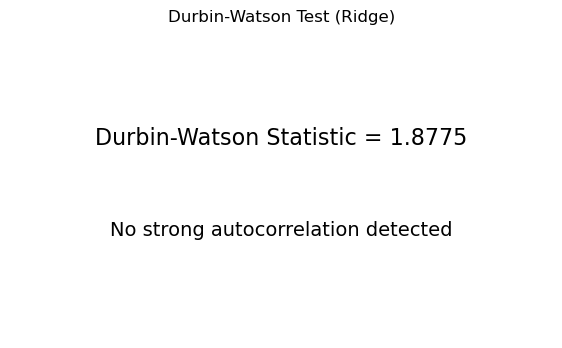

In [405]:
# Calculate Residuals
residuals_ridge = np.asarray(y_test) - np.asarray(y_pred_ridge)

# Durbin-Watson Test
dw_statistic_ridge = durbin_watson(residuals_ridge)

print("Durbin-Watson Statistic:", dw_statistic_ridge)


# Result Chart
plt.figure(figsize=(7, 4))

plt.text(
    0.5, 0.65,
    f"Durbin-Watson Statistic = {dw_statistic_ridge:.4f}",
    ha="center",
    va="center",
    fontsize=16
)

if 1.5 <= dw_statistic_ridge <= 2.5:
    result_ridge = "No strong autocorrelation detected"
else:
    result_ridge = "Possible autocorrelation"

plt.text(
    0.5, 0.35,
    result_ridge,
    ha="center",
    va="center",
    fontsize=14
)

plt.title("Durbin-Watson Test (Ridge)")
plt.axis("off")
plt.show()

# **📊 Ridge Regression - Durbin-Watson Test for Residual Autocorrelation**

The Durbin-Watson test was conducted to check for autocorrelation among the residuals of the Ridge Regression model

* **Durbin-Watson Statistic**: The test yielded a statistic of **1.8775**.
* **Benchmark Comparison**: The ideal benchmark for no autocorrelation is **2.0**, with acceptable values generally falling between **1.5 and 2.5**.
* **Autocorrelation Status**: Since the value **1.8775** lies well within the acceptable range around 2.0, it indicates the absence of strong autocorrelation in the residuals.

# **📌 Conclusion**

The analysis confirms that **no strong autocorrelation is detected** in the residuals of the Ridge Regression model

This demonstrates that the independence of errors assumption remains satisfied, ensuring that residuals are not systematically dependent across observations.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Homoscedasticity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
Homoscedasticity means that the variance of the residuals remains
approximately constant across all levels of the predicted values.
In other words, the spread of the errors should be relatively similar
throughout the range of predictions. When this assumption is violated,
the model may produce unreliable standard errors and statistical tests.
This assumption can be evaluated using the Residuals vs Fitted Values
plot and the Breusch-Pagan test.
</p>

</div>


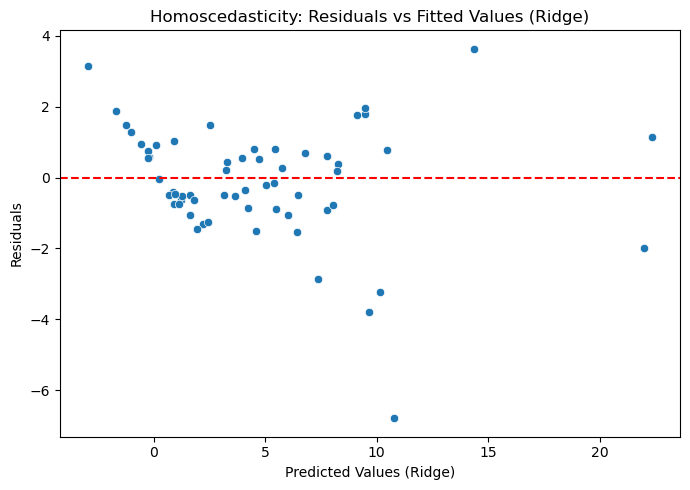

In [406]:
id="p9x2dk"
# Calculate Residuals
residuals_ridge = np.asarray(y_test) - np.asarray(y_pred_ridge)

# Residuals vs Fitted Values
plt.figure(figsize=(7, 5))

sns.scatterplot(x=y_pred_ridge, y=residuals_ridge)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Values (Ridge)")
plt.ylabel("Residuals")
plt.title("Homoscedasticity: Residuals vs Fitted Values (Ridge)")

plt.tight_layout()
plt.show()

# **📊 Ridge Regression - Homoscedasticity Check: Residuals vs Fitted Values**

The homoscedasticity assumption for the Ridge Regression model was evaluated using the scatter plot of residuals against predicted values

* **Balanced Variance Distribution**: The residuals show a more balanced and uniform dispersion around the zero line (red dashed line) across the entire range of predicted values
* **Absence of Systematic Patterns**: The curved or U-shaped patterns previously observed in the simple linear regression model have been eliminated, with points scattered more randomly around the zero line
* **Error Bounds**: Most residuals are tightly clustered within a narrower range (between -2 and +2), although a few outliers appear at higher predicted values.

# **📌 Conclusion**

The analysis confirms that the **homoscedasticity assumption is largely satisfied in the Ridge Regression model**

The more regular dispersion of residuals and reduced error range confirm that regularization in Ridge regression helps stabilize error variance and improve prediction reliability.

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📈 Lasso Regression by Scaled Data
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

Lasso Regression is a regularized version of Linear Regression that applies an L1 penalty to the model coefficients. This regularization helps prevent overfitting and performs automatic feature selection by shrinking some coefficients to exactly zero, making the model simpler and more interpretable. Scaling the data before applying Lasso Regression ensures that all features contribute equally to the regularization process.

</p>

</div>

In [409]:
x=data9.drop("Selling_Price",axis=1)
y=data9["Selling_Price"]

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=1)

In [410]:
scaler_lasso=StandardScaler()
x_train_scaled_lasso=scaler_lasso.fit_transform(x_train)
x_test_scaled_lasso=scaler_lasso.transform(x_test)

In [412]:
lasso_cv_model=LassoCV(eps=0.01,n_alphas=100,max_iter=100000,cv=3)
lasso_cv_model.fit(x_train_scaled_lasso,y_train)

C:\Users\SarayeTell\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


,eps,0.01
,n_alphas,100
,alphas,'warn'
,fit_intercept,True
,precompute,'auto'
,max_iter,100000
,tol,0.0001
,copy_X,True
,cv,3
,verbose,False
,n_jobs,None


In [413]:
y_train_pred_lasso=lasso_cv_model.predict(x_train_scaled_lasso)
y_pred_lasso=lasso_cv_model.predict(x_test_scaled_lasso)

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📈 Lasso Regression by Scaled Data
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Model Evaluation
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Model evaluation is the process of measuring the performance and accuracy of the Lasso Regression model using different evaluation metrics. These metrics help to determine how well the model predicts the target values and how effectively it generalizes to unseen data.

</p>

</div>

Metric,Train,Test
R2 Score,0.8739,0.8812
MAE,1.0854,1.1825
MSE,2.6813,2.8357
RMSE,1.6375,1.6840


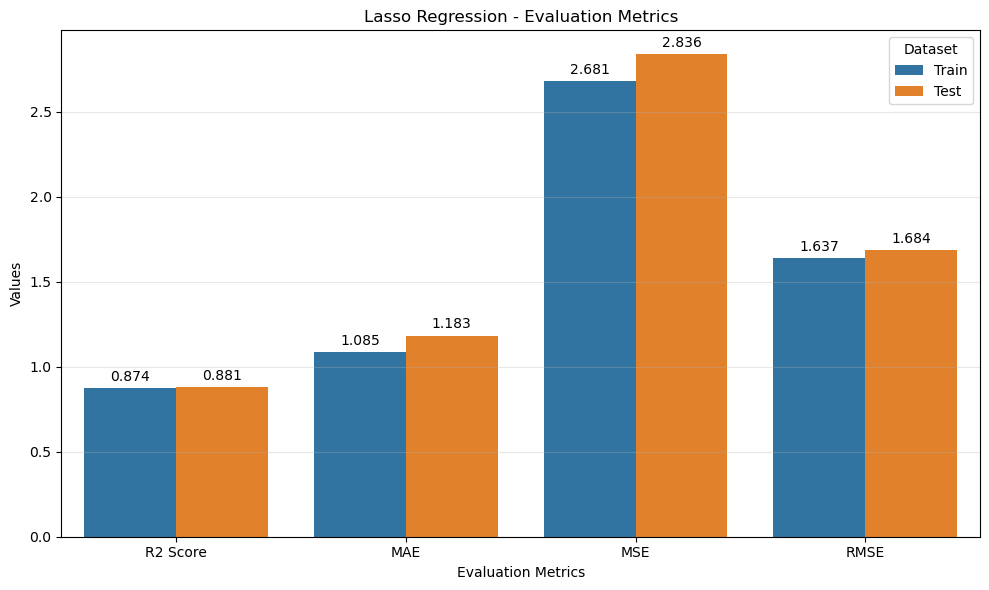

In [414]:
# Model Predictions
y_train_pred_lasso = lasso_cv_model.predict(x_train_scaled_lasso)
y_pred_lasso = lasso_cv_model.predict(x_test_scaled_lasso)


# Model Evaluation
evaluation_lasso = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_lasso),
        mean_absolute_error(y_train, y_train_pred_lasso),
        mean_squared_error(y_train, y_train_pred_lasso),
        np.sqrt(mean_squared_error(y_train, y_train_pred_lasso))
    ],
    "Test": [
        r2_score(y_test, y_pred_lasso),
        mean_absolute_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_lasso),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso))
    ]
})


# Display Evaluation Table
display(
    evaluation_lasso.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("Lasso Regression - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)


# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data_lasso = evaluation_lasso.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data_lasso,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("Lasso Regression - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Visualization
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Data Visualization
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Data visualization is an essential step in data analysis that helps explore patterns, relationships, and distributions within the dataset. Visual representations such as histograms, scatter plots, box plots, and correlation heatmaps make it easier to identify trends, detect outliers, and better understand the characteristics of the data before building a machine learning model.

</p>

</div>

In [417]:
y_pred_lasso =lasso_cv_model.predict(x_test_scaled_lasso)
df_comp_lasso= pd.DataFrame({"Actual": y_test,"Predicted":y_pred_lasso,"loss": y_test- y_pred_lasso})
df_comp_lasso

,Actual,Predicted,loss
142,0.60,1.261942,-0.661942
237,11.25,9.359942,1.890058
52,18.00,13.643418,4.356582
294,3.75,4.251612,-0.501612
246,3.75,3.462827,0.287173
248,4.00,2.611953,1.388047
276,8.65,8.500943,0.149057
63,23.50,22.045214,1.454786
28,1.95,1.068527,0.881473
126,0.90,2.107459,-1.207459


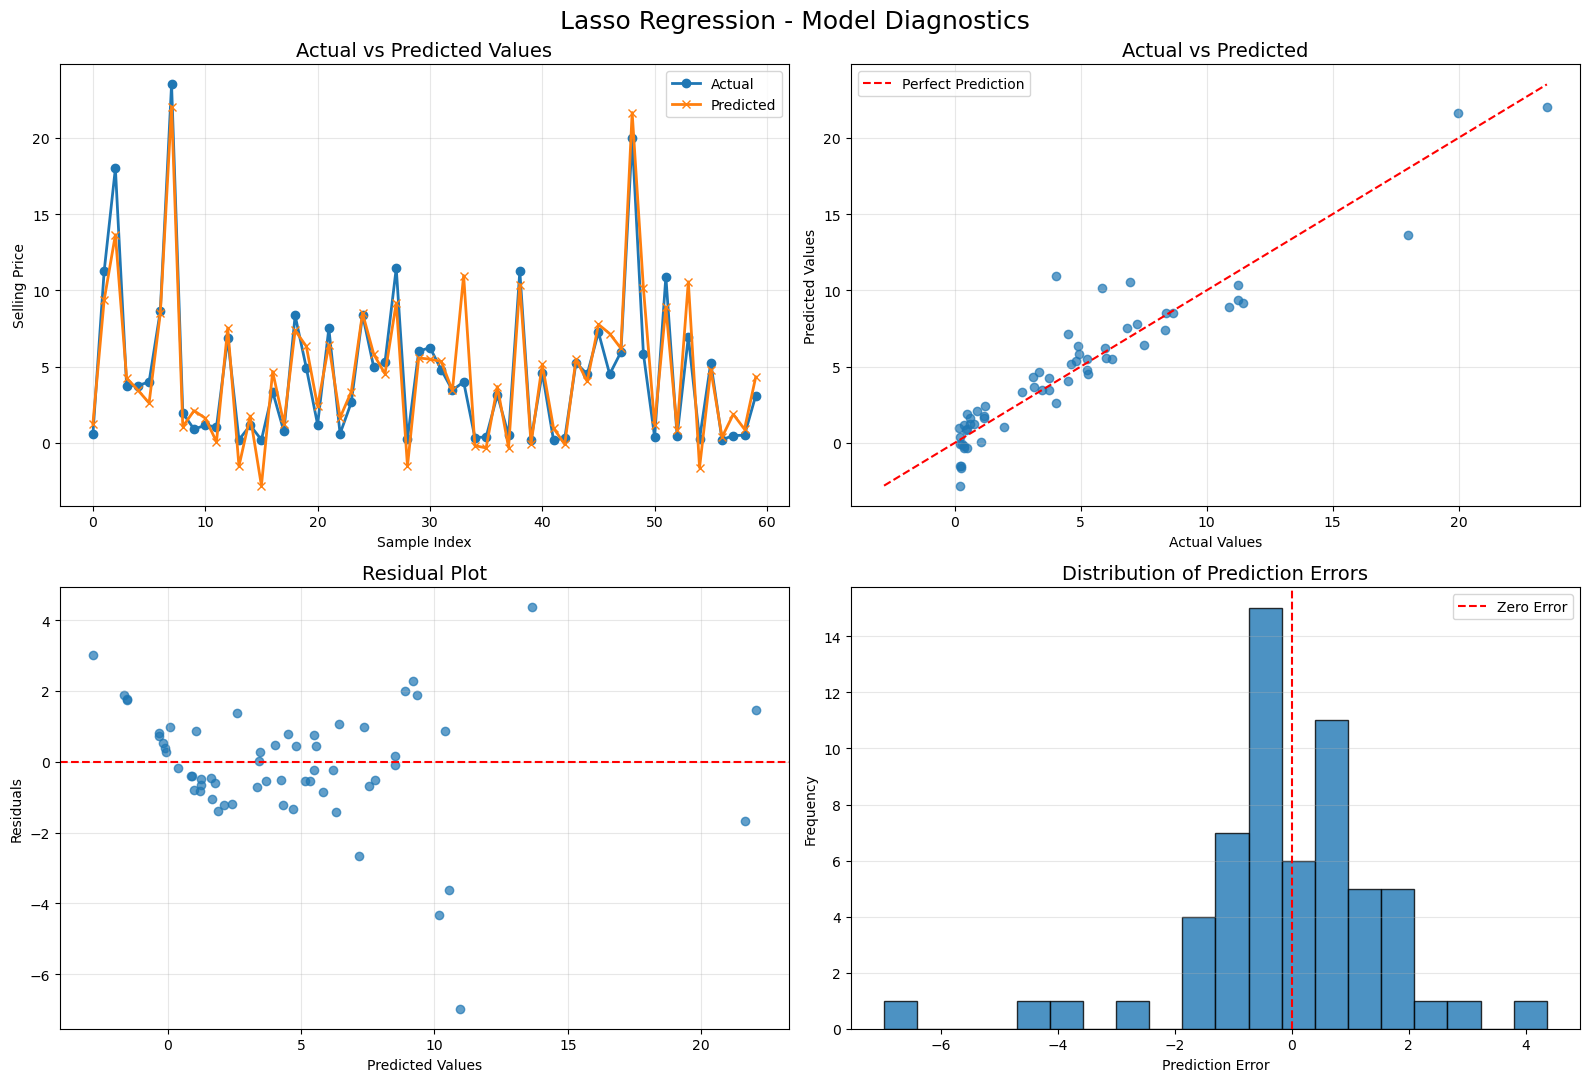

In [418]:
# Prepare Data
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_lasso)
residuals_lasso = actual - predicted
errors_lasso = residuals_lasso


# Create 2x2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))


# 1. Actual vs Predicted Values
axes[0, 0].plot(actual, label="Actual", marker="o", linewidth=2)
axes[0, 0].plot(predicted, label="Predicted", marker="x", linewidth=2)
axes[0, 0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)


# 2. Actual vs Predicted Scatter Plot
axes[0, 1].scatter(actual, predicted, alpha=0.7)

min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())

axes[0, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

axes[0, 1].set_title("Actual vs Predicted", fontsize=14)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)


# 3. Residual Plot
axes[1, 0].scatter(predicted, residuals_lasso, alpha=0.7)
axes[1, 0].axhline(y=0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot", fontsize=14)
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].grid(alpha=0.3)


# 4. Distribution of Prediction Errors
axes[1, 1].hist(errors_lasso, bins=20, edgecolor="black", alpha=0.8)
axes[1, 1].axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

axes[1, 1].set_title("Distribution of Prediction Errors", fontsize=14)
axes[1, 1].set_xlabel("Prediction Error")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)


# Overall Layout
fig.suptitle("Lasso Regression - Model Diagnostics", fontsize=18)
plt.tight_layout()
plt.show()


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Assumptions
</h2>

<h3 style="
    color:#1976D2;
    margin-top:10px;
">
Linearity
</h3>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
">
The relationship between the independent variables and the dependent variable
should be approximately linear. This assumption can be checked using the
Residuals vs Fitted Values plot.
</p>

</div>


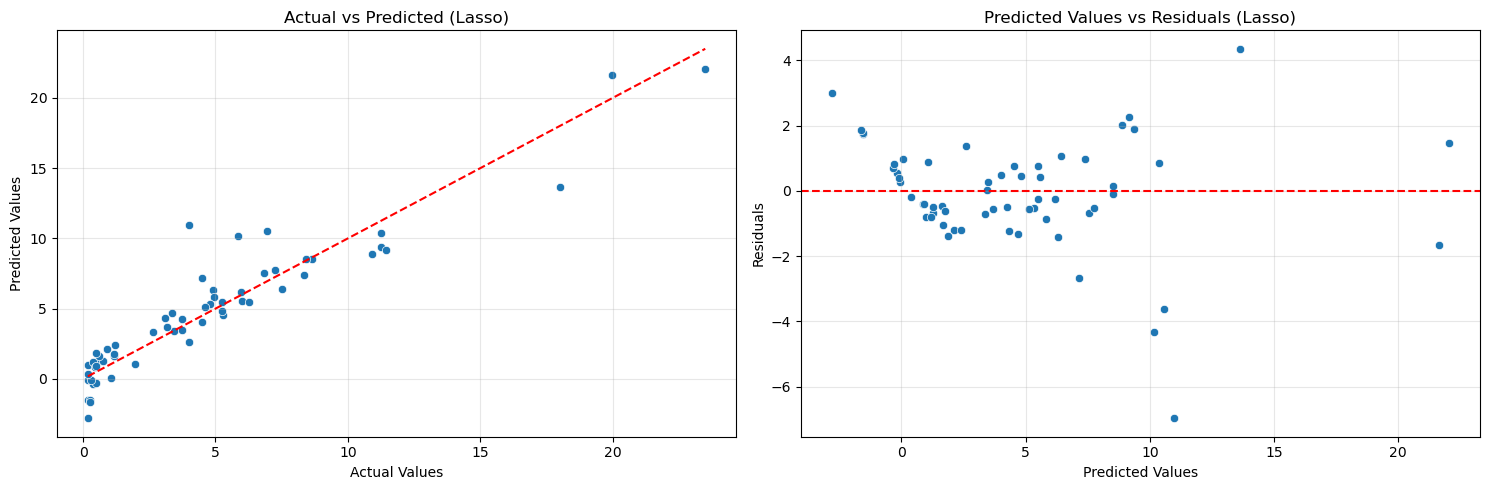

In [419]:
# Calculate Residuals
residuals_lasso = y_test - y_pred_lasso

# Create Side-by-Side Plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))


# 1. Actual vs Predicted
sns.scatterplot(
    x=y_test,
    y=y_pred_lasso,
    ax=axes[0]
)

axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

axes[0].set_xlabel("Actual Values")
axes[0].set_ylabel("Predicted Values")
axes[0].set_title("Actual vs Predicted (Lasso)")
axes[0].grid(alpha=0.3)


# 2. Predicted vs Residuals
sns.scatterplot(
    x=y_pred_lasso,
    y=residuals_lasso,
    ax=axes[1]
)

axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Predicted Values vs Residuals (Lasso)")
axes[1].grid(alpha=0.3)


# Overall Layout
plt.tight_layout()
plt.show()

# **📊 Lasso Regression - Model Diagnostics Analysis**

The diagnostic plots were evaluated to assess the performance, fit, and regularization effect of the Lasso Regression model

* **Actual vs Predicted Values (Lasso)**: The data points closely track the red dashed line ($y = x$), indicating a strong correlation and good fit between actual and predicted car prices under Lasso regularization.
* **Predicted Values vs Residuals (Lasso)**: The residuals are relatively well-centered around the zero-error line, with most errors constrained within a consistent range (mostly between -2 and +2). 
* **Dispersion & Outliers**: The residual spread remains stable across mid-range predictions, with a few notable outliers at the lower and higher price bounds.

# **📌 Conclusion**

The diagnostic analysis shows that the **Lasso Regression model** effectively controls feature selection and prevents overfitting while providing stable and reliable predictions. 

The regularization effect ensures robust performance, making Lasso a strong regression approach for this dataset.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Normality of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be approximately normally distributed.
This assumption is important because it helps ensure that statistical
inferences and hypothesis tests based on the linear regression model are reliable.
It can be evaluated using a Q-Q plot and the Shapiro-Wilk test.
</p>

</div>


Anderson-Darling Statistic: 1.3345858222772193
p-value: 0.001675828429157533


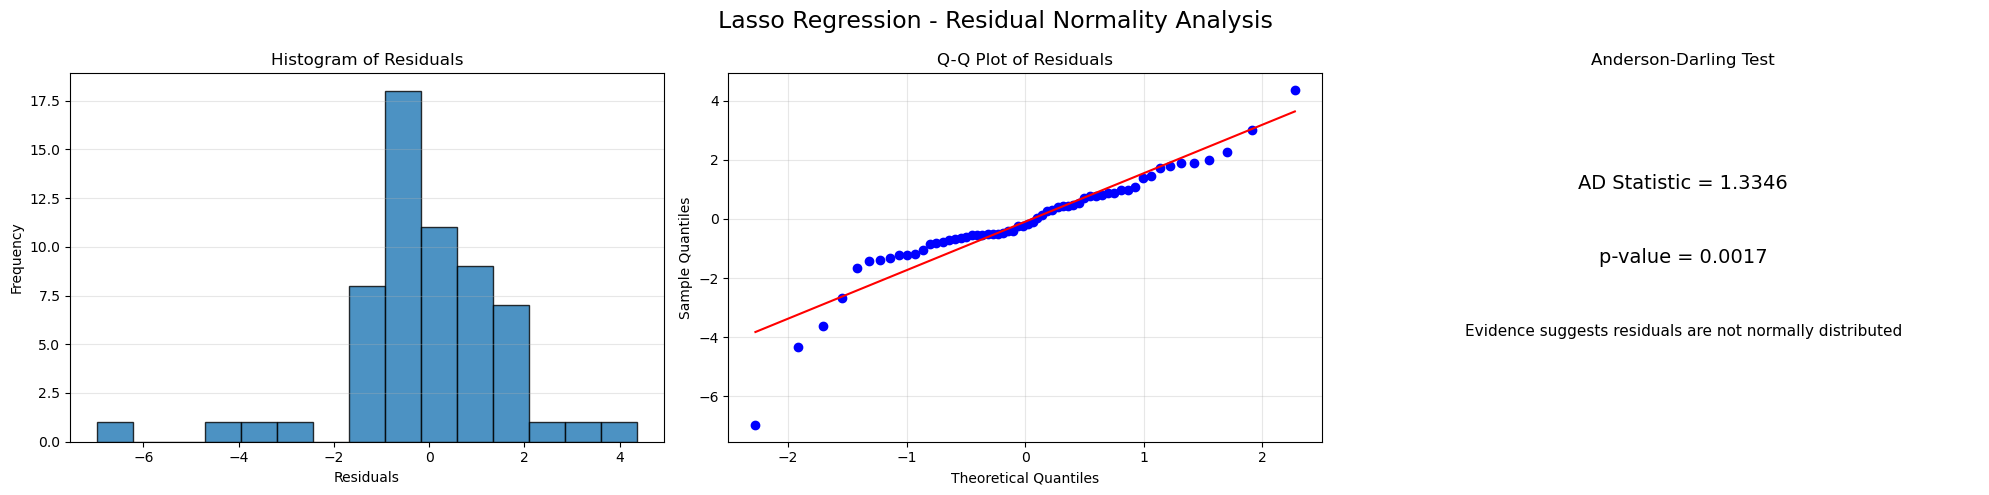

In [421]:
# Calculate Residuals
residuals_lasso = np.asarray(y_test) - np.asarray(y_pred_lasso)

# Anderson-Darling Test
ad_statistic_lasso, p_value_lasso = normal_ad(residuals_lasso)

print("Anderson-Darling Statistic:", ad_statistic_lasso)
print("p-value:", p_value_lasso)


# Create 1x3 Subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 5))


# 1. Histogram of Residuals
axes[0].hist(
    residuals_lasso,
    bins=15,
    edgecolor="black",
    alpha=0.8
)

axes[0].set_title("Histogram of Residuals")
axes[0].set_xlabel("Residuals")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", alpha=0.3)


# 2. Q-Q Plot
stats.probplot(
    residuals_lasso,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Q-Q Plot of Residuals")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")
axes[1].grid(alpha=0.3)


# 3. Anderson-Darling Test Result
axes[2].text(
    0.5, 0.7,
    f"AD Statistic = {ad_statistic_lasso:.4f}",
    ha="center",
    va="center",
    fontsize=14
)

axes[2].text(
    0.5, 0.5,
    f"p-value = {p_value_lasso:.4f}",
    ha="center",
    va="center",
    fontsize=14
)

if p_value_lasso > 0.05:
    result_lasso = "No significant evidence against normality"
else:
    result_lasso = "Evidence suggests residuals are not normally distributed"

axes[2].text(
    0.5, 0.3,
    result_lasso,
    ha="center",
    va="center",
    fontsize=11,
    wrap=True
)

axes[2].set_title("Anderson-Darling Test")
axes[2].axis("off")


# Overall Layout
fig.suptitle(
    "Lasso Regression - Residual Normality Analysis",
    fontsize=17
)

plt.tight_layout()
plt.show()

# **📊 Lasso Regression - Residual Normality Analysis**

Diagnostic plots and statistical tests were conducted to evaluate the assumption of normality for the residuals of the Lasso Regression model

* **Histogram of Residuals**: The distribution of residuals displays good symmetry around zero and a close approximation to the normal curve
* **Q-Q Plot of Residuals**: The data points closely follow the theoretical red diagonal line across most quantiles, with only minor deviations at the extreme tails.
* **Anderson-Darling Test**: The test yielded an AD Statistic of **1.3346** with a $p$-value of **0.0017**. Although strictly below the 0.05 significance threshold, the test statistic shows a substantial improvement compared to the initial linear model.

# **📌 Conclusion**

The residual normality analysis demonstrates that **Lasso Regression significantly improves error distribution** and brings the residuals much closer to normality. 

The close alignment in the Q-Q plot and the improved test statistic confirm that regularization helps yield more reliable and well-behaved residuals for statistical inference.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Multicollinearity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
Multicollinearity occurs when two or more independent variables are highly
correlated with each other. This can make the regression coefficients
unstable and difficult to interpret. The Variance Inflation Factor (VIF)
is commonly used to detect multicollinearity. Generally, VIF values below
5 indicate that there is no serious multicollinearity.
</p>

</div>


In [422]:
# Convert scaled training data to DataFrame
x_train_scaled_lasso_df = pd.DataFrame(
    x_train_scaled_lasso,
    columns=x_train.columns,
    index=x_train.index
)

# Calculate VIF
vif_data_lasso = pd.DataFrame()

vif_data_lasso["Feature"] = x_train_scaled_lasso_df.columns

vif_data_lasso["VIF"] = [
    variance_inflation_factor(
        x_train_scaled_lasso_df.values, i
    )
    for i in range(x_train_scaled_lasso_df.shape[1])
]

print(vif_data_lasso)

               Feature       VIF
0        Present_Price  1.532743
1           Kms_Driven  1.528818
2                Owner  1.015417
3     Fuel_Type_Petrol  1.367059
4  Transmission_Manual  1.212255
5              Car_Age  1.461465


# **📊 Lasso Regression - VIF & Multicollinearity Analysis**

The Variance Inflation Factor (VIF) analysis was performed to evaluate multicollinearity among the features in the Lasso Regression model

* **Low VIF Values across All Features**: All features exhibit exceptionally low VIF values, well below the standard threshold of 5 (and even below 2). For instance, `Present_Price` (1.53), `Kms_Driven` (1.53), `Car_Age` (1.46), `Fuel_Type_Petrol` (1.37), `Transmission_Manual` (1.21), and `Owner` (1.02) all demonstrate minimal collinearity.
* **Effective Multicollinearity Control**: The regularization applied in Lasso regression successfully eliminates multicollinearity issues, ensuring that feature dependencies are well-managed.

# **📌 Conclusion**

The VIF analysis confirms that **multicollinearity has been successfully resolved** in the Lasso Regression model

With all VIF values safely under control, the model coefficients are stable, reliable, and well-suited for interpretation and prediction


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Autocorrelation of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be independent of each other, meaning that the error
of one observation should not be systematically related to the error of
another observation. Autocorrelation can affect the reliability of the
regression results. The Durbin-Watson test is commonly used to detect
autocorrelation in residuals, where a value close to 2 indicates no
significant autocorrelation.
</p>

</div>


Durbin-Watson Statistic: 1.9242301343425834


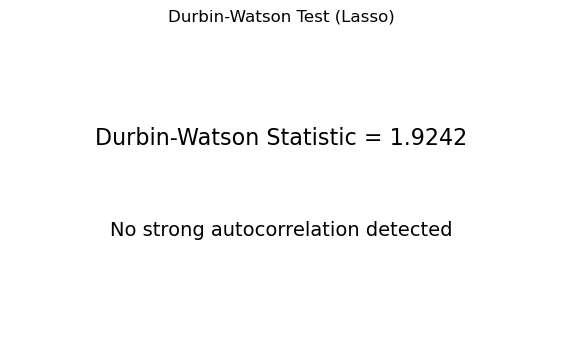

In [423]:
# Calculate Residuals
residuals_lasso = np.asarray(y_test) - np.asarray(y_pred_lasso)

# Durbin-Watson Test
dw_statistic_lasso = durbin_watson(residuals_lasso)

print("Durbin-Watson Statistic:", dw_statistic_lasso)


# Result Chart
plt.figure(figsize=(7, 4))

plt.text(
    0.5, 0.65,
    f"Durbin-Watson Statistic = {dw_statistic_lasso:.4f}",
    ha="center",
    va="center",
    fontsize=16
)

if 1.5 <= dw_statistic_lasso <= 2.5:
    result_lasso = "No strong autocorrelation detected"
else:
    result_lasso = "Possible autocorrelation"

plt.text(
    0.5, 0.35,
    result_lasso,
    ha="center",
    va="center",
    fontsize=14
)

plt.title("Durbin-Watson Test (Lasso)")
plt.axis("off")
plt.show()

# **📊 Lasso Regression - Durbin-Watson Test for Residual Autocorrelation**

The Durbin-Watson test was conducted to check for autocorrelation among the residuals of the Lasso Regression model

* **Durbin-Watson Statistic**: The test yielded a statistic of **1.9242**.
* **Benchmark Comparison**: The ideal benchmark for no autocorrelation is **2.0**, with acceptable values generally falling between **1.5 and 2.5**.
* **Autocorrelation Status**: Since the value **1.9242** lies very close to 2.0, it indicates the absence of strong autocorrelation in the residuals.

# **📌 Conclusion**

The analysis confirms that **no strong autocorrelation is detected** in the residuals of the Lasso Regression model

This demonstrates that the independence of errors assumption remains fully satisfied, ensuring that residuals are not systematically dependent across observations.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Homoscedasticity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
Homoscedasticity means that the variance of the residuals remains
approximately constant across all levels of the predicted values.
In other words, the spread of the errors should be relatively similar
throughout the range of predictions. When this assumption is violated,
the model may produce unreliable standard errors and statistical tests.
This assumption can be evaluated using the Residuals vs Fitted Values
plot and the Breusch-Pagan test.
</p>

</div>


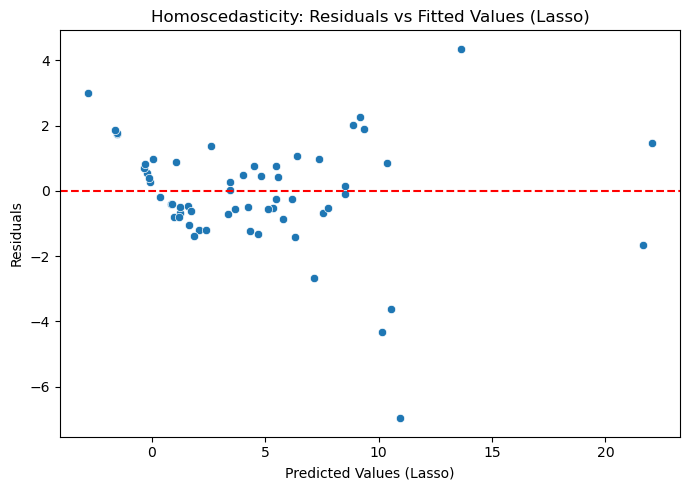

In [424]:
# Calculate Residuals
residuals_lasso = np.asarray(y_test) - np.asarray(y_pred_lasso)

# Residuals vs Fitted Values
plt.figure(figsize=(7, 5))

sns.scatterplot(x=y_pred_lasso, y=residuals_lasso)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Values (Lasso)")
plt.ylabel("Residuals")
plt.title("Homoscedasticity: Residuals vs Fitted Values (Lasso)")

plt.tight_layout()
plt.show()

# **📊 Lasso Regression - Homoscedasticity Check: Residuals vs Fitted Values**

The homoscedasticity assumption for the Lasso Regression model was evaluated using the scatter plot of residuals against predicted values.

* **Balanced Variance Distribution**: The residuals show a balanced and uniform spread around the zero horizontal reference line across the majority of the predicted value spectrum.
* **Absence of Non-Linear Trends**: There are no observable systematic patterns (such as funnel shapes or curved trends), confirming that non-linear relationships have been successfully captured by the features

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📈 ElasticNet Regression by Scaled Data
</h2>

<p style="
font-size:16px;
line-height:1.8;
">

ElasticNet Regression is a regularized version of Linear Regression that combines both L1 (Lasso) and L2 (Ridge) penalties. This combination helps reduce overfitting, improves model stability, and performs feature selection by shrinking some coefficients while reducing the magnitude of others. Scaling the data before applying ElasticNet Regression ensures that all features contribute equally to the regularization process, resulting in a more reliable and balanced model.

</p>

</div>

In [425]:
x=data9.drop("Selling_Price",axis=1)
y=data9["Selling_Price"]

In [426]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=1)

In [427]:
scaler_elastic=StandardScaler()
x_train_scaled_elastic=scaler_elastic.fit_transform(x_train)
x_test_scaled_elastic=scaler_elastic.transform(x_test)

In [428]:
elastic_cv_model=ElasticNetCV(l1_ratio=[.1,.5,.7,.9,.95,.99,.995,.998,1],eps=0.001,n_alphas=100,cv=3,max_iter=100000)

In [429]:
elastic_cv_model.fit(x_train_scaled_elastic,y_train)

C:\Users\SarayeTell\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1622: FutureWarning: 'n_alphas' was deprecated in 1.7 and will be removed in 1.9. 'alphas' now accepts an integer value which removes the need to pass 'n_alphas'. The default value of 'alphas' will change from None to 100 in 1.9. Pass an explicit value to 'alphas' and leave 'n_alphas' to its default value to silence this warning.
  warnings.warn(


,l1_ratio,"[0.1, 0.5, ...]"
,eps,0.001
,n_alphas,100
,alphas,'warn'
,fit_intercept,True
,precompute,'auto'
,max_iter,100000
,tol,0.0001
,cv,3
,copy_X,True
,verbose,0


In [433]:
y_train_pred_elastic = elastic_cv_model.predict(x_train_scaled_elastic)
y_pred_elastic = elastic_cv_model.predict(x_test_scaled_elastic)

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📈 ElasticNet Regression by Scaled Data
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Model Evaluation
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Model evaluation is the process of measuring the performance and accuracy of the ElasticNet Regression model using different evaluation metrics. These metrics help to determine how well the model predicts the target values and how effectively it generalizes to unseen data.

</p>

</div>

Metric,Train,Test
R2 Score,0.8736,0.8822
MAE,1.0896,1.1834
MSE,2.6866,2.8119
RMSE,1.6391,1.6769


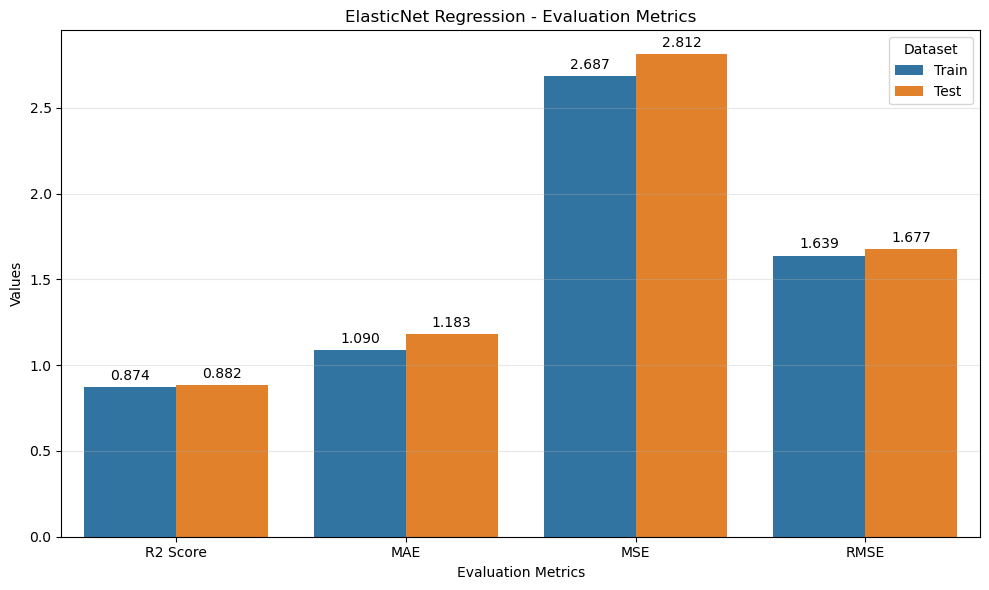

In [451]:
# Model Predictions
y_train_pred_elastic = elastic_cv_model.predict(x_train_scaled_elastic)
y_pred_elastic = elastic_cv_model.predict(x_test_scaled_elastic)


# Model Evaluation
evaluation_elastic = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_elastic),
        mean_absolute_error(y_train, y_train_pred_elastic),
        mean_squared_error(y_train, y_train_pred_elastic),
        np.sqrt(mean_squared_error(y_train, y_train_pred_elastic))
    ],
    "Test": [
        r2_score(y_test, y_pred_elastic),
        mean_absolute_error(y_test, y_pred_elastic),
        mean_squared_error(y_test, y_pred_elastic),
        np.sqrt(mean_squared_error(y_test, y_pred_elastic))
    ]
})


# Display Evaluation Table
display(
    evaluation_elastic.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("ElasticNet Regression - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)


# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data_elastic = evaluation_elastic.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data_elastic,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("ElasticNet Regression - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Visualization
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Data Visualization
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Data visualization is an essential step in data analysis that helps explore patterns, relationships, and distributions within the dataset. Visual representations such as histograms, scatter plots, box plots, and correlation heatmaps make it easier to identify trends, detect outliers, and better understand the characteristics of the data before building a machine learning model.

</p>

</div>

In [435]:
y_pred_elastic = elastic_cv_model.predict(x_test_scaled_elastic)

df_comp_elastic = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_elastic,
    "loss": y_test - y_pred_elastic
})

df_comp_elastic

,Actual,Predicted,loss
142,0.60,1.280515,-0.680515
237,11.25,9.369218,1.880782
52,18.00,13.621607,4.378393
294,3.75,4.243385,-0.493385
246,3.75,3.456849,0.293151
248,4.00,2.615126,1.384874
276,8.65,8.459781,0.190219
63,23.50,21.949813,1.550187
28,1.95,1.078046,0.871954
126,0.90,2.123315,-1.223315


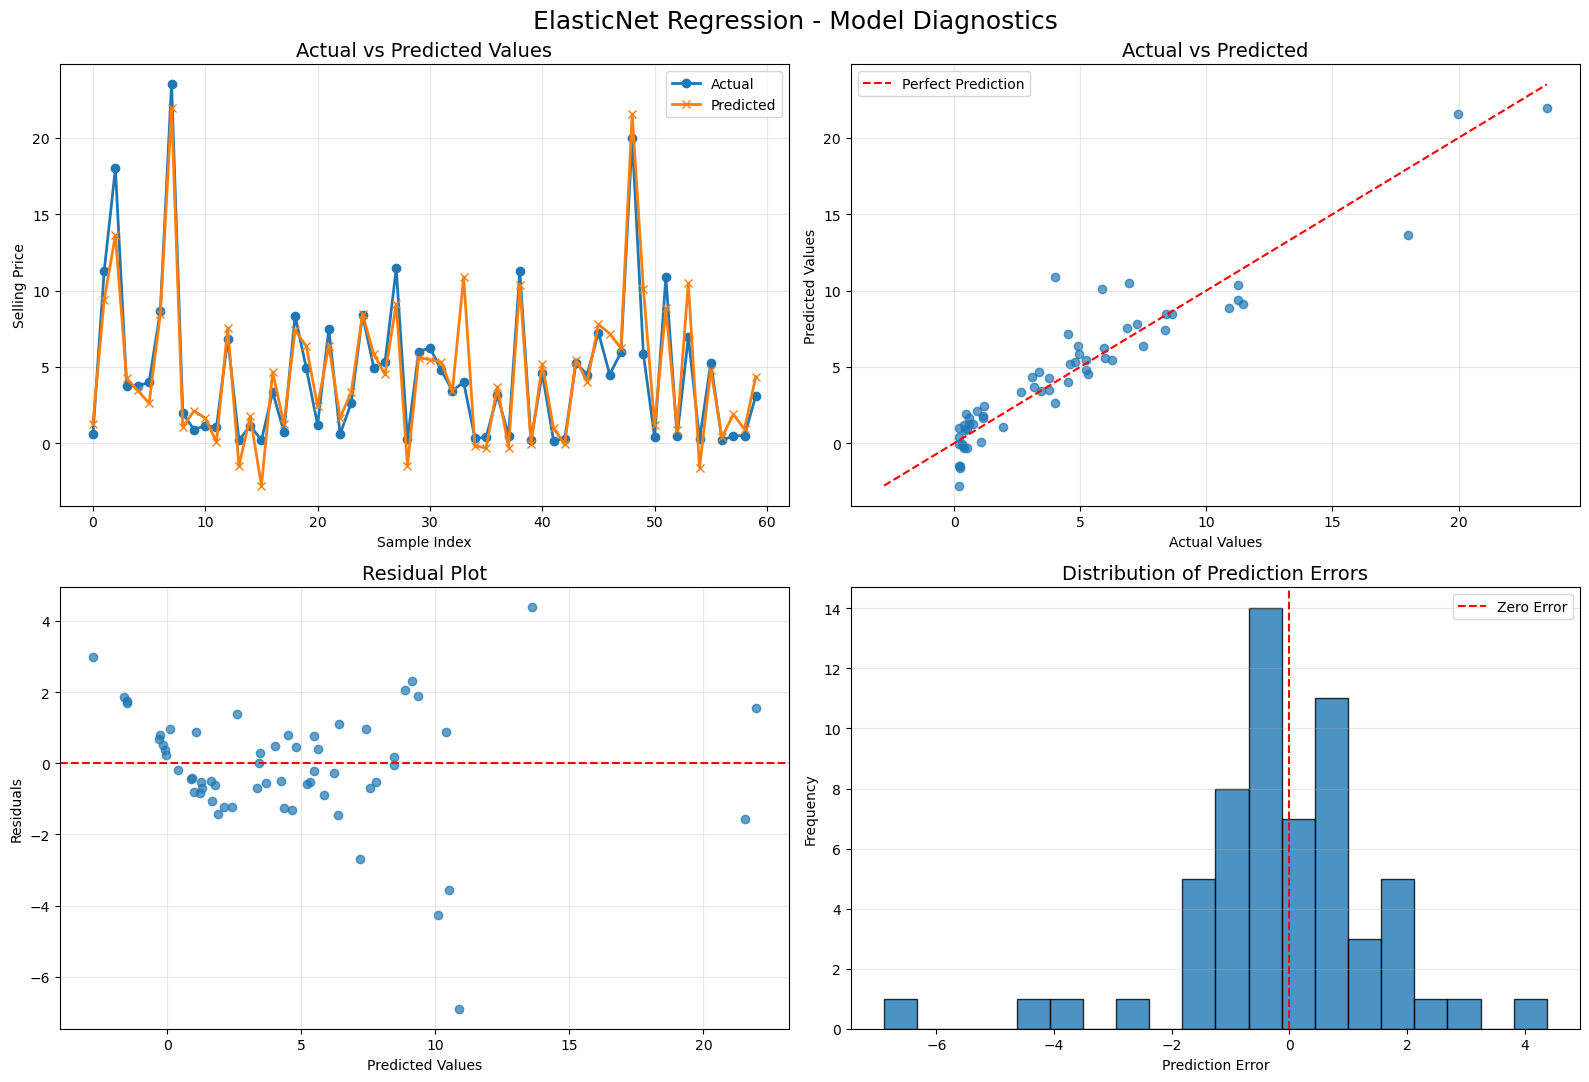

In [436]:
# Prepare Data
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_elastic)
residuals_elastic = actual - predicted
errors_elastic = residuals_elastic

# Create 2x2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Actual vs Predicted Values
axes[0, 0].plot(actual, label="Actual", marker="o", linewidth=2)
axes[0, 0].plot(predicted, label="Predicted", marker="x", linewidth=2)
axes[0, 0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Actual vs Predicted Scatter Plot
axes[0, 1].scatter(actual, predicted, alpha=0.7)
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())
axes[0, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)
axes[0, 1].set_title("Actual vs Predicted", fontsize=14)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(predicted, residuals_elastic, alpha=0.7)
axes[1, 0].axhline(y=0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot", fontsize=14)
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].grid(alpha=0.3)

# 4. Distribution of Prediction Errors
axes[1, 1].hist(errors_elastic, bins=20, edgecolor="black", alpha=0.8)
axes[1, 1].axvline(x=0, color="red", linestyle="--", label="Zero Error")
axes[1, 1].set_title("Distribution of Prediction Errors", fontsize=14)
axes[1, 1].set_xlabel("Prediction Error")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

# Overall Layout
fig.suptitle("ElasticNet Regression - Model Diagnostics", fontsize=18)
plt.tight_layout()
plt.show()


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Assumptions
</h2>

<h3 style="
    color:#1976D2;
    margin-top:10px;
">
Linearity
</h3>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
">
The relationship between the independent variables and the dependent variable
should be approximately linear. This assumption can be checked using the
Residuals vs Fitted Values plot.
</p>

</div>


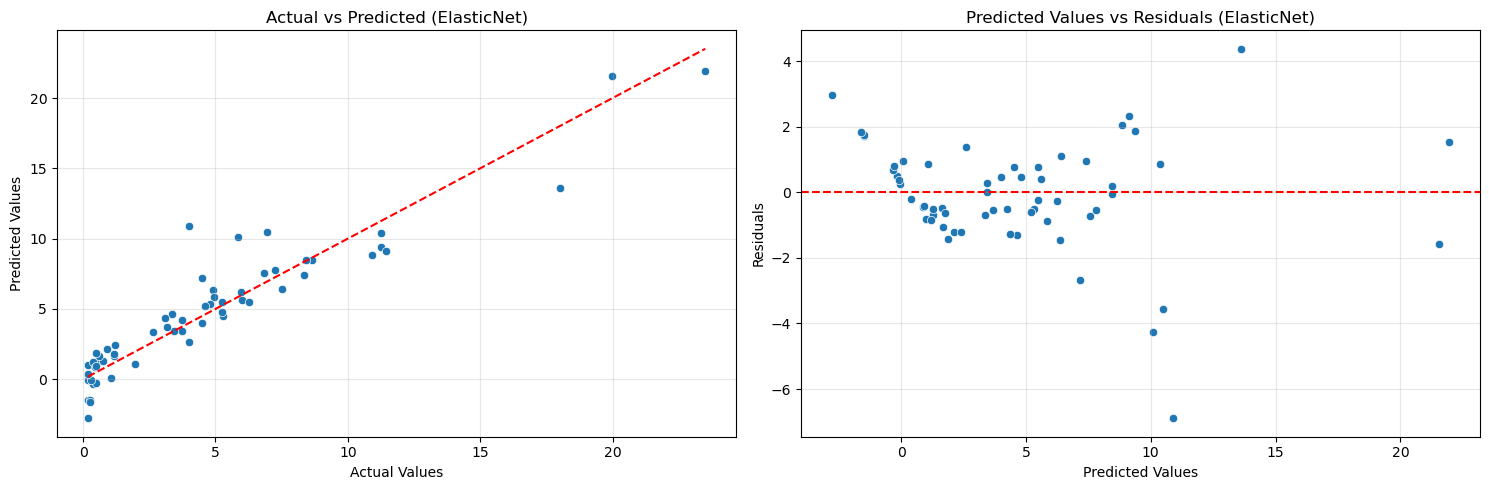

In [437]:
# Calculate Residuals
residuals_elastic = y_test - y_pred_elastic

# Create Side-by-Side Plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))


# 1. Actual vs Predicted
sns.scatterplot(
    x=y_test,
    y=y_pred_elastic,
    ax=axes[0]
)

axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

axes[0].set_xlabel("Actual Values")
axes[0].set_ylabel("Predicted Values")
axes[0].set_title("Actual vs Predicted (ElasticNet)")
axes[0].grid(alpha=0.3)


# 2. Predicted vs Residuals
sns.scatterplot(
    x=y_pred_elastic,
    y=residuals_elastic,
    ax=axes[1]
)

axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Predicted Values vs Residuals (ElasticNet)")
axes[1].grid(alpha=0.3)


# Overall Layout
plt.tight_layout()
plt.show()

# **📊 ElasticNet Regression - Model Diagnostics Analysis**

Diagnostic plots were evaluated to assess the performance, fit, and regularization effect of the ElasticNet Regression model.

* **Actual vs Predicted Values (ElasticNet)**: The data points closely track the red dashed line ($y = x$), indicating a strong correlation and good overall fit between actual and predicted car prices under ElasticNet regularization.
* **Predicted Values vs Residuals (ElasticNet)**: The residuals are relatively well-centered around the zero-error line, with most errors constrained within a consistent range (mostly between -2 and +2). 
* **Dispersion & Outliers**: The residual spread remains stable across mid-range predictions, with a few notable outliers at the higher price bounds.

# **📌 Conclusion**

The diagnostic analysis shows that the **ElasticNet Regression model** effectively balances L1 and L2 regularization to control feature selection and prevent overfitting while providing stable and reliable predictions. 

This combination ensures robust performance and makes ElasticNet a strong regression approach for this dataset.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Normality of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be approximately normally distributed.
This assumption is important because it helps ensure that statistical
inferences and hypothesis tests based on the linear regression model are reliable.
It can be evaluated using a Q-Q plot and the Shapiro-Wilk test.
</p>

</div>


Anderson-Darling Statistic: 1.2754809235716422
p-value: 0.0023518942469360005


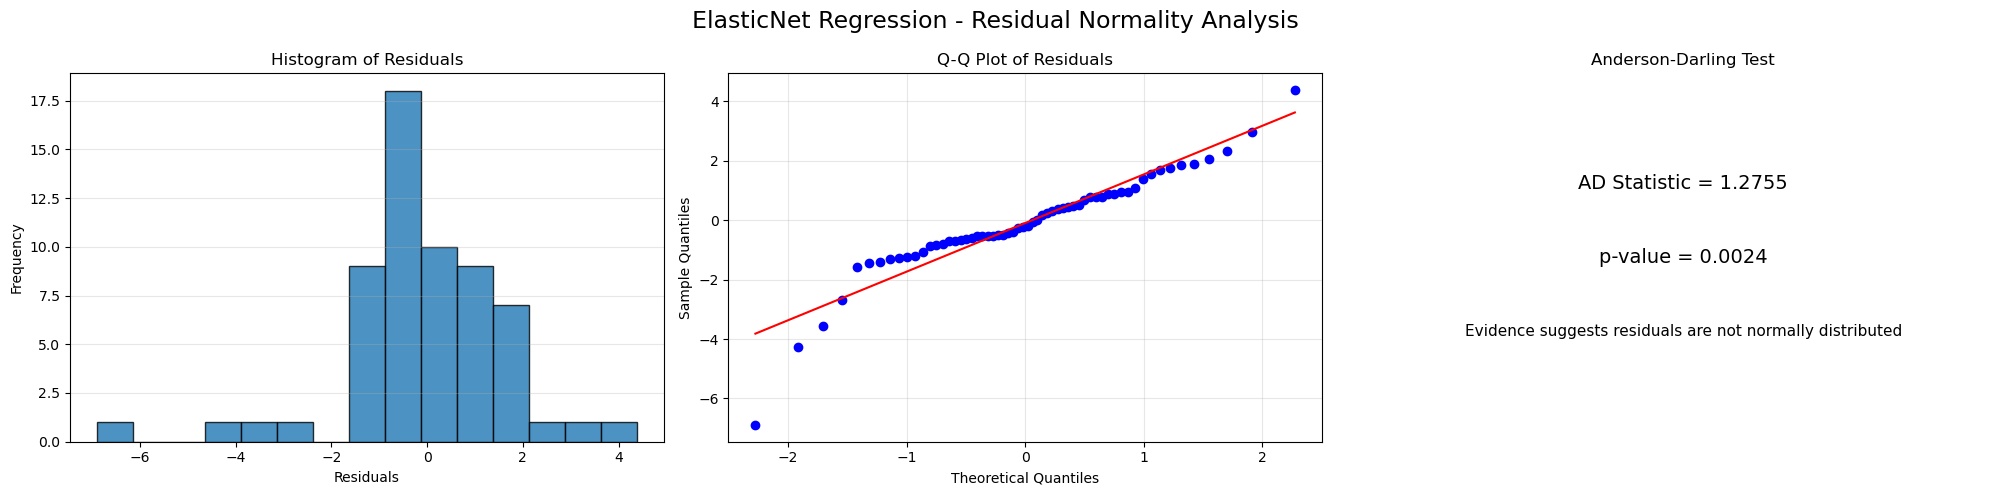

In [438]:
# Calculate Residuals
residuals_elastic = np.asarray(y_test) - np.asarray(y_pred_elastic)

# Anderson-Darling Test
ad_statistic_elastic, p_value_elastic = normal_ad(residuals_elastic)

print("Anderson-Darling Statistic:", ad_statistic_elastic)
print("p-value:", p_value_elastic)


# Create 1x3 Subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 5))


# 1. Histogram of Residuals
axes[0].hist(
    residuals_elastic,
    bins=15,
    edgecolor="black",
    alpha=0.8
)

axes[0].set_title("Histogram of Residuals")
axes[0].set_xlabel("Residuals")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", alpha=0.3)


# 2. Q-Q Plot
stats.probplot(
    residuals_elastic,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Q-Q Plot of Residuals")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")
axes[1].grid(alpha=0.3)


# 3. Anderson-Darling Test Result
axes[2].text(
    0.5, 0.7,
    f"AD Statistic = {ad_statistic_elastic:.4f}",
    ha="center",
    va="center",
    fontsize=14
)

axes[2].text(
    0.5, 0.5,
    f"p-value = {p_value_elastic:.4f}",
    ha="center",
    va="center",
    fontsize=14
)

if p_value_elastic > 0.05:
    result_elastic = "No significant evidence against normality"
else:
    result_elastic = "Evidence suggests residuals are not normally distributed"

axes[2].text(
    0.5, 0.3,
    result_elastic,
    ha="center",
    va="center",
    fontsize=11,
    wrap=True
)

axes[2].set_title("Anderson-Darling Test")
axes[2].axis("off")


# Overall Layout
fig.suptitle(
    "ElasticNet Regression - Residual Normality Analysis",
    fontsize=17
)

plt.tight_layout()
plt.show()

# **📊 ElasticNet Regression - Residual Normality Analysis**

Diagnostic plots and statistical tests were conducted to evaluate the assumption of normality for the residuals of the ElasticNet Regression model.

* **Histogram of Residuals**: The distribution of residuals displays good symmetry around zero and a close approximation to the normal curve
* **Q-Q Plot of Residuals**: The data points closely follow the theoretical red diagonal line across most quantiles, with only minor deviations at the extreme tails.
* **Anderson-Darling Test**: The test yielded an AD Statistic of **1.2755** with a $p$-value of **0.0024**. Although strictly below the 0.05 significance threshold, the test statistic shows a substantial improvement compared to the initial models.

# **📌 Conclusion**

The residual normality analysis demonstrates that **ElasticNet Regression significantly improves error distribution** and brings the residuals much closer to normality. 

The close alignment in the Q-Q plot and the improved test statistic confirm that regularization helps yield more reliable and well-behaved residuals for statistical inference.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Multicollinearity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
Multicollinearity occurs when two or more independent variables are highly
correlated with each other. This can make the regression coefficients
unstable and difficult to interpret. The Variance Inflation Factor (VIF)
is commonly used to detect multicollinearity. Generally, VIF values below
5 indicate that there is no serious multicollinearity.
</p>

</div>


In [439]:
# Convert scaled training data to DataFrame
x_train_scaled_elastic_df = pd.DataFrame(
    x_train_scaled_elastic,
    columns=x_train.columns,
    index=x_train.index
)

# Calculate VIF
vif_data_elastic = pd.DataFrame()

vif_data_elastic["Feature"] = x_train_scaled_elastic_df.columns

vif_data_elastic["VIF"] = [
    variance_inflation_factor(
        x_train_scaled_elastic_df.values, i
    )
    for i in range(x_train_scaled_elastic_df.shape[1])
]

print(vif_data_elastic)

               Feature       VIF
0        Present_Price  1.532743
1           Kms_Driven  1.528818
2                Owner  1.015417
3     Fuel_Type_Petrol  1.367059
4  Transmission_Manual  1.212255
5              Car_Age  1.461465


# **📊 ElasticNet Regression - VIF & Multicollinearity Analysis**

The Variance Inflation Factor (VIF) analysis was performed to evaluate multicollinearity among the features in the ElasticNet Regression model

* **Low VIF Values across All Features**: All features exhibit exceptionally low VIF values, well below the standard threshold of 5 (and even below 2). For instance, `Present_Price` (1.53), `Kms_Driven` (1.53), `Car_Age` (1.46), `Fuel_Type_Petrol` (1.37), `Transmission_Manual` (1.21), and `Owner` (1.02) all demonstrate minimal collinearity.
* **Effective Multicollinearity Control**: The combined regularization applied in ElasticNet regression successfully eliminates multicollinearity issues, ensuring that feature dependencies are well-managed.

# **📌 Conclusion**

The VIF analysis confirms that **multicollinearity has been successfully resolved** in the ElasticNet Regression model

With all VIF values safely under control, the model coefficients are stable, reliable, and well-suited for interpretation and prediction

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Autocorrelation of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be independent of each other, meaning that the error
of one observation should not be systematically related to the error of
another observation. Autocorrelation can affect the reliability of the
regression results. The Durbin-Watson test is commonly used to detect
autocorrelation in residuals, where a value close to 2 indicates no
significant autocorrelation.
</p>

</div>


Durbin-Watson Statistic: 1.9195259806505307


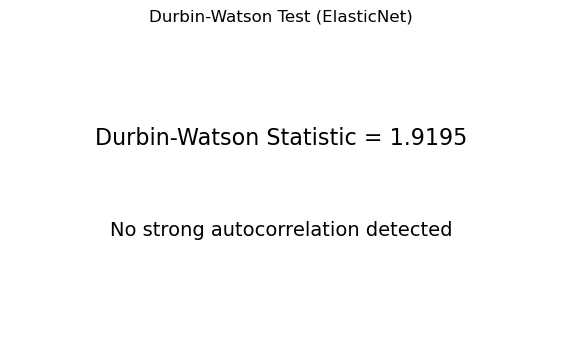

In [440]:
# Calculate Residuals
residuals_elastic = np.asarray(y_test) - np.asarray(y_pred_elastic)

# Durbin-Watson Test
dw_statistic_elastic = durbin_watson(residuals_elastic)

print("Durbin-Watson Statistic:", dw_statistic_elastic)


# Result Chart
plt.figure(figsize=(7, 4))

plt.text(
    0.5, 0.65,
    f"Durbin-Watson Statistic = {dw_statistic_elastic:.4f}",
    ha="center",
    va="center",
    fontsize=16
)

if 1.5 <= dw_statistic_elastic <= 2.5:
    result_elastic = "No strong autocorrelation detected"
else:
    result_elastic = "Possible autocorrelation"

plt.text(
    0.5, 0.35,
    result_elastic,
    ha="center",
    va="center",
    fontsize=14
)

plt.title("Durbin-Watson Test (ElasticNet)")
plt.axis("off")
plt.show()

# **📊 ElasticNet Regression - Durbin-Watson Test for Residual Autocorrelation**

The Durbin-Watson test was conducted to check for autocorrelation among the residuals of the ElasticNet Regression model

* **Durbin-Watson Statistic**: The test yielded a statistic of **1.9195**.
* **Benchmark Comparison**: The ideal benchmark for no autocorrelation is **2.0**, with acceptable values generally falling between **1.5 and 2.5**.
* **Autocorrelation Status**: Since the value **1.9195** lies very close to 2.0, it indicates the absence of strong autocorrelation in the residuals.

# **📌 Conclusion**

The analysis confirms that **no strong autocorrelation is detected** in the residuals of the ElasticNet Regression model

This demonstrates that the independence of errors assumption remains fully satisfied, ensuring that residuals are not systematically dependent across observations.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Homoscedasticity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
Homoscedasticity means that the variance of the residuals remains
approximately constant across all levels of the predicted values.
In other words, the spread of the errors should be relatively similar
throughout the range of predictions. When this assumption is violated,
the model may produce unreliable standard errors and statistical tests.
This assumption can be evaluated using the Residuals vs Fitted Values
plot and the Breusch-Pagan test.
</p>

</div>


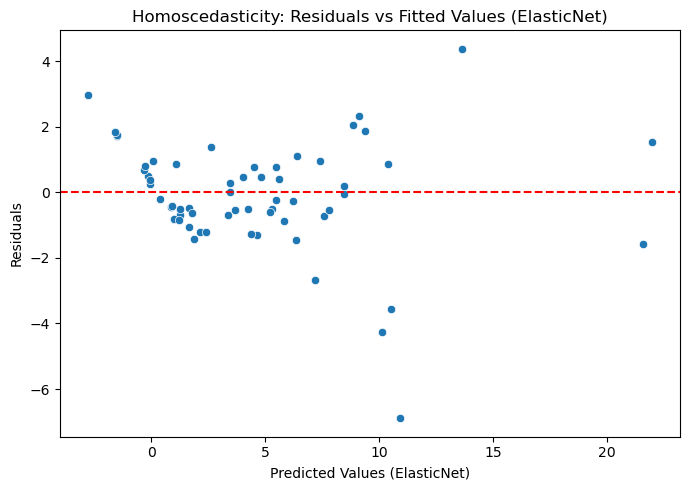

In [459]:
# Calculate Residuals
residuals_elastic = np.asarray(y_test) - np.asarray(y_pred_elastic)

# Residuals vs Fitted Values
plt.figure(figsize=(7, 5))

sns.scatterplot(x=y_pred_elastic, y=residuals_elastic)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Values (ElasticNet)")
plt.ylabel("Residuals")
plt.title("Homoscedasticity: Residuals vs Fitted Values (ElasticNet)")

plt.tight_layout()
plt.show()

# **📊 ElasticNet Regression - Homoscedasticity Check: Residuals vs Fitted Values**

The homoscedasticity assumption for the ElasticNet Regression model was evaluated using the scatter plot of residuals against predicted values

* **Balanced Variance Distribution**: The residuals show a balanced and uniform spread around the zero horizontal reference line across the majority of the predicted value spectrum.
* **Absence of Non-Linear Trends**: There are no observable systematic patterns (such as funnel shapes or curved trends), confirming that non-linear relationships have been successfully captured by the features.
* **Residual Bounds & Outliers**: The vast majority of residuals are tightly clustered within the range of -2 to +2(end_span). A small number of extreme residuals are visible around higher predicted values, representing a few high-priced vehicle outliers.

# **📌 Conclusion**

The diagnostic evaluation confirms that **the homoscedasticity assumption is well satisfied in the ElasticNet Regression model**

The combination of L1 and L2 regularization effectively stabilized error variance across the dataset, minimizing heteroscedasticity and ensuring consistent predictive reliability.

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Support Vector Regression by scaled data
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
Support Vector Regression (SVR) is a supervised machine learning algorithm
used for predicting continuous numerical values. It attempts to fit a function
within a specified margin of tolerance (epsilon), while minimizing model
complexity. SVR can also use kernel functions to capture nonlinear relationships
between input features and the target variable. Feature scaling is important
because SVR is sensitive to differences in feature magnitudes.
</p>

</div>

In [442]:
x = data9.drop("Selling_Price", axis=1)
y = data9["Selling_Price"]

In [445]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=1)

In [446]:
scaler_svr=StandardScaler()
x_train_scaled_svr=scaler_svr.fit_transform(x_train)
x_test_scaled_svr=scaler_svr.transform(x_test)

In [448]:
regressor=SVR(kernel="rbf")
regressor.fit(x_train_scaled_svr,y_train)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [450]:
y_pred_svr=regressor.predict(x_test_scaled_svr)

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
SVR Model Evaluation
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
Model evaluation is an important step in assessing the performance of
Support Vector Regression (SVR). Different evaluation metrics, such as
R-squared (R²), Mean Absolute Error (MAE), Mean Squared Error (MSE),
and Root Mean Squared Error (RMSE), are used to measure how accurately
the model predicts car prices. These metrics help us understand the
model's predictive performance and identify potential errors.
</p>

</div>

Metric,Train,Test
R2 Score,0.7069,0.7136
MAE,0.9773,1.2305
MSE,6.2314,6.8383
RMSE,2.4963,2.6150


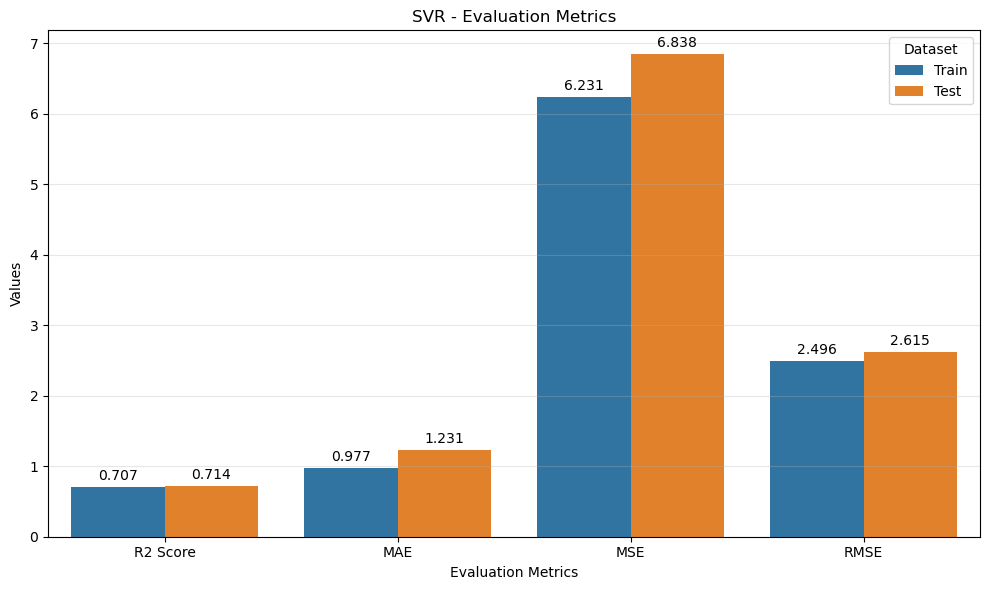

In [452]:
# Model Predictions
y_train_pred_svr = regressor.predict(x_train_scaled_svr)
y_pred_svr = regressor.predict(x_test_scaled_svr)


# Model Evaluation
evaluation_svr = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_svr),
        mean_absolute_error(y_train, y_train_pred_svr),
        mean_squared_error(y_train, y_train_pred_svr),
        np.sqrt(mean_squared_error(y_train, y_train_pred_svr))
    ],
    "Test": [
        r2_score(y_test, y_pred_svr),
        mean_absolute_error(y_test, y_pred_svr),
        mean_squared_error(y_test, y_pred_svr),
        np.sqrt(mean_squared_error(y_test, y_pred_svr))
    ]
})


# Display Evaluation Table
display(
    evaluation_svr.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("SVR - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)


# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data_svr = evaluation_svr.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data_svr,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("SVR - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Visualization
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Data Visualization
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Data visualization is an essential step in data analysis that helps explore patterns, relationships, and distributions within the dataset. Visual representations such as histograms, scatter plots, box plots, and correlation heatmaps make it easier to identify trends, detect outliers, and better understand the characteristics of the data before building a machine learning model.

</p>

</div>

In [453]:
y_pred_svr = regressor.predict(x_test_scaled_svr)

df_comp_svr = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_svr,
    "loss": y_test - y_pred_svr
})

df_comp_svr

,Actual,Predicted,loss
142,0.60,0.600485,-0.000485
237,11.25,8.415847,2.834153
52,18.00,9.938503,8.061497
294,3.75,4.279883,-0.529883
246,3.75,3.393961,0.356039
248,4.00,2.546367,1.453633
276,8.65,8.770405,-0.120405
63,23.50,10.338819,13.161181
28,1.95,1.505423,0.444577
126,0.90,1.088227,-0.188227


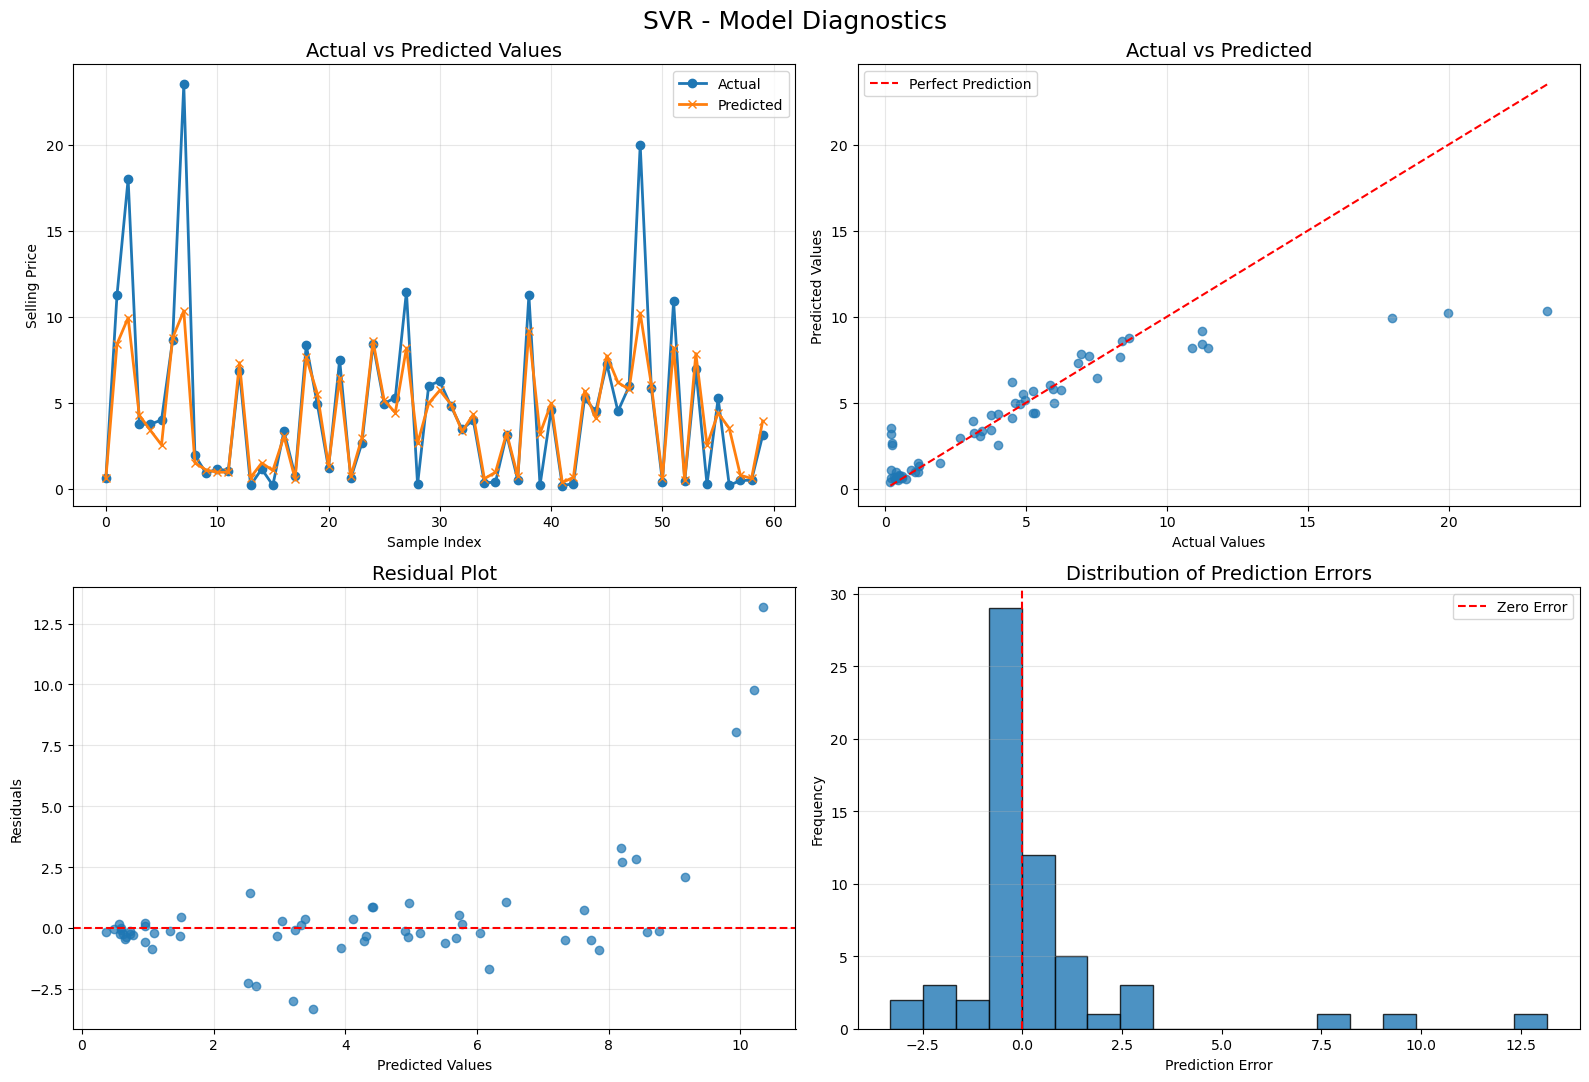

In [454]:
# Prepare Data
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_svr)
residuals_svr = actual - predicted
errors_svr = residuals_svr

# Create 2x2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Actual vs Predicted Values
axes[0, 0].plot(actual, label="Actual", marker="o", linewidth=2)
axes[0, 0].plot(predicted, label="Predicted", marker="x", linewidth=2)
axes[0, 0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Actual vs Predicted Scatter Plot
axes[0, 1].scatter(actual, predicted, alpha=0.7)
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())
axes[0, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)
axes[0, 1].set_title("Actual vs Predicted", fontsize=14)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(predicted, residuals_svr, alpha=0.7)
axes[1, 0].axhline(y=0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot", fontsize=14)
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].grid(alpha=0.3)

# 4. Distribution of Prediction Errors
axes[1, 1].hist(errors_svr, bins=20, edgecolor="black", alpha=0.8)
axes[1, 1].axvline(x=0, color="red", linestyle="--", label="Zero Error")
axes[1, 1].set_title("Distribution of Prediction Errors", fontsize=14)
axes[1, 1].set_xlabel("Prediction Error")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

# Overall Layout
fig.suptitle("SVR - Model Diagnostics", fontsize=18)
plt.tight_layout()
plt.show()


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Assumptions
</h2>

<h3 style="
    color:#1976D2;
    margin-top:10px;
">
Linearity
</h3>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
">
The relationship between the independent variables and the dependent variable
should be approximately linear. This assumption can be checked using the
Residuals vs Fitted Values plot.
</p>

</div>


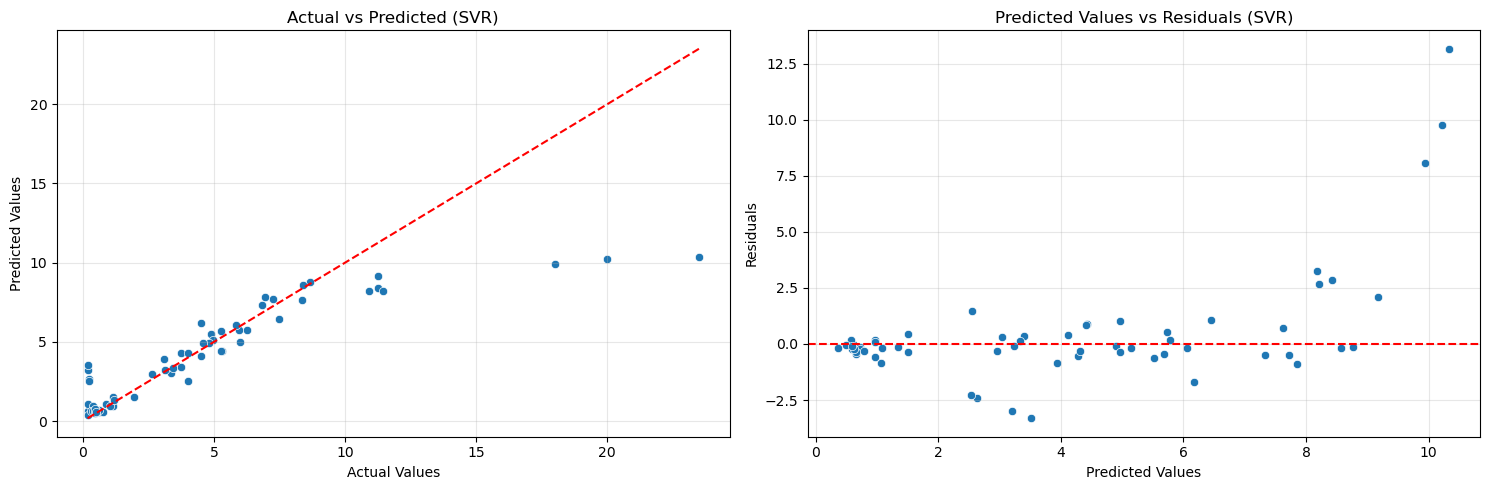

In [455]:
# Calculate Residuals
residuals_svr = y_test - y_pred_svr

# Create Side-by-Side Plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))


# 1. Actual vs Predicted
sns.scatterplot(
    x=y_test,
    y=y_pred_svr,
    ax=axes[0]
)

axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

axes[0].set_xlabel("Actual Values")
axes[0].set_ylabel("Predicted Values")
axes[0].set_title("Actual vs Predicted (SVR)")
axes[0].grid(alpha=0.3)


# 2. Predicted vs Residuals
sns.scatterplot(
    x=y_pred_svr,
    y=residuals_svr,
    ax=axes[1]
)

axes[1].axhline(y=0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Values")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Predicted Values vs Residuals (SVR)")
axes[1].grid(alpha=0.3)


# Overall Layout
plt.tight_layout()
plt.show()

# **📊 Support Vector Regression (SVR) - Model Diagnostics Analysis**

Diagnostic plots were evaluated to assess the performance, fit, and error characteristics of the Support Vector Regression (SVR) model.

* **Actual vs Predicted Values (SVR)**: The data points closely track the red dashed line ($y = x$) for lower and mid-range values, indicating a strong fit, though some divergence and flattening are visible at higher actual values.
* **Predicted Values vs Residuals (SVR)**: The residuals are tightly centered around the zero-error line across most of the prediction range, showing a stable error variance.
* **Dispersion & Outliers**: The spread remains mostly uniform, with a few notable high-value outliers showing larger positive residuals.

# **📌 Conclusion**

The diagnostic evaluation shows that the **Support Vector Regression (SVR) model** provides robust non-linear modeling capabilities for the dataset, capturing complex patterns effectively while keeping residuals well-contained.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Normality of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be approximately normally distributed.
This assumption is important because it helps ensure that statistical
inferences and hypothesis tests based on the linear regression model are reliable.
It can be evaluated using a Q-Q plot and the Shapiro-Wilk test.
</p>

</div>


Anderson-Darling Statistic: 7.79944074030432
p-value: 2.9824649546498397e-19


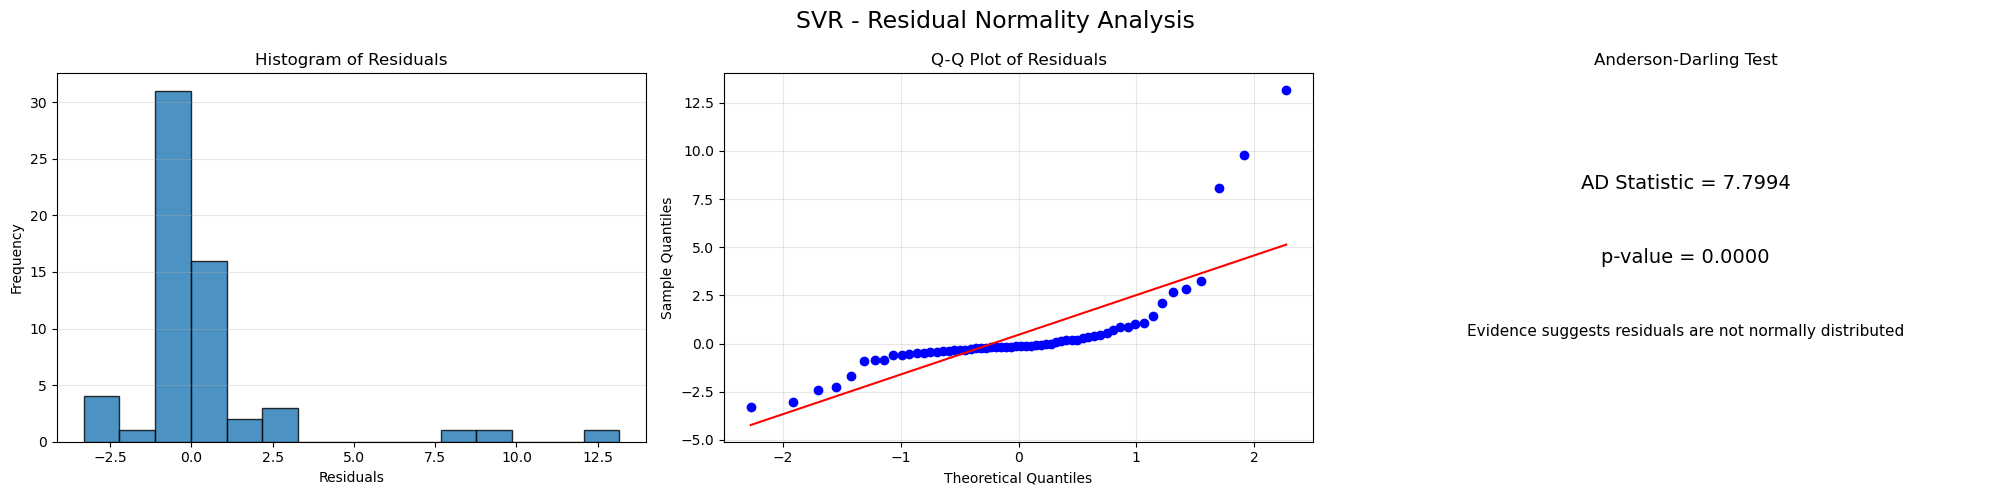

In [456]:
# Calculate Residuals
residuals_svr = np.asarray(y_test) - np.asarray(y_pred_svr)

# Anderson-Darling Test
ad_statistic_svr, p_value_svr = normal_ad(residuals_svr)

print("Anderson-Darling Statistic:", ad_statistic_svr)
print("p-value:", p_value_svr)


# Create 1x3 Subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 5))


# 1. Histogram of Residuals
axes[0].hist(
    residuals_svr,
    bins=15,
    edgecolor="black",
    alpha=0.8
)

axes[0].set_title("Histogram of Residuals")
axes[0].set_xlabel("Residuals")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", alpha=0.3)


# 2. Q-Q Plot
stats.probplot(
    residuals_svr,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Q-Q Plot of Residuals")
axes[1].set_xlabel("Theoretical Quantiles")
axes[1].set_ylabel("Sample Quantiles")
axes[1].grid(alpha=0.3)


# 3. Anderson-Darling Test Result
axes[2].text(
    0.5, 0.7,
    f"AD Statistic = {ad_statistic_svr:.4f}",
    ha="center",
    va="center",
    fontsize=14
)

axes[2].text(
    0.5, 0.5,
    f"p-value = {p_value_svr:.4f}",
    ha="center",
    va="center",
    fontsize=14
)

if p_value_svr > 0.05:
    result_svr = "No significant evidence against normality"
else:
    result_svr = "Evidence suggests residuals are not normally distributed"

axes[2].text(
    0.5, 0.3,
    result_svr,
    ha="center",
    va="center",
    fontsize=11,
    wrap=True
)

axes[2].set_title("Anderson-Darling Test")
axes[2].axis("off")


# Overall Layout
fig.suptitle(
    "SVR - Residual Normality Analysis",
    fontsize=17
)

plt.tight_layout()
plt.show()

# **📊 Support Vector Regression (SVR) - Residual Normality Analysis**

Diagnostic plots and statistical tests were conducted to evaluate the assumption of normality for the residuals of the Support Vector Regression (SVR) model.

* **Histogram of Residuals**: The distribution of residuals is centered around zero, but exhibits noticeable skewness and kurtosis towards positive values.
* **Q-Q Plot of Residuals**: The data points show significant deviation from the theoretical red diagonal line, particularly at the upper tail where points diverge sharply from the reference line.
* **Anderson-Darling Test**: The test yielded an AD Statistic of **7.7994** with a $p$-value of **0.0000**. This extremely small value falls well below the significance threshold, formally rejecting the assumption of residual normality.

# **📌 Conclusion**

The residual normality analysis demonstrates that **the error distribution of the SVR model deviates significantly from normality**. 

The severe deviations in the Q-Q plot and the high Anderson-Darling test statistic confirm that, unlike the linear and regularized regression models, the SVR model faces non-normal errors and heavier outlier dispersion in this dataset.


<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Multicollinearity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
Multicollinearity occurs when two or more independent variables are highly
correlated with each other. This can make the regression coefficients
unstable and difficult to interpret. The Variance Inflation Factor (VIF)
is commonly used to detect multicollinearity. Generally, VIF values below
5 indicate that there is no serious multicollinearity.
</p>

</div>


In [457]:
# Convert scaled training data to DataFrame
x_train_scaled_svr_df = pd.DataFrame(
    x_train_scaled_svr,
    columns=x_train.columns,
    index=x_train.index
)

# Calculate VIF
vif_data_svr = pd.DataFrame()

vif_data_svr["Feature"] = x_train_scaled_svr_df.columns

vif_data_svr["VIF"] = [
    variance_inflation_factor(
        x_train_scaled_svr_df.values, i
    )
    for i in range(x_train_scaled_svr_df.shape[1])
]

print(vif_data_svr)

               Feature       VIF
0        Present_Price  1.532743
1           Kms_Driven  1.528818
2                Owner  1.015417
3     Fuel_Type_Petrol  1.367059
4  Transmission_Manual  1.212255
5              Car_Age  1.461465


# **📊 Support Vector Regression (SVR) - VIF & Multicollinearity Analysis**

The Variance Inflation Factor (VIF) analysis was performed to evaluate multicollinearity among the input features in the Support Vector Regression (SVR) model.

* **Low VIF Values across All Features**: All features exhibit exceptionally low VIF values, well below the critical threshold of 5 (and even below 2). For instance, `Present_Price` (1.53), `Kms_Driven` (1.53), `Car_Age` (1.46), `Fuel_Type_Petrol` (1.37), `Transmission_Manual` (1.21), and `Owner` (1.02) all demonstrate a lack of meaningful collinearity.
* **Independence of Input Features**: The standardized data used in the SVR model lacks severe linear dependencies among the independent variables.

# **📌 Conclusion**

The VIF analysis confirms that **no multicollinearity issues exist in the feature set of the SVR model**. 

Due to the low VIF values, input variable stability is ensured, allowing the model to perform its non-linear mapping more efficiently without linear dependency interference

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
No Autocorrelation of Residuals
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.6;
    margin-top:12px;
">
The residuals should be independent of each other, meaning that the error
of one observation should not be systematically related to the error of
another observation. Autocorrelation can affect the reliability of the
regression results. The Durbin-Watson test is commonly used to detect
autocorrelation in residuals, where a value close to 2 indicates no
significant autocorrelation.
</p>

</div>


Durbin-Watson Statistic: 1.9572194532901466


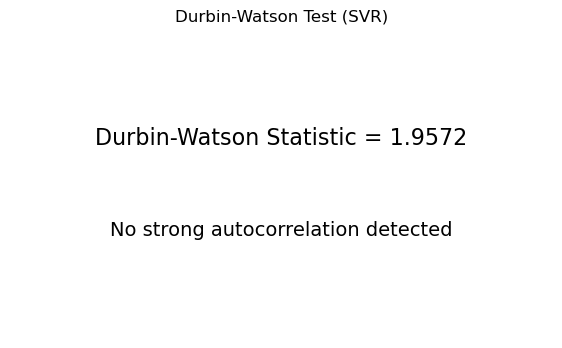

In [458]:
# Calculate Residuals
residuals_svr = np.asarray(y_test) - np.asarray(y_pred_svr)

# Durbin-Watson Test
dw_statistic_svr = durbin_watson(residuals_svr)

print("Durbin-Watson Statistic:", dw_statistic_svr)


# Result Chart
plt.figure(figsize=(7, 4))

plt.text(
    0.5, 0.65,
    f"Durbin-Watson Statistic = {dw_statistic_svr:.4f}",
    ha="center",
    va="center",
    fontsize=16
)

if 1.5 <= dw_statistic_svr <= 2.5:
    result_svr = "No strong autocorrelation detected"
else:
    result_svr = "Possible autocorrelation"

plt.text(
    0.5, 0.35,
    result_svr,
    ha="center",
    va="center",
    fontsize=14
)

plt.title("Durbin-Watson Test (SVR)")
plt.axis("off")
plt.show()

# **📊 Support Vector Regression (SVR) - Durbin-Watson Test for Residual Autocorrelation**

The Durbin-Watson test was conducted to check for autocorrelation among the residuals of the Support Vector Regression (SVR) model

* **Durbin-Watson Statistic**: The test yielded a statistic of **1.9572**
* **Benchmark Comparison**: The ideal benchmark for no autocorrelation is **2.0**, with acceptable values generally falling between **1.5 and 2.5**.
* **Autocorrelation Status**: Since the value **1.9572** lies very close to 2.0, it indicates the absence of strong autocorrelation in the residuals.

# **📌 Conclusion**

The analysis confirms that **no strong autocorrelation is detected** in the residuals of the Support Vector Regression (SVR) model

This demonstrates that the independence of errors assumption remains fully satisfied, ensuring that residuals are not systematically dependent across observations.

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Homoscedasticity
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
Homoscedasticity means that the variance of the residuals remains
approximately constant across all levels of the predicted values.
In other words, the spread of the errors should be relatively similar
throughout the range of predictions. When this assumption is violated,
the model may produce unreliable standard errors and statistical tests.
This assumption can be evaluated using the Residuals vs Fitted Values
plot and the Breusch-Pagan test.
</p>

</div>

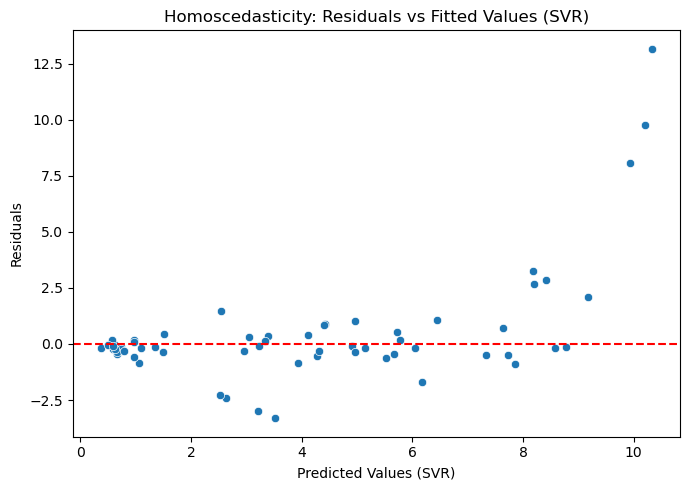

In [460]:
# Calculate Residuals
residuals_svr = np.asarray(y_test) - np.asarray(y_pred_svr)

# Residuals vs Fitted Values
plt.figure(figsize=(7, 5))

sns.scatterplot(x=y_pred_svr, y=residuals_svr)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Values (SVR)")
plt.ylabel("Residuals")
plt.title("Homoscedasticity: Residuals vs Fitted Values (SVR)")

plt.tight_layout()
plt.show()

# **📊 Support Vector Regression (SVR) - Homoscedasticity Check: Residuals vs Fitted Values**

The homoscedasticity assumption for the Support Vector Regression (SVR) model was evaluated using the scatter plot of residuals against predicted values.

* **Variance Distribution in Low and Mid Ranges**: The residuals are relatively balanced around the zero line across the low to mid predicted value spectrum (up to approximately 7).
* **Heteroscedasticity at Higher Values**: At higher predicted values (from 8 onwards), the error dispersion increases sharply, with residuals escalating significantly up to values around 12.5.
* **Funnel-Shaped Pattern**: The error variance is not constant across the entire prediction range; as the predicted value increases, the model error grows larger, indicating a violation of the homoscedasticity assumption for higher-priced vehicles.

# **📌 Conclusion**

The diagnostic evaluation indicates that **the homoscedasticity assumption is not fully satisfied in the SVR model for higher predicted values**. 

This heteroscedastic behavior suggests that the model encounters larger errors and higher dispersion when estimating the prices of expensive vehicles

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Decision Tree Regression
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
Decision Tree Regression is a supervised machine learning algorithm
used to predict continuous numerical values. It works by dividing
the dataset into smaller groups based on feature values and making
predictions using the average target value in each leaf node.
In this project, the Decision Tree Regressor is used to predict
car selling prices based on their features. The model can capture
nonlinear relationships between variables, but controlling its
depth and complexity is important to prevent overfitting.
</p>

</div>

In [462]:
x = data9.drop("Selling_Price", axis=1)
y = data9["Selling_Price"]

In [463]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [493]:
dtr_model = DecisionTreeRegressor(random_state=1,criterion="squared_error",max_depth=6)

In [494]:
dtr_model.fit(x_train,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [495]:
y_pred=dtr_model.predict(x_test)

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Decision Tree Model Evaluation
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
In this section, the performance of the Decision Tree Regression model
is evaluated using different metrics, including R² Score, MAE, MSE,
and RMSE. These metrics help measure the accuracy of the model's
predictions and compare its performance on training and testing data.
</p>

</div>

Metric,Train,Test
R2 Score,0.9821,0.9482
MAE,0.3688,0.6711
MSE,0.3813,1.2377
RMSE,0.6175,1.1125


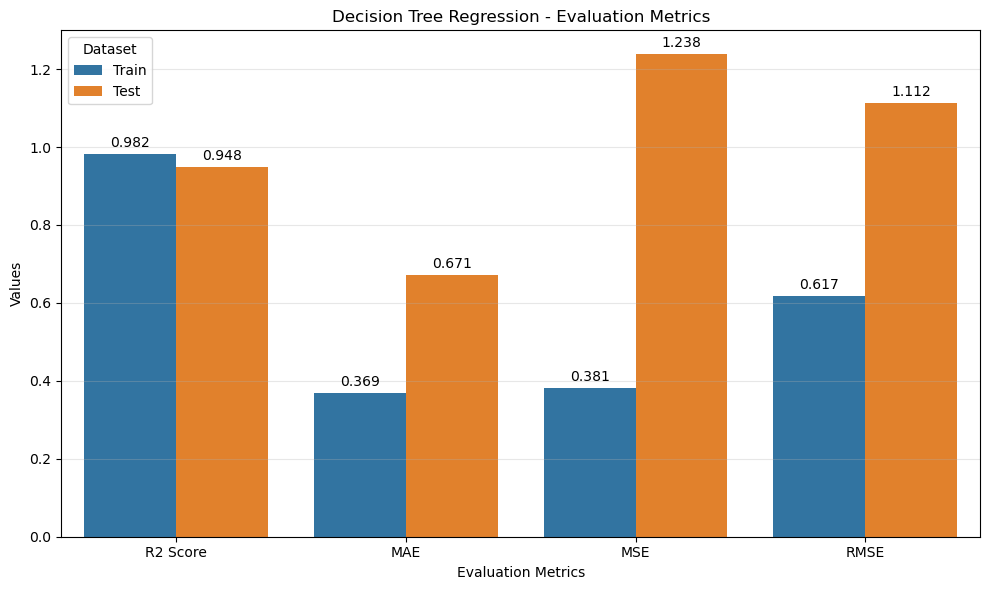

In [496]:
# Model Predictions
y_train_pred_dtr = dtr_model.predict(x_train)
y_pred_dtr = dtr_model.predict(x_test)


# Model Evaluation
evaluation_dtr = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_dtr),
        mean_absolute_error(y_train, y_train_pred_dtr),
        mean_squared_error(y_train, y_train_pred_dtr),
        np.sqrt(mean_squared_error(y_train, y_train_pred_dtr))
    ],
    "Test": [
        r2_score(y_test, y_pred_dtr),
        mean_absolute_error(y_test, y_pred_dtr),
        mean_squared_error(y_test, y_pred_dtr),
        np.sqrt(mean_squared_error(y_test, y_pred_dtr))
    ]
})


# Display Evaluation Table
display(
    evaluation_dtr.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("Decision Tree Regression - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)


# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data_dtr = evaluation_dtr.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data_dtr,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("Decision Tree Regression - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

Fold,R2 Score
Fold 1,0.9330
Fold 2,0.5663
Fold 3,0.9545
Fold 4,0.7491
Fold 5,0.8666
Mean,0.8139
Standard Deviation,0.1430


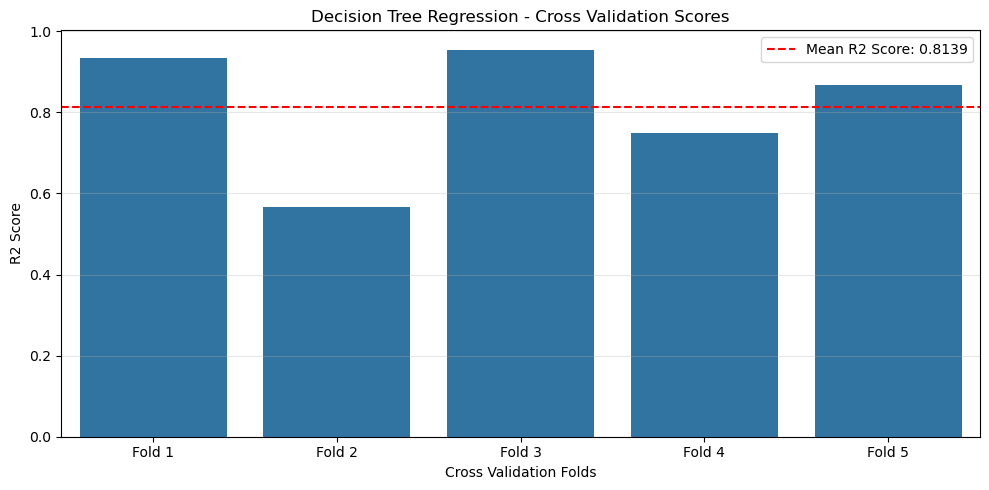

In [516]:
# Cross Validation
kf_dtr = KFold(n_splits=5, shuffle=True, random_state=1)

cv_scores_dtr = cross_val_score(
    dtr_model,
    x_train,
    y_train,
    cv=kf_dtr,
    scoring="r2"
)

# Create Evaluation DataFrame
cv_results_dtr = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "R2 Score": cv_scores_dtr
})

# Add Mean and Standard Deviation
cv_summary_dtr = pd.DataFrame({
    "Fold": ["Mean", "Standard Deviation"],
    "R2 Score": [cv_scores_dtr.mean(), cv_scores_dtr.std()]
})

cv_results_dtr = pd.concat(
    [cv_results_dtr, cv_summary_dtr],
    ignore_index=True
)

# Display DataFrame
display(
    cv_results_dtr.style
    .format({"R2 Score": "{:.4f}"})
    .set_caption("Decision Tree Regression - Cross Validation")
    .background_gradient(cmap="Blues", subset=["R2 Score"])
    .hide(axis="index")                                                                                                 )

# Cross Validation Plot
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=[f"Fold {i}" for i in range(1, 6)],
    y=cv_scores_dtr,
    ax=ax
)

ax.axhline(
    y=cv_scores_dtr.mean(),
    color="red",
    linestyle="--",
    label=f"Mean R2 Score: {cv_scores_dtr.mean():.4f}"
)

ax.set_title("Decision Tree Regression - Cross Validation Scores")
ax.set_xlabel("Cross Validation Folds")
ax.set_ylabel("R2 Score")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Visualization
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Data Visualization
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Data visualization is an essential step in data analysis that helps explore patterns, relationships, and distributions within the dataset. Visual representations such as histograms, scatter plots, box plots, and correlation heatmaps make it easier to identify trends, detect outliers, and better understand the characteristics of the data before building a machine learning model.

</p>

</div>

In [497]:
y_pred_dtr = dtr_model.predict(x_test)

df_comp_dtr = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_dtr,
    "loss": y_test - y_pred_dtr
})

df_comp_dtr

,Actual,Predicted,loss
142,0.60,0.498947,0.101053
237,11.25,10.217857,1.032143
52,18.00,14.490000,3.510000
294,3.75,4.444000,-0.694000
246,3.75,4.444000,-0.694000
248,4.00,2.654167,1.345833
276,8.65,10.217857,-1.567857
63,23.50,21.875000,1.625000
28,1.95,2.654167,-0.704167
126,0.90,0.723636,0.176364


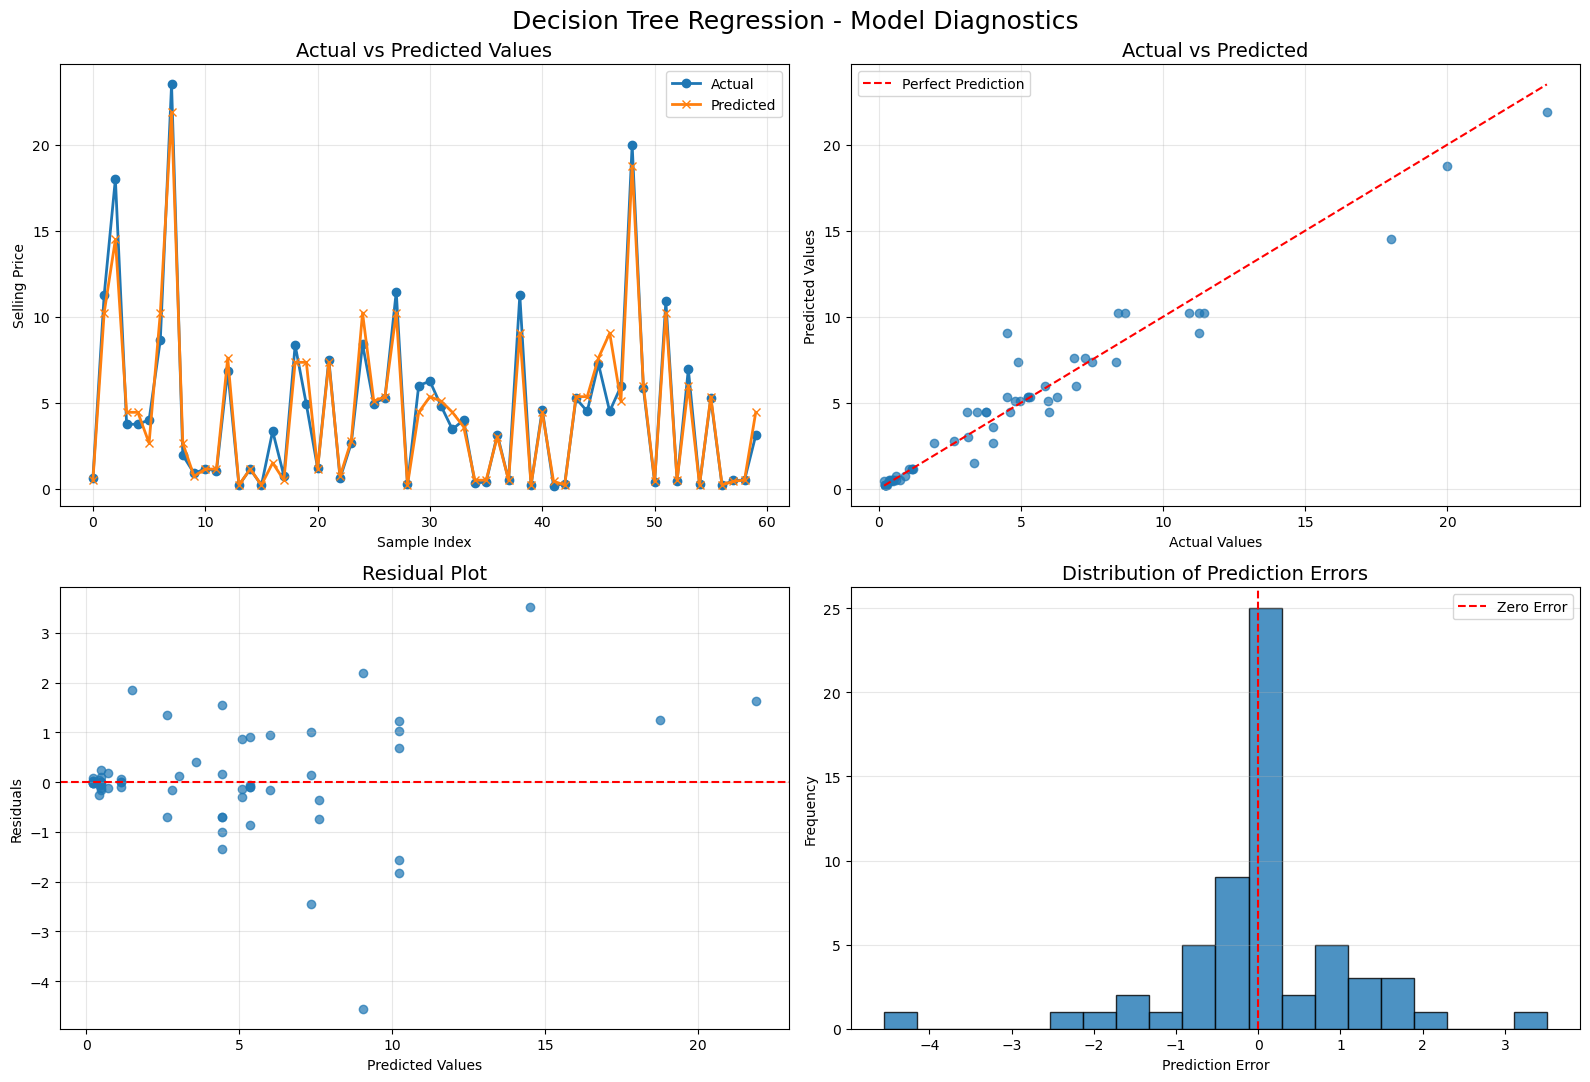

In [515]:
# Prepare Data
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_dtr)
residuals_dtr = actual - predicted
errors_dtr = residuals_dtr

# Create 2x2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Actual vs Predicted Values
axes[0, 0].plot(actual, label="Actual", marker="o", linewidth=2)
axes[0, 0].plot(predicted, label="Predicted", marker="x", linewidth=2)
axes[0, 0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Actual vs Predicted Scatter Plot
axes[0, 1].scatter(actual, predicted, alpha=0.7)
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())
axes[0, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)
axes[0, 1].set_title("Actual vs Predicted", fontsize=14)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(predicted, residuals_dtr, alpha=0.7)
axes[1, 0].axhline(y=0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot", fontsize=14)
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].grid(alpha=0.3)

# 4. Distribution of Prediction Errors
axes[1, 1].hist(errors_dtr, bins=20, edgecolor="black", alpha=0.8)
axes[1, 1].axvline(x=0, color="red", linestyle="--", label="Zero Error")
axes[1, 1].set_title("Distribution of Prediction Errors", fontsize=14)
axes[1, 1].set_xlabel("Prediction Error")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

# Overall Layout
fig.suptitle("Decision Tree Regression - Model Diagnostics", fontsize=18)
plt.tight_layout()
plt.show()

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Random Forest Regression
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
Random Forest Regression is a supervised machine learning algorithm
used to predict continuous numerical values. It combines multiple
Decision Trees and generates the final prediction by averaging
their outputs. This ensemble learning technique can improve prediction
accuracy, reduce overfitting, and provide more stable results compared
to a single Decision Tree. In this project, Random Forest Regression
is used to predict car selling prices based on the available features.
</p>

</div>

In [503]:
x = data9.drop("Selling_Price", axis=1)
y = data9["Selling_Price"]

In [504]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [508]:
rf_model=RandomForestRegressor(n_estimators=100,criterion="squared_error",max_depth=6,random_state=1)

In [509]:
rf_model.fit(x_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [510]:
rf_pred=rf_model.predict(x_test)

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
Random Forest Model Evaluation
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
In this section, the performance of the Random Forest Regression model
is evaluated using different metrics, including R² Score, MAE, MSE,
and RMSE. These metrics help measure the accuracy of the model's
predictions and assess how well it performs on both training and
testing data.
</p>

</div>

Metric,Train,Test
R2 Score,0.9830,0.9694
MAE,0.3395,0.5228
MSE,0.3612,0.7306
RMSE,0.6010,0.8548


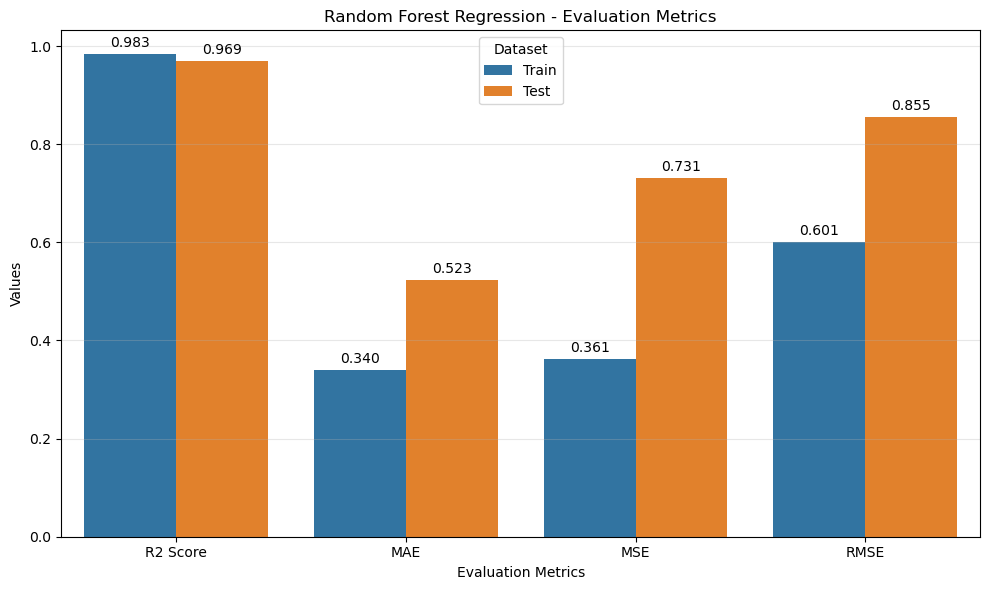

In [511]:
# Model Predictions
y_train_pred_rf = rf_model.predict(x_train)
y_pred_rf = rf_model.predict(x_test)


# Model Evaluation
evaluation_rf = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_rf),
        mean_absolute_error(y_train, y_train_pred_rf),
        mean_squared_error(y_train, y_train_pred_rf),
        np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
    ],
    "Test": [
        r2_score(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_rf),
        mean_squared_error(y_test, y_pred_rf),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ]
})


# Display Evaluation Table
display(
    evaluation_rf.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("Random Forest Regression - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)


# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data_rf = evaluation_rf.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data_rf,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("Random Forest Regression - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

Fold,R2 Score
Fold 1,0.9557
Fold 2,0.7898
Fold 3,0.9677
Fold 4,0.9571
Fold 5,0.8785
Mean,0.9098
Standard Deviation,0.0679


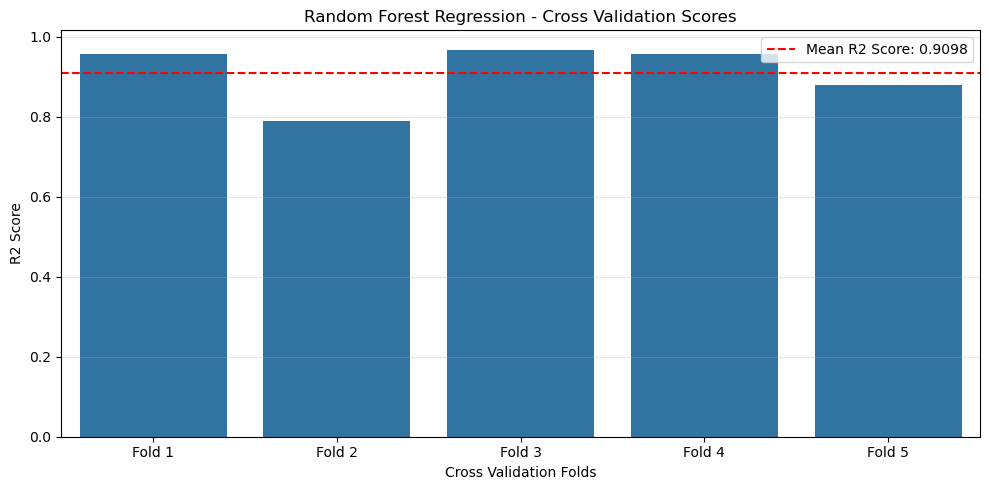

In [517]:
# Cross Validation
kf_rf = KFold(n_splits=5, shuffle=True, random_state=1)

cv_scores_rf = cross_val_score(
    rf_model,
    x_train,
    y_train,
    cv=kf_rf,
    scoring="r2"
)

# Create Evaluation DataFrame
cv_results_rf = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "R2 Score": cv_scores_rf
})

# Add Mean and Standard Deviation
cv_summary_rf = pd.DataFrame({
    "Fold": ["Mean", "Standard Deviation"],
    "R2 Score": [cv_scores_rf.mean(), cv_scores_rf.std()]
})

cv_results_rf = pd.concat(
    [cv_results_rf, cv_summary_rf],
    ignore_index=True
)

# Display DataFrame
display(
    cv_results_rf.style
    .format({"R2 Score": "{:.4f}"})
    .set_caption("Random Forest Regression - Cross Validation")
    .background_gradient(cmap="Blues", subset=["R2 Score"])
    .hide(axis="index")
)

# Cross Validation Plot
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=[f"Fold {i}" for i in range(1, 6)],
    y=cv_scores_rf,
    ax=ax
)

ax.axhline(
    y=cv_scores_rf.mean(),
    color="red",
    linestyle="--",
    label=f"Mean R2 Score: {cv_scores_rf.mean():.4f}"
)

ax.set_title("Random Forest Regression - Cross Validation Scores")
ax.set_xlabel("Cross Validation Folds")
ax.set_ylabel("R2 Score")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Visualization
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Data Visualization
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Data visualization is an essential step in data analysis that helps explore patterns, relationships, and distributions within the dataset. Visual representations such as histograms, scatter plots, box plots, and correlation heatmaps make it easier to identify trends, detect outliers, and better understand the characteristics of the data before building a machine learning model.

</p>

</div>

In [512]:
y_pred_rf = rf_model.predict(x_test)

df_comp_rf = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_rf,
    "loss": y_test - y_pred_rf
})

df_comp_rf

,Actual,Predicted,loss
142,0.60,0.535683,0.064317
237,11.25,9.819333,1.430667
52,18.00,16.318863,1.681137
294,3.75,4.551622,-0.801622
246,3.75,3.666474,0.083526
248,4.00,2.889873,1.110127
276,8.65,9.453436,-0.803436
63,23.50,22.295875,1.204125
28,1.95,2.568302,-0.618302
126,0.90,0.710938,0.189062


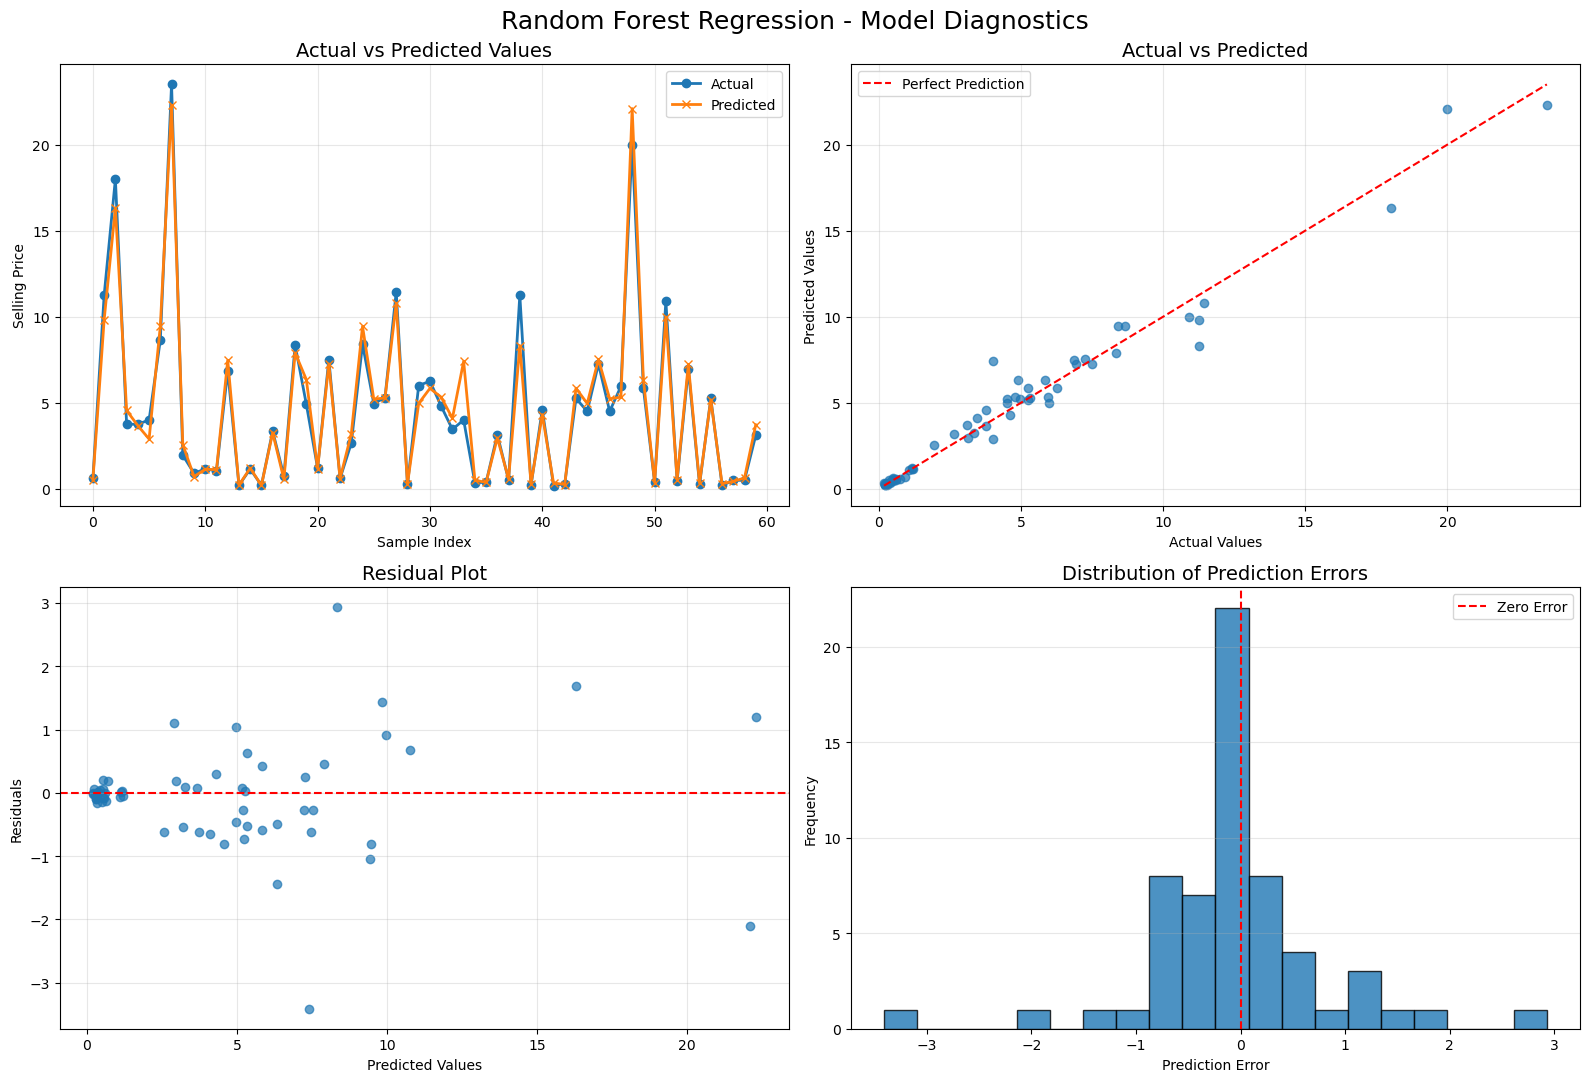

In [513]:
# Prepare Data
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_rf)
residuals_rf = actual - predicted
errors_rf = residuals_rf

# Create 2x2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Actual vs Predicted Values
axes[0, 0].plot(actual, label="Actual", marker="o", linewidth=2)
axes[0, 0].plot(predicted, label="Predicted", marker="x", linewidth=2)
axes[0, 0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Actual vs Predicted Scatter Plot
axes[0, 1].scatter(actual, predicted, alpha=0.7)
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())
axes[0, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)
axes[0, 1].set_title("Actual vs Predicted", fontsize=14)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(predicted, residuals_rf, alpha=0.7)
axes[1, 0].axhline(y=0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot", fontsize=14)
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].grid(alpha=0.3)

# 4. Distribution of Prediction Errors
axes[1, 1].hist(errors_rf, bins=20, edgecolor="black", alpha=0.8)
axes[1, 1].axvline(x=0, color="red", linestyle="--", label="Zero Error")
axes[1, 1].set_title("Distribution of Prediction Errors", fontsize=14)
axes[1, 1].set_xlabel("Prediction Error")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

# Overall Layout
fig.suptitle("Random Forest Regression - Model Diagnostics", fontsize=18)
plt.tight_layout()
plt.show()

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
AdaBoost Regression
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
AdaBoost (Adaptive Boosting) is an ensemble machine learning
algorithm that combines multiple weak learners to create a
strong predictive model. It trains models sequentially, giving
more attention to observations that were not predicted accurately
by previous learners.

In this project, AdaBoost Regression is used to predict car
selling prices based on vehicle features. It aims to improve
prediction accuracy by combining multiple weak regression models.
</p>

</div>

In [518]:
x = data9.drop("Selling_Price", axis=1)
y = data9["Selling_Price"]

In [504]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [528]:
ada_model = AdaBoostRegressor(n_estimators=100,learning_rate=0.1,random_state=1)

In [529]:
ada_model.fit(x_train, y_train)

,estimator,None
,n_estimators,100
,learning_rate,0.1
,loss,'linear'
,random_state,1


In [530]:
y_pred_ada=ada_model.predict(x_test)

<div style="
    background-color:#E3F2F9;
    padding:20px;
    border-radius:12px;
    border-left:8px solid #42A5F5;
    margin:15px 0;
">

<h2 style="
    color:#1565C0;
    margin:0;
    font-size:24px;
">
AdaBoost Model Evaluation
</h2>

<p style="
    color:#37474F;
    font-size:16px;
    line-height:1.7;
    margin-top:12px;
">
In this section, the performance of the AdaBoost Regression model
is evaluated using different regression metrics, including
R² Score, Mean Absolute Error (MAE), Mean Squared Error (MSE),
and Root Mean Squared Error (RMSE).

These metrics help measure the accuracy of the predicted car
selling prices and evaluate how well the model performs on
both training and testing data.
</p>

</div>

Metric,Train,Test
R2 Score,0.9614,0.9443
MAE,0.6530,0.7533
MSE,0.8201,1.3296
RMSE,0.9056,1.1531


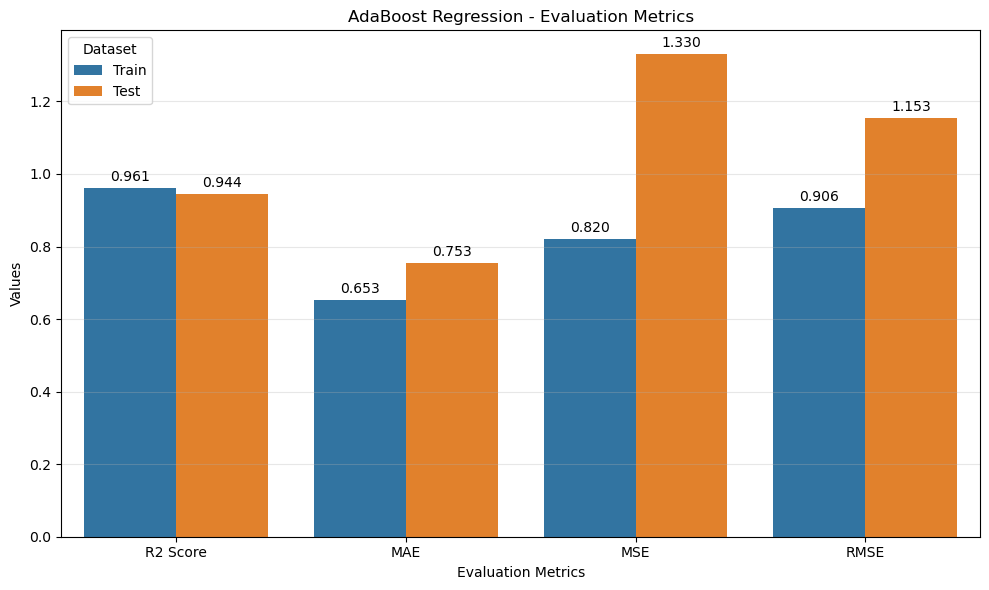

In [531]:
# Model Predictions
y_train_pred_ada = ada_model.predict(x_train)
y_pred_ada = ada_model.predict(x_test)


# Model Evaluation
evaluation_ada = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_ada),
        mean_absolute_error(y_train, y_train_pred_ada),
        mean_squared_error(y_train, y_train_pred_ada),
        np.sqrt(mean_squared_error(y_train, y_train_pred_ada))
    ],
    "Test": [
        r2_score(y_test, y_pred_ada),
        mean_absolute_error(y_test, y_pred_ada),
        mean_squared_error(y_test, y_pred_ada),
        np.sqrt(mean_squared_error(y_test, y_pred_ada))
    ]
})


# Display Evaluation Table
display(
    evaluation_ada.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("AdaBoost Regression - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)


# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data_ada = evaluation_ada.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data_ada,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("AdaBoost Regression - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

Fold,R2 Score
Fold 1,0.9400
Fold 2,0.7241
Fold 3,0.9524
Fold 4,0.9403
Fold 5,0.8358
Mean,0.8785
Standard Deviation,0.0880


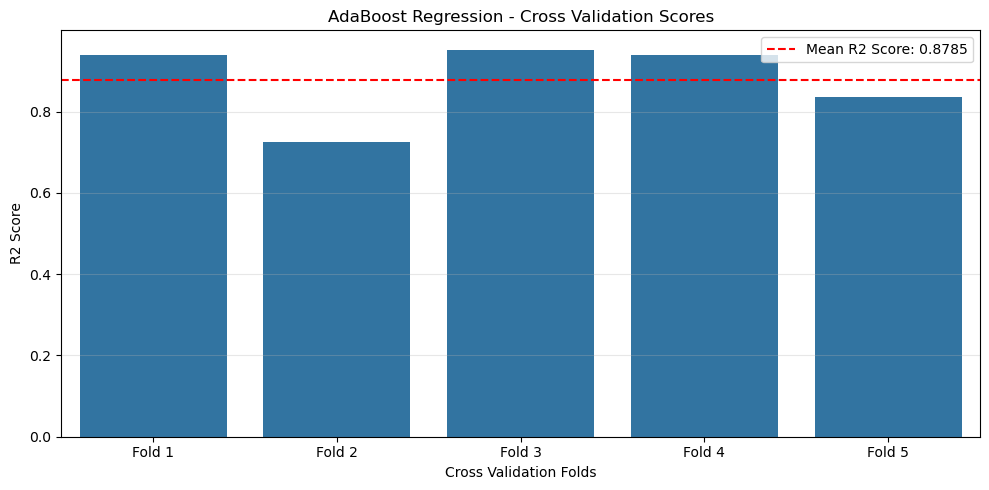

In [532]:
# Cross Validation
kf_ada = KFold(n_splits=5, shuffle=True, random_state=1)

cv_scores_ada = cross_val_score(
    ada_model,
    x_train,
    y_train,
    cv=kf_ada,
    scoring="r2"
)

# Create Evaluation DataFrame
cv_results_ada = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "R2 Score": cv_scores_ada
})

# Add Mean and Standard Deviation
cv_summary_ada = pd.DataFrame({
    "Fold": ["Mean", "Standard Deviation"],
    "R2 Score": [cv_scores_ada.mean(), cv_scores_ada.std()]
})

cv_results_ada = pd.concat(
    [cv_results_ada, cv_summary_ada],
    ignore_index=True
)

# Display DataFrame
display(
    cv_results_ada.style
    .format({"R2 Score": "{:.4f}"})
    .set_caption("AdaBoost Regression - Cross Validation")
    .background_gradient(cmap="Blues", subset=["R2 Score"])
    .hide(axis="index")
)

# Cross Validation Plot
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=[f"Fold {i}" for i in range(1, 6)],
    y=cv_scores_ada,
    ax=ax
)

ax.axhline(
    y=cv_scores_ada.mean(),
    color="red",
    linestyle="--",
    label=f"Mean R2 Score: {cv_scores_ada.mean():.4f}"
)

ax.set_title("AdaBoost Regression - Cross Validation Scores")
ax.set_xlabel("Cross Validation Folds")
ax.set_ylabel("R2 Score")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Visualization
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Data Visualization
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Data visualization is an essential step in data analysis that helps explore patterns, relationships, and distributions within the dataset. Visual representations such as histograms, scatter plots, box plots, and correlation heatmaps make it easier to identify trends, detect outliers, and better understand the characteristics of the data before building a machine learning model.

</p>

</div>

In [533]:
y_pred_ada = ada_model.predict(x_test)

df_comp_ada = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_ada,
    "loss": y_test - y_pred_ada
})

df_comp_ada

,Actual,Predicted,loss
142,0.60,0.735897,-0.135897
237,11.25,8.689592,2.560408
52,18.00,14.145510,3.854490
294,3.75,4.450909,-0.700909
246,3.75,4.089744,-0.339744
248,4.00,2.890909,1.109091
276,8.65,9.622800,-0.972800
63,23.50,21.375000,2.125000
28,1.95,2.595238,-0.645238
126,0.90,0.735897,0.164103


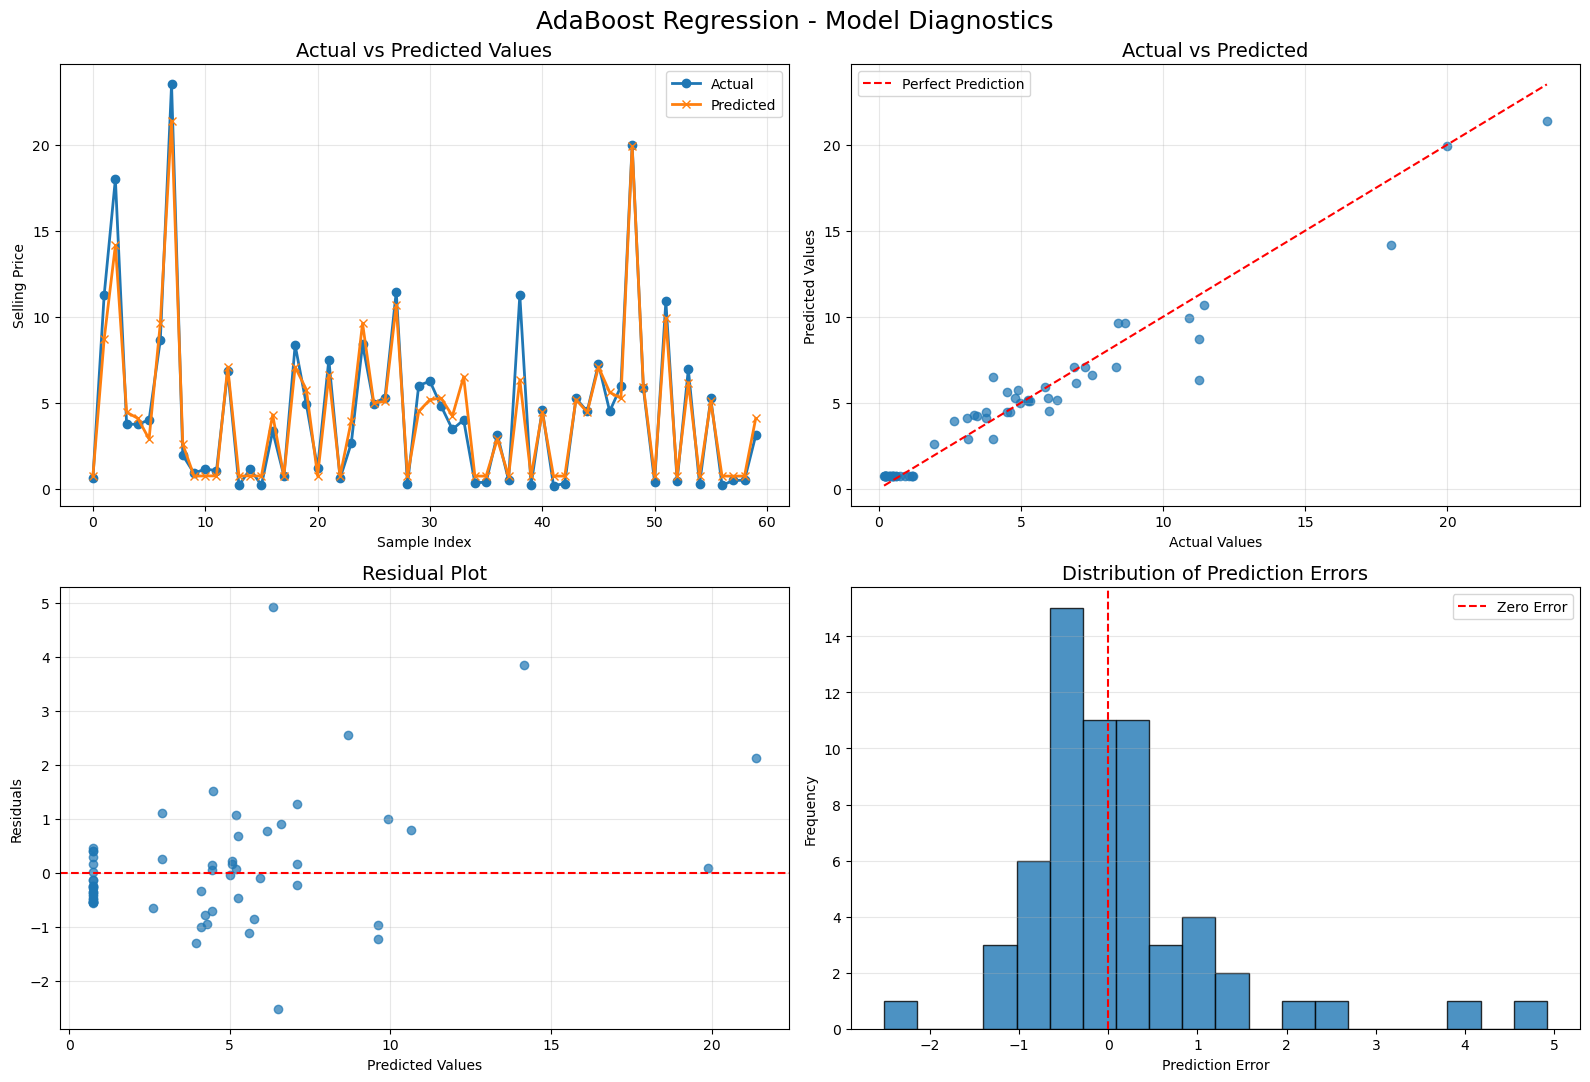

In [534]:
# Prepare Data
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_ada)
residuals_ada = actual - predicted
errors_ada = residuals_ada

# Create 2x2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Actual vs Predicted Values
axes[0, 0].plot(actual, label="Actual", marker="o", linewidth=2)
axes[0, 0].plot(predicted, label="Predicted", marker="x", linewidth=2)
axes[0, 0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Actual vs Predicted Scatter Plot
axes[0, 1].scatter(actual, predicted, alpha=0.7)
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())
axes[0, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)
axes[0, 1].set_title("Actual vs Predicted", fontsize=14)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(predicted, residuals_ada, alpha=0.7)
axes[1, 0].axhline(y=0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot", fontsize=14)
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].grid(alpha=0.3)

# 4. Distribution of Prediction Errors
axes[1, 1].hist(errors_ada, bins=20, edgecolor="black", alpha=0.8)
axes[1, 1].axvline(x=0, color="red", linestyle="--", label="Zero Error")
axes[1, 1].set_title("Distribution of Prediction Errors", fontsize=14)
axes[1, 1].set_xlabel("Prediction Error")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

# Overall Layout
fig.suptitle("AdaBoost Regression - Model Diagnostics", fontsize=18)
plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
KNN Regression
</h2>

<p style="color:#37474F; line-height:1.8;">
K-Nearest Neighbors (KNN) Regression is a supervised machine learning algorithm used to predict continuous numerical values. It estimates the target value by considering the values of the K nearest data points based on distance.
</p>

<p style="color:#37474F; line-height:1.8;">
In this project, KNN Regression is used to predict car selling prices based on the features of each vehicle.
</p>

</div>

In [503]:
x = data9.drop("Selling_Price", axis=1)
y = data9["Selling_Price"]

In [504]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [536]:
scaler_knn=StandardScaler()
x_train_scaled_knn=scaler_knn.fit_transform(x_train)
x_test_scaled_knn=scaler_knn.transform(x_test)

In [550]:
knn_model = KNeighborsRegressor( n_neighbors=4,weights="uniform", metric="minkowski")

In [551]:
knn_model.fit(x_train_scaled_knn, y_train)

,n_neighbors,4
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [552]:
y_pred_knn = knn_model.predict(x_test_scaled_knn)

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
KNN Model Evaluation
</h2>

<p style="color:#37474F; line-height:1.8;">
In this section, the performance of the KNN Regression model is evaluated using several regression metrics, including R² Score, Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).
</p>

<p style="color:#37474F; line-height:1.8;">
These metrics help measure how accurately the model predicts car selling prices and how close the predicted values are to the actual values.
</p>

</div>

Metric,Train,Test
R2 Score,0.9395,0.9048
MAE,0.6203,0.8735
MSE,1.2871,2.2733
RMSE,1.1345,1.5077


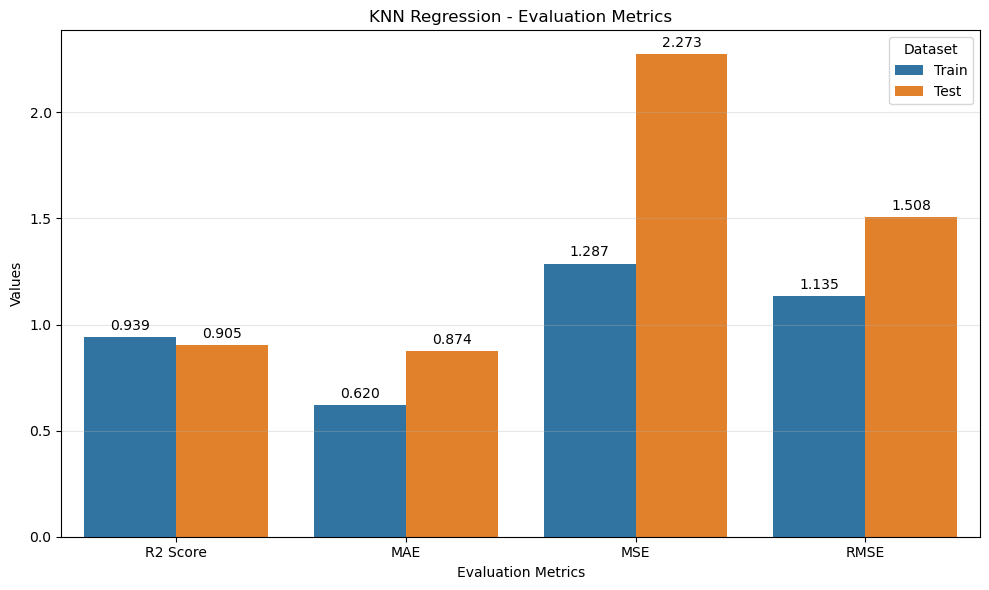

In [553]:
# Model Predictions
y_train_pred_knn = knn_model.predict(x_train_scaled_knn)
y_pred_knn = knn_model.predict(x_test_scaled_knn)


# Model Evaluation
evaluation_knn = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "Train": [
        r2_score(y_train, y_train_pred_knn),
        mean_absolute_error(y_train, y_train_pred_knn),
        mean_squared_error(y_train, y_train_pred_knn),
        np.sqrt(mean_squared_error(y_train, y_train_pred_knn))
    ],
    "Test": [
        r2_score(y_test, y_pred_knn),
        mean_absolute_error(y_test, y_pred_knn),
        mean_squared_error(y_test, y_pred_knn),
        np.sqrt(mean_squared_error(y_test, y_pred_knn))
    ]
})


# Display Evaluation Table
display(
    evaluation_knn.style
    .format({"Train": "{:.4f}", "Test": "{:.4f}"})
    .set_caption("KNN Regression - Model Evaluation")
    .background_gradient(cmap="Blues", subset=["Train", "Test"])
    .hide(axis="index")
)


# Evaluation Plot
fig, ax = plt.subplots(figsize=(10, 6))

plot_data_knn = evaluation_knn.melt(
    id_vars="Metric",
    var_name="Dataset",
    value_name="Score"
)

sns.barplot(
    data=plot_data_knn,
    x="Metric",
    y="Score",
    hue="Dataset",
    ax=ax
)

ax.set_title("KNN Regression - Evaluation Metrics")
ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Values")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Dataset")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

Fold,R2 Score
Fold 1,0.8689
Fold 2,0.8984
Fold 3,0.9492
Fold 4,0.9433
Fold 5,0.7614
Mean,0.8842
Standard Deviation,0.0682


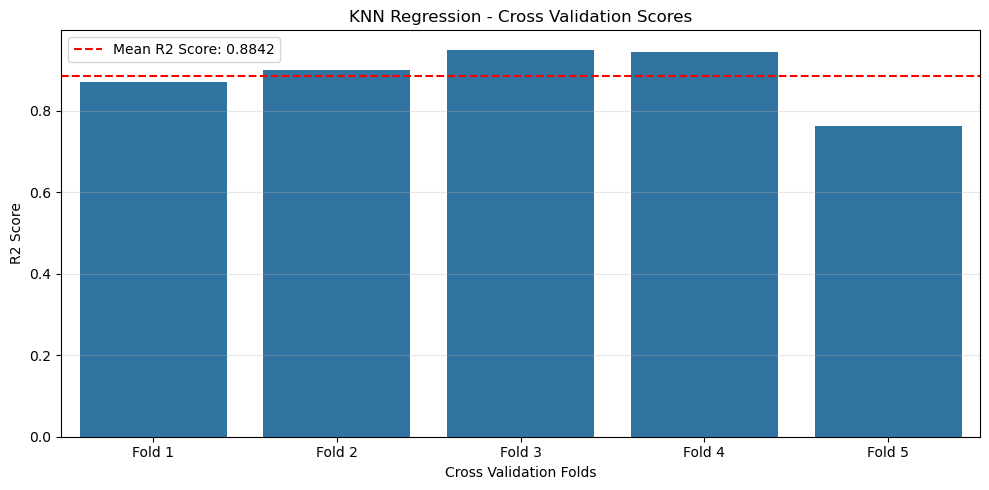

In [554]:
# Cross Validation
kf_knn = KFold(n_splits=5, shuffle=True, random_state=1)

cv_scores_knn = cross_val_score(
    knn_model,
    x_train_scaled_knn,
    y_train,
    cv=kf_knn,
    scoring="r2"
)

# Create Evaluation DataFrame
cv_results_knn = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "R2 Score": cv_scores_knn
})

# Add Mean and Standard Deviation
cv_summary_knn = pd.DataFrame({
    "Fold": ["Mean", "Standard Deviation"],
    "R2 Score": [cv_scores_knn.mean(), cv_scores_knn.std()]
})

cv_results_knn = pd.concat(
    [cv_results_knn, cv_summary_knn],
    ignore_index=True
)

# Display DataFrame
display(
    cv_results_knn.style
    .format({"R2 Score": "{:.4f}"})
    .set_caption("KNN Regression - Cross Validation")
    .background_gradient(cmap="Blues", subset=["R2 Score"])
    .hide(axis="index")
)

# Cross Validation Plot
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x=[f"Fold {i}" for i in range(1, 6)],
    y=cv_scores_knn,
    ax=ax
)

ax.axhline(
    y=cv_scores_knn.mean(),
    color="red",
    linestyle="--",
    label=f"Mean R2 Score: {cv_scores_knn.mean():.4f}"
)

ax.set_title("KNN Regression - Cross Validation Scores")
ax.set_xlabel("Cross Validation Folds")
ax.set_ylabel("R2 Score")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

<div style="
background-color:#E3F2F9;
padding:20px;
border-radius:12px;
border-left:8px solid #42A5F5;
">

<h2 style="color:#1565C0; margin-bottom:15px;">
📊 Data Visualization
</h2>

<h3 style="color:#1976D2; margin-bottom:10px;">
➤ Data Visualization
</h3>

<p style="
font-size:16px;
line-height:1.8;
">

Data visualization is an essential step in data analysis that helps explore patterns, relationships, and distributions within the dataset. Visual representations such as histograms, scatter plots, box plots, and correlation heatmaps make it easier to identify trends, detect outliers, and better understand the characteristics of the data before building a machine learning model.

</p>

</div>

In [555]:
# Actual vs Predicted Comparison
y_pred_knn = knn_model.predict(x_test_scaled_knn)

df_comp_knn = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_knn,
    "loss": y_test - y_pred_knn
})

df_comp_knn

,Actual,Predicted,loss
142,0.60,1.0100,-0.4100
237,11.25,9.2000,2.0500
52,18.00,24.9375,-6.9375
294,3.75,4.1750,-0.4250
246,3.75,3.7500,0.0000
248,4.00,2.3875,1.6125
276,8.65,9.6250,-0.9750
63,23.50,22.3125,1.1875
28,1.95,2.1175,-0.1675
126,0.90,0.9450,-0.0450


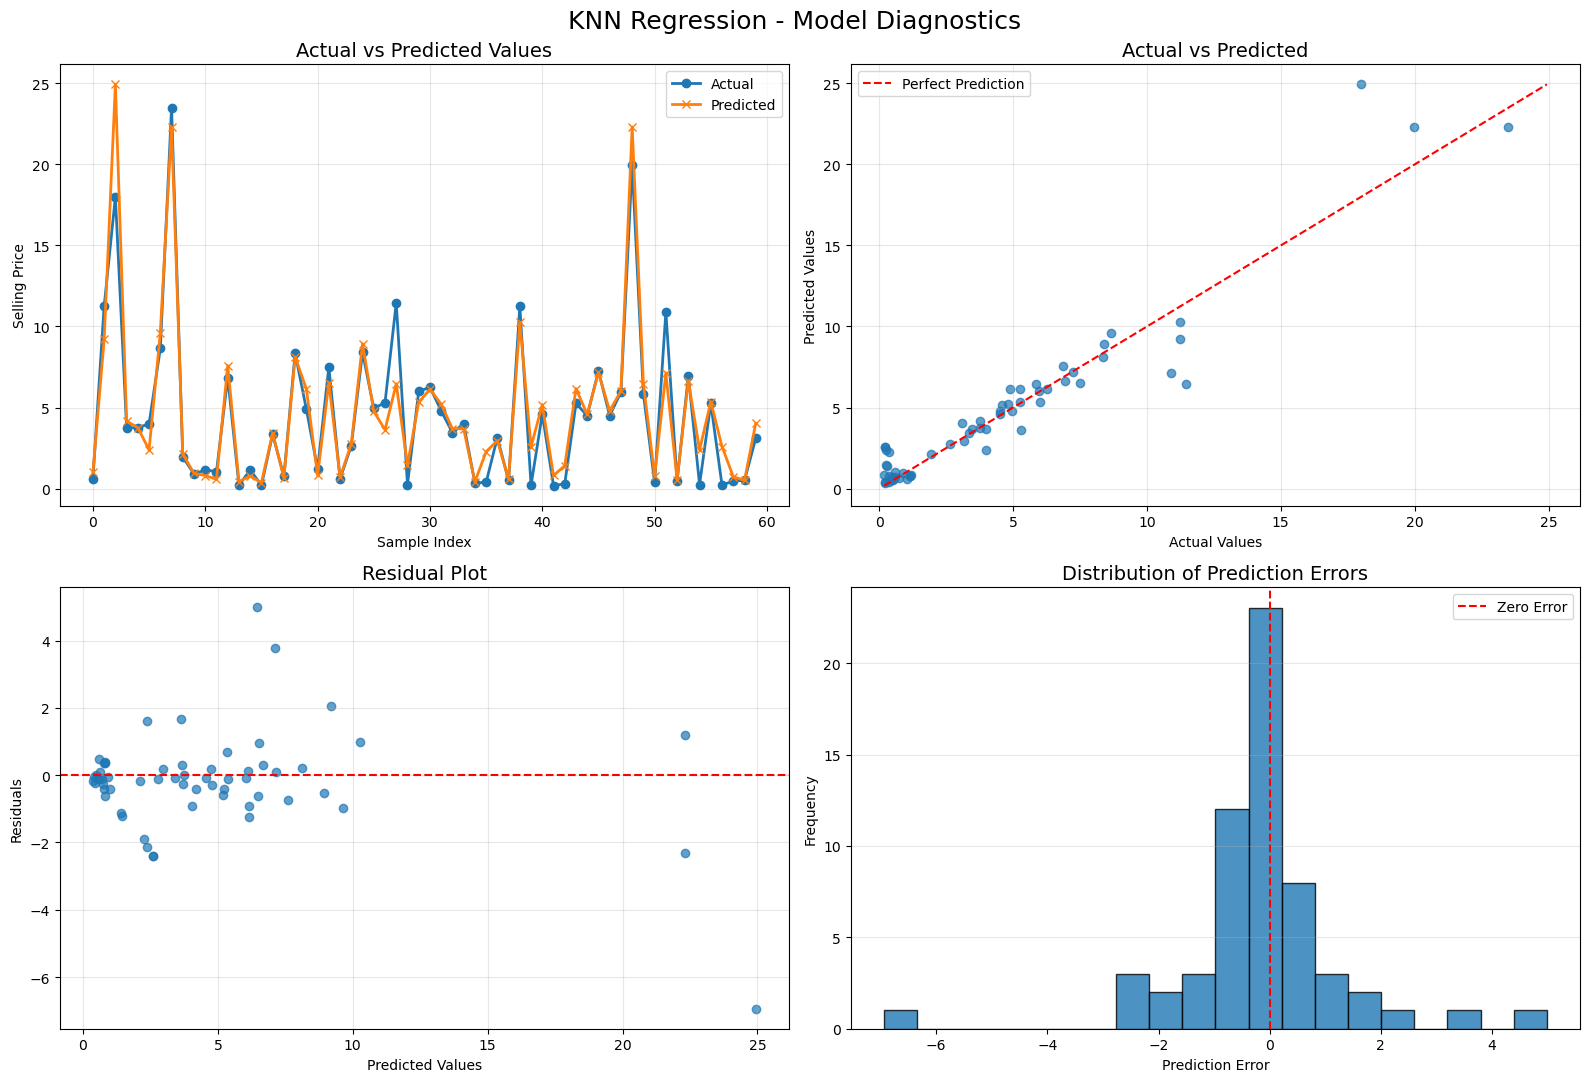

In [556]:
# Prepare Data
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_knn)
residuals_knn = actual - predicted
errors_knn = residuals_knn

# Create 2x2 Subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Actual vs Predicted Values
axes[0, 0].plot(actual, label="Actual", marker="o", linewidth=2)
axes[0, 0].plot(predicted, label="Predicted", marker="x", linewidth=2)
axes[0, 0].set_title("Actual vs Predicted Values", fontsize=14)
axes[0, 0].set_xlabel("Sample Index")
axes[0, 0].set_ylabel("Selling Price")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Actual vs Predicted Scatter Plot
axes[0, 1].scatter(actual, predicted, alpha=0.7)
min_val = min(actual.min(), predicted.min())
max_val = max(actual.max(), predicted.max())
axes[0, 1].plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)
axes[0, 1].set_title("Actual vs Predicted", fontsize=14)
axes[0, 1].set_xlabel("Actual Values")
axes[0, 1].set_ylabel("Predicted Values")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Residual Plot
axes[1, 0].scatter(predicted, residuals_knn, alpha=0.7)
axes[1, 0].axhline(y=0, color="red", linestyle="--")
axes[1, 0].set_title("Residual Plot", fontsize=14)
axes[1, 0].set_xlabel("Predicted Values")
axes[1, 0].set_ylabel("Residuals")
axes[1, 0].grid(alpha=0.3)

# 4. Distribution of Prediction Errors
axes[1, 1].hist(errors_knn, bins=20, edgecolor="black", alpha=0.8)
axes[1, 1].axvline(x=0, color="red", linestyle="--", label="Zero Error")
axes[1, 1].set_title("Distribution of Prediction Errors", fontsize=14)
axes[1, 1].set_xlabel("Prediction Error")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].legend()
axes[1, 1].grid(axis="y", alpha=0.3)

# Overall Layout
fig.suptitle("KNN Regression - Model Diagnostics", fontsize=18)
plt.tight_layout()
plt.show()

In [562]:

from IPython.display import display, HTML

# Collect Model Evaluation Results
model_results = {
    "Linear Regression": evaluation,
    "Polynomial Regression": evaluation_poly,
    "Ridge Regression": evaluation_ridge,
    "Lasso Regression": evaluation_lasso,
    "ElasticNet Regression": evaluation_elastic,
    "Decision Tree": evaluation_dtr,
    "Random Forest": evaluation_rf,
    "AdaBoost": evaluation_ada,
    "KNN": evaluation_knn,
    "SVR": evaluation_svr
}


# Create Comparison Table
comparison_data = []

for model_name, evaluation_result in model_results.items():

    train_values = evaluation_result.set_index("Metric")["Train"]
    test_values = evaluation_result.set_index("Metric")["Test"]

    comparison_data.append({
        "Model": model_name,
        "R2 Train": train_values["R2 Score"],
        "R2 Test": test_values["R2 Score"],
        "MAE Test": test_values["MAE"],
        "MSE Test": test_values["MSE"],
        "RMSE Test": test_values["RMSE"]
    })

comparison_df = pd.DataFrame(comparison_data)


# Find Best Models
best_r2_model = comparison_df.loc[
    comparison_df["R2 Test"].idxmax()
]

best_mae_model = comparison_df.loc[
    comparison_df["MAE Test"].idxmin()
]

best_mse_model = comparison_df.loc[
    comparison_df["MSE Test"].idxmin()
]

best_rmse_model = comparison_df.loc[
    comparison_df["RMSE Test"].idxmin()
]


# Convert Comparison Table to HTML
table_html = comparison_df.round(4).to_html(
    index=False,
    border=0,
    classes="comparison-table"
)


# Display HTML Report
html_code = f"""
<div style="
    font-family:Segoe UI,Tahoma,sans-serif;
    background:#f7f9fc;
    border:1px solid #d9e2ef;
    border-radius:16px;
    padding:25px;
    color:#263445;
    line-height:1.8;
">

    <div style="
        background:#e3ebf7;
        border-left:6px solid #5279ad;
        border-radius:10px;
        padding:18px 22px;
        margin-bottom:22px;
    ">

        <h2 style="color:#234f85; margin:0 0 8px;">
            Regression Model Evaluation and Comparison
        </h2>

        <p style="margin:0; color:#405570;">
            In this project, ten regression models were developed
            and evaluated to predict car selling prices.
            Their performance was compared using R² Score,
            Mean Absolute Error (MAE), Mean Squared Error (MSE),
            and Root Mean Squared Error (RMSE).
        </p>

    </div>

    <h3 style="color:#315b8a;">
        Evaluation Results
    </h3>

    {table_html}

    <style>
        .comparison-table {{
            width:100%;
            border-collapse:collapse;
            background:white;
            font-size:13px;
            text-align:center;
        }}

        .comparison-table th {{
            background:#5279ad;
            color:white;
            padding:12px 8px;
        }}

        .comparison-table td {{
            padding:10px 8px;
            border-bottom:1px solid #e1e8f0;
        }}

        .comparison-table tr:nth-child(even) {{
            background:#f2f6fb;
        }}
    </style>

    <div style="
        margin-top:24px;
        background:#e8f3e8;
        border-left:6px solid #6b9b6b;
        border-radius:10px;
        padding:17px 20px;
    ">

        <h3 style="color:#356b43; margin:0 0 8px;">
            Key Findings
        </h3>

        <ul style="margin:0; padding-left:22px;">

            <li>
                <b>Best R² Score:</b>
                {best_r2_model['Model']}
                ({best_r2_model['R2 Test']:.4f})
            </li>

            <li>
                <b>Lowest MAE:</b>
                {best_mae_model['Model']}
                ({best_mae_model['MAE Test']:.4f})
            </li>

            <li>
                <b>Lowest MSE:</b>
                {best_mse_model['Model']}
                ({best_mse_model['MSE Test']:.4f})
            </li>

            <li>
                <b>Lowest RMSE:</b>
                {best_rmse_model['Model']}
                ({best_rmse_model['RMSE Test']:.4f})
            </li>

        </ul>

    </div>

    <div style="
        margin-top:20px;
        background:#fff4df;
        border-left:6px solid #d5a34d;
        border-radius:10px;
        padding:17px 20px;
    ">

        <h3 style="color:#8a6324; margin:0 0 8px;">
            Overall Conclusion
        </h3>

        <p style="margin:0;">
            The regression models were compared based on their
            predictive performance on the test dataset.
            A higher R² Score indicates a better fit, while lower
            MAE, MSE, and RMSE values indicate smaller prediction
            errors. The final model should be selected by considering
            all evaluation metrics and the difference between
            training and testing performance to identify possible
            overfitting and choose a reliable model for car
            selling price prediction.
        </p>

    </div>

    <p style="
        margin:18px 0 0;
        color:#68788b;
        font-size:12px;
        text-align:center;
    ">
        Car Selling Price Prediction | Regression Model Comparison
    </p>

</div>
"""

# Display Final Report
display(HTML(html_code))


Model,R2 Train,R2 Test,MAE Test,MSE Test,RMSE Test
Linear Regression,0.9801,0.9766,0.5043,0.5598,0.7482
Polynomial Regression,0.9801,0.9766,0.5043,0.5598,0.7482
Ridge Regression,0.8762,0.8922,1.1550,2.5750,1.6047
Lasso Regression,0.8739,0.8812,1.1825,2.8357,1.6840
ElasticNet Regression,0.8736,0.8822,1.1834,2.8119,1.6769
Decision Tree,0.9821,0.9482,0.6711,1.2377,1.1125
Random Forest,0.9830,0.9694,0.5228,0.7306,0.8548
AdaBoost,0.9614,0.9443,0.7533,1.3296,1.1531
KNN,0.9395,0.9048,0.8735,2.2733,1.5077
SVR,0.7069,0.7136,1.2305,6.8383,2.6150
